# Exploratory Data Analysis: Predicting News-Article Popularity (`shares`)

**Goal of the project:** predict the number of social-media shares of a news article from its content, metadata and keyword features.
**Goal of this notebook:** understand the data well enough to make informed preprocessing, feature-engineering and modelling decisions. Every number and plot below was produced by executing the code in this notebook.

**Contents**
1. Data overview
2. Data quality
3. Descriptive statistics
4. Univariate analysis
5. Bivariate analysis (Pearson, Spearman, categorical association, non-monotonic tests)
6. Categorical effect sizes
7. Interaction of categorical features
8. Outlier analysis
9. Feature engineering
10. Synthesis (data findings) and modelling implications
11. Data cleaning
12. Feature engineering (scikit-learn transformers)
13. Train / validation / test split (70/15/15)
14. Preprocessing pipeline
15. Model registry
16. Baseline fitting (default hyper-parameters)
17. Closing summary of baseline results
18. Plan for tuning and final evaluation (written at the end of Phase 1B)
19. Hyper-parameter tuning setup: compute budget, search spaces, checkpoint ledger
20. Tuning linear models (GridSearchCV)
21. Tuning slower models (HalvingRandomSearchCV on a subsample, refit on the full training split)
22. Tuned versus baseline models (validation split)
23. Final model selection and the one-time test-set evaluation
24. Sensitivity checks (validation data only)
25. Closing summary and saved outputs (`./outputs`)
26. Glossary

Sections 1-10 are the exploratory analysis; sections 11-25 form a self-contained, leak-free modelling workflow that starts again from the raw CSV.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from sklearn.feature_selection import mutual_info_regression

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.width', 220, 'display.max_columns', 80, 'display.max_rows', 120,
              'display.float_format', lambda x: f'{x:,.4f}')
RNG = np.random.default_rng(42)

TARGET = 'shares'
df = pd.read_csv('data/mini_project_1_data.csv')
df['log_shares'] = np.log1p(df[TARGET])
df['channel'] = df['data_channel'].fillna('Unknown')
DAYS = ['monday','tuesday','wednesday','thursday','friday','saturday','sunday']
CAT_COLS = ['weekday', 'data_channel']
num_cols = [c for c in df.select_dtypes('number').columns if c not in ('ID', TARGET, 'log_shares')]

def rank_biserial(a, b):
    """Mann-Whitney U based effect size in [-1, 1] (= Cliff's delta) and p-value."""
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    return 2 * u / (len(a) * len(b)) - 1, p

def eta_squared(y, groups):
    """Share of variance in y explained by group membership (SS_between / SS_total)."""
    d = pd.DataFrame({'y': y, 'g': groups}).dropna()
    ssb = d.groupby('g', observed=True).y.apply(lambda s: len(s) * (s.mean() - d.y.mean()) ** 2).sum()
    return ssb / ((d.y - d.y.mean()) ** 2).sum()

def binned_profile(x, y, q=10):
    d = pd.DataFrame({'x': x, 'y': y}).dropna()
    try:
        b = pd.qcut(d.x, q, duplicates='drop')
    except ValueError:
        return None
    g = d.groupby(b, observed=True).agg(x_med=('x', 'median'), y_mean=('y', 'mean'), y_sd=('y', 'std'), n=('y', 'size'))
    g['se'] = g.y_sd / np.sqrt(g.n)
    return g

print('Loaded', df.shape, '| numeric features:', len(num_cols), '| categorical features:', CAT_COLS)

Loaded (35680, 32) | numeric features: 25 | categorical features: ['weekday', 'data_channel']


**Observation:** The file loads as 35,680 rows. Besides the 30 original columns I added `log_shares` (= log1p of the target) and `channel` (`data_channel` with NaN labelled *Unknown*). `ID` and the target are excluded from the 25 numeric predictors; two categorical predictors (`weekday`, `data_channel`) plus the `URL` string remain.

## 1. Data overview

In [2]:
print('Shape (rows, columns):', df[[c for c in df.columns if c not in ('log_shares','channel')]].shape)
info = pd.DataFrame({'dtype': df.dtypes.astype(str), 'n_unique': df.nunique(), 'n_missing': df.isna().sum()}).drop(['log_shares','channel'])
display(info)
display(df.drop(columns=['log_shares','channel']).head().T)

Shape (rows, columns): (35680, 30)


,dtype,n_unique,n_missing
ID,int64,35680,0
URL,str,35680,0
timedelta,float64,724,0
weekday,str,7,0
shares,int64,1418,0
n_tokens_title,float64,20,0
n_tokens_content,float64,2324,0
n_unique_tokens,float64,25197,0
n_non_stop_words,float64,1429,0
n_non_stop_unique_tokens,float64,21345,0


,0,1,2,3,4
ID,0,1,2,3,4
URL,http://mashable.com/2013/01/07/amazon-instant-...,http://mashable.com/2013/01/07/ap-samsung-spon...,http://mashable.com/2013/01/07/apple-40-billio...,http://mashable.com/2013/01/07/astronaut-notre...,http://mashable.com/2013/01/07/att-u-verse-apps/
timedelta,731.0000,731.0000,731.0000,731.0000,731.0000
weekday,monday,monday,monday,monday,monday
shares,593,711,1500,1200,505
n_tokens_title,12.0000,9.0000,9.0000,9.0000,13.0000
n_tokens_content,219.0000,255.0000,211.0000,531.0000,"1,072.0000"
n_unique_tokens,0.6636,0.6047,0.5751,0.5038,0.4156
n_non_stop_words,1.0000,1.0000,1.0000,1.0000,1.0000
n_non_stop_unique_tokens,0.8154,0.7919,0.6639,0.6656,0.5409


**Observation:** 35,680 articles × 30 columns: 25 numeric features (all stored as float except `ID`, `shares`), 2 categorical (`weekday`, `data_channel`), the `URL` text, an `ID`, and the target `shares`. Several count columns (`num_hrefs`, `num_imgs`, `num_videos`…) are floats only because they contain NaN. Eight columns have missing values (largest: `num_videos`, `data_channel`).

**Problem type:** supervised **regression** on a non-negative integer target (`shares`). The columns match the well-known Mashable online-news-popularity data: text statistics, link/media counts, keyword-popularity statistics (`kw_*`), publication day, and topic channel. There are no class labels, so there is no class-balance question; if one binarised at the median the classes would be about balanced by construction.

count    35,680.0000
mean      3,402.0550
std      11,934.8785
min           4.0000
1%          381.0000
5%          584.9500
25%         946.0000
50%       1,400.0000
75%       2,800.0000
90%       6,200.0000
95%      10,800.0000
99%      32,000.0000
max     843,300.0000

skewness raw = 34.41 | skewness log1p = 1.04
kurtosis raw = 1828.0 | kurtosis log1p = 2.36
mean/median = 2.43
Target is integer-valued: True | n unique values: 1418
If binarised at the median (1400): share >= median = 53.3%


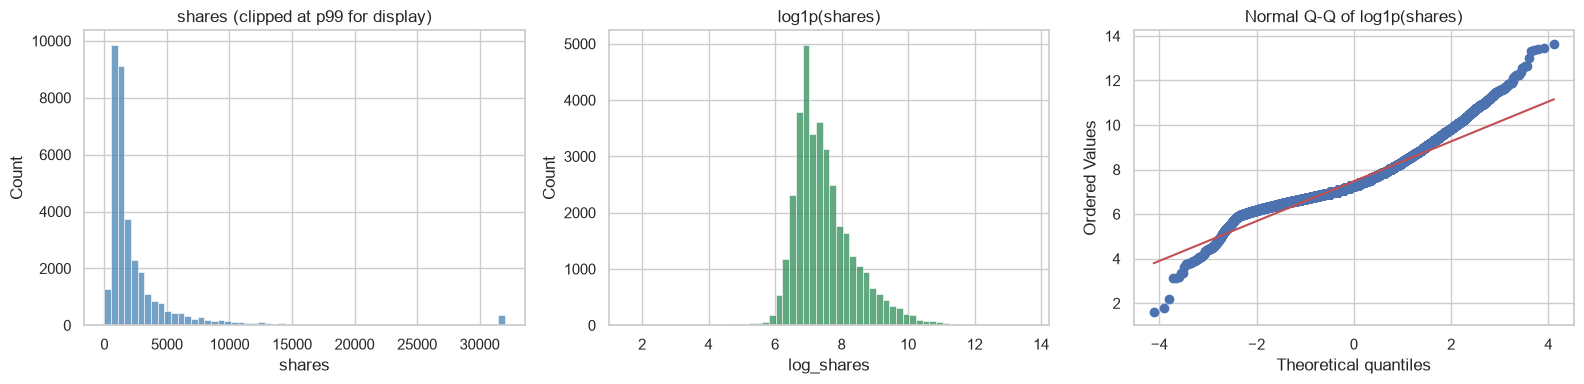

In [3]:
y = df[TARGET]
print(y.describe(percentiles=[.01,.05,.25,.5,.75,.9,.95,.99]).to_string())
print(f'\nskewness raw = {y.skew():.2f} | skewness log1p = {df.log_shares.skew():.2f}')
print(f'kurtosis raw = {y.kurt():.1f} | kurtosis log1p = {df.log_shares.kurt():.2f}')
print(f'mean/median = {y.mean()/y.median():.2f}')
print(f'Target is integer-valued: {(y == y.round()).all()} | n unique values: {y.nunique()}')
print(f'If binarised at the median ({y.median():.0f}): share >= median = {(y >= y.median()).mean():.1%}')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(y.clip(upper=y.quantile(.99)), bins=60, ax=ax[0], color='steelblue'); ax[0].set_title('shares (clipped at p99 for display)')
sns.histplot(df.log_shares, bins=60, ax=ax[1], color='seagreen'); ax[1].set_title('log1p(shares)')
stats.probplot(df.log_shares, dist='norm', plot=ax[2]); ax[2].set_title('Normal Q-Q of log1p(shares)')
plt.tight_layout(); plt.show()

**Observation:** `shares` is extremely right-skewed: median 1,400 but mean 3,402 (mean/median = 2.4), skewness 34.4, excess kurtosis 1,828, and a maximum of 843,300 (about 600× the median). The 99th percentile is only 32,000, so a handful of articles sit far outside everything else. After `log1p` the skewness falls to 1.04 and excess kurtosis to 2.4: the log scale is far better behaved, still mildly right-skewed with tails heavier than a normal (excess kurtosis > 0).

**Implication for the data:** any statistic computed on raw `shares` (Pearson, means, R², RMSE) is dominated by a few hundred articles; statistics on the log scale describe the typical article. I therefore report both throughout. The target is integer-valued with 1,418 distinct values.

## 2. Data quality
Each check below is actually run; nothing is assumed clean.

In [4]:
miss = df[[c for c in df.columns if c not in ('log_shares','channel')]].isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
display(pd.DataFrame({'n_missing': miss, 'pct_missing': (miss / len(df) * 100).round(2)}))

print('Co-missing patterns (1 = missing) across the columns that have any NaN:')
patt = df[miss.index].isna().astype(int)
pat_counts = patt.value_counts().rename('rows').reset_index()
display(pat_counts)

print('Are the rows with missing num_hrefs the empty-content articles?')
display(pd.crosstab(df.num_hrefs.isna(), df.n_tokens_content == 0, rownames=['num_hrefs missing'], colnames=['content empty (0 tokens)']))

,n_missing,pct_missing
num_videos,16755,46.9600
data_channel,5462,15.3100
num_imgs,1419,3.9800
num_self_hrefs,721,2.0200
num_hrefs,721,2.0200
self_reference_min_shares,721,2.0200
self_reference_max_shares,721,2.0200
self_reference_avg_shares,721,2.0200


Co-missing patterns (1 = missing) across the columns that have any NaN:


,num_videos,data_channel,num_imgs,num_self_hrefs,num_hrefs,self_reference_min_shares,self_reference_max_shares,self_reference_avg_shares,rows
0,0,0,0,0,0,0,0,0,15085
1,1,0,0,0,0,0,0,0,13396
2,0,1,0,0,0,0,0,0,2746
3,1,1,0,0,0,0,0,0,2345
4,0,0,1,0,0,0,0,0,602
5,1,0,1,0,0,0,0,0,544
6,0,0,0,1,1,1,1,1,296
7,1,0,0,1,1,1,1,1,268
8,0,1,1,0,0,0,0,0,124
9,1,1,1,0,0,0,0,0,117


Are the rows with missing num_hrefs the empty-content articles?


content empty (0 tokens),False,True
num_hrefs missing,,
False,33919,1040
True,700,21


**Observation:** Missing values exist in 8 of 30 columns and are concentrated in a few blocks:
- `num_videos`: 46.96% missing (16,755 rows).
- `data_channel`: 15.31% missing (5,462 rows).
- `num_imgs`: 3.98% missing (1,419 rows).
- A **block of 721 rows (2.02%)** where `num_hrefs`, `num_self_hrefs` and all three `self_reference_*` columns are missing *together* (the co-missing table shows these five always go missing as one unit). That block is nearly unrelated to the 1,061 empty-content articles (only 21 rows overlap), so it is a separate extraction failure, not "articles with no text".
- `num_videos` and `data_channel` go missing roughly independently of each other (joint NaN rate ≈ 7.1% vs 0.47 × 0.153 ≈ 7.2% expected under independence).

In [5]:
# Is missingness informative about the target? (compare shares for missing vs present)
rows = []
for c in miss.index:
    m = df[c].isna()
    rb, p = rank_biserial(df.loc[m, 'log_shares'], df.loc[~m, 'log_shares'])
    rows.append(dict(column=c, n_missing=m.sum(), median_shares_missing=df.loc[m, TARGET].median(),
                     median_shares_present=df.loc[~m, TARGET].median(), rank_biserial=rb, p_value=p))
display(pd.DataFrame(rows).set_index('column'))

# num_videos: NaN vs 0 vs >0
vstat = np.where(df.num_videos.isna(), 'NaN', np.where(df.num_videos == 0, '0', '>0'))
display(df.groupby(vstat)[TARGET].agg(n='size', median='median', mean='mean', geo_mean=lambda s: np.expm1(np.log1p(s).mean())))

# Does missingness of num_videos depend on other columns? (MCAR check)
nv = df.num_videos.isna()
print('\nnum_videos NaN rate by channel:'); display((nv.groupby(df.channel).mean() * 100).round(1).to_frame('pct_nan'))
print('num_videos NaN rate by timedelta quartile:'); display((nv.groupby(pd.qcut(df.timedelta, 4)).mean() * 100).round(1).to_frame('pct_nan'))
print('num_videos NaN rate by weekday:'); display((nv.groupby(df.weekday).mean() * 100).round(1).to_frame('pct_nan'))

,n_missing,median_shares_missing,median_shares_present,rank_biserial,p_value
column,,,,,
num_videos,16755,"1,400.0000","1,400.0000",-0.0024,0.6992
data_channel,5462,"1,900.0000","1,400.0000",0.2047,0.0000
num_imgs,1419,"1,500.0000","1,400.0000",0.0151,0.3345
num_self_hrefs,721,"1,500.0000","1,400.0000",0.0337,0.1207
num_hrefs,721,"1,500.0000","1,400.0000",0.0337,0.1207
self_reference_min_shares,721,"1,500.0000","1,400.0000",0.0337,0.1207
self_reference_max_shares,721,"1,500.0000","1,400.0000",0.0337,0.1207
self_reference_avg_shares,721,"1,500.0000","1,400.0000",0.0337,0.1207


,n,median,mean,geo_mean
0,11894,"1,400.0000","2,822.2792","1,671.9372"
>0,7031,"1,500.0000","4,281.5740","1,927.8469"
NaN,16755,"1,400.0000","3,444.5470","1,764.0639"



num_videos NaN rate by channel:


,pct_nan
channel,
Unknown,46.3000
business,46.0000
entertainment,45.6000
lifestyle,46.7000
social_media,44.8000
technology,48.9000
world,48.2000


num_videos NaN rate by timedelta quartile:


,pct_nan
timedelta,
"(7.999, 163.0]",46.4000
"(163.0, 339.0]",47.4000
"(339.0, 543.0]",47.0000
"(543.0, 731.0]",47.0000


num_videos NaN rate by weekday:


,pct_nan
weekday,
friday,46.9000
monday,46.8000
saturday,46.7000
sunday,47.4000
thursday,47.0000
tuesday,47.3000
wednesday,46.7000


**Observation:** Is missingness informative?
- `num_videos` (47% NaN): median shares for NaN rows = 1,400 = median for observed rows; rank-biserial −0.002 (p = 0.70); and the NaN rate is flat across channel (44.8–48.9%), time quartile (46.4–47.4%) and weekday (46.7–47.4%). This looks like missing-at-random: **no evidence the NaN carries information**. NaN rows have a geometric-mean share of 1,764, between the "0 videos" group (1,672) and the ">0 videos" group (1,928). Only the observed count matters: articles with ≥1 video have a geo-mean ~15% above those with 0 (median 1,500 vs 1,400), a small effect.
- `data_channel` (15% NaN): informative. NaN rows have median 1,900 vs 1,400 for the rest (rank-biserial 0.20, p ≈ 0). They behave like a distinct group (probably "other/uncategorised"), not random holes.
- `num_imgs` and the 721-row block: no detectable difference (p = 0.33 and 0.12); missing flags would carry essentially no signal.

In [6]:
feat = [c for c in df.columns if c not in ('ID','URL','log_shares','channel')]
raw = df.drop(columns=['log_shares','channel'])
slug = df.URL.str.extract(r'/\d{4}/\d{2}/\d{2}/([^/]+)/?$')[0]
checks = {
 'fully duplicated rows': raw.duplicated().sum(),
 'duplicated ID': df.ID.duplicated().sum(),
 'duplicated URL': df.URL.duplicated().sum(),
 'duplicated URL slug (same article, other date?)': slug.duplicated().sum(),
 'duplicated feature vectors ignoring ID/URL': raw[feat].duplicated().sum(),
 'duplicated feature vectors ignoring ID/URL/shares': raw[[c for c in feat if c != TARGET]].duplicated().sum(),
}
display(pd.Series(checks, name='count').to_frame())
print('ID range:', df.ID.min(), '-', df.ID.max(), '| rows:', len(df), '| IDs absent from range:', df.ID.max() + 1 - len(df))
print('ID monotonic increasing:', df.ID.is_monotonic_increasing)

,count
fully duplicated rows,0
duplicated ID,0
duplicated URL,0
"duplicated URL slug (same article, other date?)",0
duplicated feature vectors ignoring ID/URL,0
duplicated feature vectors ignoring ID/URL/shares,0


ID range: 0 - 39643 | rows: 35680 | IDs absent from range: 3964
ID monotonic increasing: True


**Observation:** No duplicates of any kind: no repeated rows, IDs, URLs or URL slugs, and no repeated feature vectors (with or without `shares`). `ID` runs 0 to 39,643 but only 35,680 rows are present, so 3,964 IDs (~10%) are absent: this file is a subset (probably a train split) of a larger set. Rows are sorted by ID and ID is almost a perfect reverse clock: Spearman(ID, `timedelta`) = −0.99999 (the first rows are the oldest articles, `timedelta` 731 days; the last the newest, 8 days). So `ID` encodes publication time (same information as `timedelta`) and must not be treated as an anonymous key; a random split mixes eras, a split by `ID` is a time split.

In [7]:
# Casing / whitespace / mixed-type checks
for c in CAT_COLS:
    s = df[c].dropna()
    print(f'{c}: raw unique = {sorted(s.unique())}')
    print(f'   after strip+lower unique count = {s.str.strip().str.lower().nunique()} vs raw {s.nunique()} -> inconsistencies: {s.nunique() != s.str.strip().str.lower().nunique()}')
    print(f'   values with leading/trailing whitespace: {(s != s.str.strip()).sum()}')
print()
types = {c: df[c].map(type).nunique() for c in df.columns}
print('Columns holding more than one Python type (mixed types):', [c for c, n in types.items() if n > 1] or 'none')
print('Object columns:', list(df.select_dtypes(['object','string']).columns))
pat = r'^http://mashable\.com/\d{4}/\d{2}/\d{2}/[^/]+/$'
print('URLs matching http://mashable.com/YYYY/MM/DD/slug/ :', df.URL.str.match(pat).mean())

# integer-valued count columns stored as float? any non-integers?
cnt_cols = ['n_tokens_title','n_tokens_content','num_hrefs','num_self_hrefs','num_imgs','num_videos','n_comments','num_keywords','timedelta']
print('\nNon-integer values in count-like columns:')
print({c: int(((df[c].dropna() % 1) != 0).sum()) for c in cnt_cols})

weekday: raw unique = ['friday', 'monday', 'saturday', 'sunday', 'thursday', 'tuesday', 'wednesday']
   after strip+lower unique count = 7 vs raw 7 -> inconsistencies: False
   values with leading/trailing whitespace: 0
data_channel: raw unique = ['business', 'entertainment', 'lifestyle', 'social_media', 'technology', 'world']
   after strip+lower unique count = 6 vs raw 6 -> inconsistencies: False
   values with leading/trailing whitespace: 0



Columns holding more than one Python type (mixed types): ['data_channel']
Object columns: ['URL', 'weekday', 'data_channel', 'channel']
URLs matching http://mashable.com/YYYY/MM/DD/slug/ : 1.0

Non-integer values in count-like columns:
{'n_tokens_title': 0, 'n_tokens_content': 0, 'num_hrefs': 0, 'num_self_hrefs': 0, 'num_imgs': 0, 'num_videos': 0, 'n_comments': 0, 'num_keywords': 0, 'timedelta': 0}


**Observation:**
- **Casing / whitespace:** none. `weekday` has exactly 7 clean lower-case levels and `data_channel` 6, with no leading/trailing spaces and no case variants.
- **Mixed types:** the check flags `data_channel`, but that is only because NaN (a float) sits among strings; there are no genuinely mixed-type columns.
- **Count-like columns are integer-valued** even though stored as floats (zero non-integers), so they can be safely cast after imputation.
- **URLs** all follow `http://mashable.com/YYYY/MM/DD/slug/`, so publication date and a slug are derivable.

In [8]:
d = df
checks = {
 'shares <= 0': d[TARGET] <= 0,
 'negative count/length values (any count col)': (d[cnt_cols + ['average_token_length']] < 0).any(axis=1),
 'n_tokens_title == 0': d.n_tokens_title == 0,
 'n_tokens_content == 0 (empty article)': d.n_tokens_content == 0,
 '  ...of which n_unique_tokens==0 as well': (d.n_tokens_content == 0) & (d.n_unique_tokens == 0),
 '  ...of which average_token_length==0 as well': (d.n_tokens_content == 0) & (d.average_token_length == 0),
 'ratio columns outside [0,1]': ((d[['n_unique_tokens','n_non_stop_words','n_non_stop_unique_tokens']] > 1) | (d[['n_unique_tokens','n_non_stop_words','n_non_stop_unique_tokens']] < 0)).any(axis=1),
 'n_unique_tokens == 0 with content > 0': (d.n_unique_tokens == 0) & (d.n_tokens_content > 0),
 'average_token_length < 3 with content > 0': (d.average_token_length < 3) & (d.n_tokens_content > 0),
 'average_token_length > 7 ': d.average_token_length > 7,
 'num_self_hrefs > num_hrefs': d.num_self_hrefs > d.num_hrefs,
 'num_keywords outside 1..10': ~d.num_keywords.between(1, 10),
 'self_ref min > avg or avg > max': (d.self_reference_min_shares > d.self_reference_avg_shares + 1e-6) | (d.self_reference_avg_shares > d.self_reference_max_shares + 1e-6),
 'kw_min_min == -1 (sentinel)': d.kw_min_min == -1,
 'kw_avg_min < 0': d.kw_avg_min < 0,
 'kw_min_avg < 0': d.kw_min_avg < 0,
 'kw_*_min ordering violated (min_min<=avg_min<=max_min)': (d.kw_min_min > d.kw_avg_min + 1e-6) | (d.kw_avg_min > d.kw_max_min + 1e-6),
 'kw_*_max ordering violated': (d.kw_min_max > d.kw_avg_max + 1e-6) | (d.kw_avg_max > d.kw_max_max + 1e-6),
 'kw_*_avg ordering violated': (d.kw_min_avg > d.kw_avg_avg + 1e-6) | (d.kw_avg_avg > d.kw_max_avg + 1e-6),
 'all nine kw_* stats exactly 0': (d[[c for c in d.columns if c.startswith('kw_')]] == 0).all(axis=1),
 'kw_max_max == 843300 (apparent cap)': d.kw_max_max == 843300,
 'self_reference_* exactly 0': d.self_reference_avg_shares == 0,
}
out = pd.DataFrame({k: [int(v.sum()), v.mean() * 100] for k, v in checks.items()}, index=['rows', 'pct']).T
out['rows'] = out.rows.astype(int)
display(out)

,rows,pct
shares <= 0,0,0.0000
negative count/length values (any count col),0,0.0000
n_tokens_title == 0,0,0.0000
n_tokens_content == 0 (empty article),1061,2.9737
...of which n_unique_tokens==0 as well,1061,2.9737
...of which average_token_length==0 as well,1061,2.9737
"ratio columns outside [0,1]",0,0.0000
n_unique_tokens == 0 with content > 0,0,0.0000
average_token_length < 3 with content > 0,0,0.0000
average_token_length > 7,3,0.0084


**Observation:** No *impossible* values (no negative counts, ratios outside [0,1], `num_self_hrefs > num_hrefs`, keyword statistics out of order, or non-positive shares). But there are several **structural/sentinel issues** that a model would misread as real values:
- **1,061 empty articles (2.97%)** with `n_tokens_content = 0`; in every one of them `n_unique_tokens`, `n_non_stop_unique_tokens`, `n_non_stop_words` and `average_token_length` are also 0 (placeholders, not real measurements). That is what creates the left tails and the spike at 0 in those four columns.
- **`kw_min_min = -1` in 57.9% of rows** (a "not available" sentinel); `kw_avg_min < 0` in 767 rows and `kw_min_avg < 0` in 6 rows inherit the same sentinel.
- **`kw_max_max = 843,300` in 76.2% of rows**: an apparent ceiling that equals the largest `shares` value in the data, i.e. a clipped/capped statistic with little variation.
- 17.8% of rows have all `self_reference_*` = 0, 75 rows have all nine `kw_*` statistics = 0.
- Only 3 articles have `average_token_length > 7`. Everything else is within plausible ranges.

Unparseable URL dates: 0 | date range: 2013-01-07 to 2014-12-27
weekday column agrees with weekday implied by URL date: 76.1%
Offset (URL weekday - reported weekday) mod 7 distribution:


,share
0,0.7607
2,0.0007
3,0.0061
4,0.0170
5,0.0367
6,0.1788


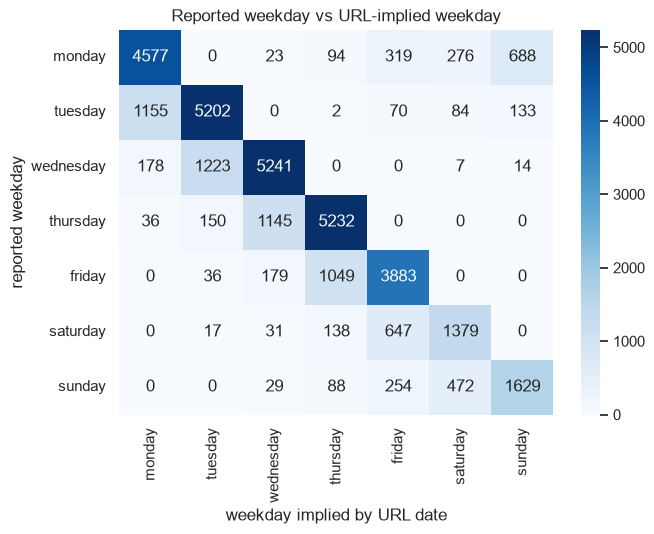

timedelta - (latest URL date - this URL date) in days:


,count,mean,std,min,25%,50%,75%,max
value,"35,680.0000",11.6689,0.6957,7.0000,12.0000,12.0000,12.0000,12.0000


Corr(timedelta, URL-implied age): 1.0


In [9]:
u = df.URL.str.extract(r'/(\d{4})/(\d{2})/(\d{2})/')
pub = pd.to_datetime(u[0] + '-' + u[1] + '-' + u[2], errors='coerce')
print('Unparseable URL dates:', pub.isna().sum(), '| date range:', pub.min().date(), 'to', pub.max().date())
url_wd = pub.dt.day_name().str.lower()
print(f'weekday column agrees with weekday implied by URL date: {(url_wd == df.weekday).mean():.1%}')
off = ((url_wd.map({d: i for i, d in enumerate(DAYS)}) - df.weekday.map({d: i for i, d in enumerate(DAYS)})) % 7)
print('Offset (URL weekday - reported weekday) mod 7 distribution:'); display(off.value_counts(normalize=True).sort_index().round(4).to_frame('share'))
ct = pd.crosstab(df.weekday, url_wd).reindex(index=DAYS, columns=DAYS)
plt.figure(figsize=(7, 5)); sns.heatmap(ct, annot=True, fmt='d', cmap='Blues'); plt.ylabel('reported weekday'); plt.xlabel('weekday implied by URL date'); plt.title('Reported weekday vs URL-implied weekday'); plt.show()

age = (pub.max() - pub).dt.days
diff = df.timedelta - age
print('timedelta - (latest URL date - this URL date) in days:'); display(diff.describe().to_frame('value').T)
print('Corr(timedelta, URL-implied age):', round(np.corrcoef(df.timedelta, age)[0, 1], 4))

**Observation:** `timedelta` is perfectly consistent with the URL date: it equals (latest URL date − article date) + 12 days for at least 75% of rows (mean difference 11.7, range 7–12; correlation 1.000), so `timedelta` and the URL date carry the *same* information (article age = calendar position). Dates span 2013-01-07 to 2014-12-27.

The `weekday` column agrees with the weekday implied by the URL date in only **76.1%** of rows. When they disagree it is almost always by one day (URL weekday = reported weekday − 1 for 17.9% of rows).

In [10]:
mm = (url_wd != df.weekday)
print('Mismatch rate by reported weekday:'); display((mm.groupby(df.weekday).mean() * 100).reindex(DAYS).round(1).to_frame('pct_mismatch'))
print('Mismatch rate by publication year:'); display((mm.groupby(pub.dt.year).mean() * 100).round(1).to_frame('pct_mismatch'))
print('Mismatch rate by month:'); display((mm.groupby(pub.dt.to_period('Q')).mean() * 100).round(1).to_frame('pct_mismatch').T)
print('Median shares: mismatch vs match ->', df.loc[mm, TARGET].median(), 'vs', df.loc[~mm, TARGET].median())
# Which weekday label carries the weekend effect: the reported column or the URL-implied one?
def wk_effect(w, mask):
    a, b = df.loc[mask & w, 'log_shares'], df.loc[mask & ~w, 'log_shares']
    d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    return pd.Series({'n_weekend': int((mask & w).sum()), 'median_weekend': df.loc[mask & w, TARGET].median(), 'median_weekday': df.loc[mask & ~w, TARGET].median(), 'cohen_d_log': d})
w_rep = df.weekday.isin(['saturday', 'sunday']); w_url = url_wd.isin(['saturday', 'sunday'])
allr = pd.Series(True, index=df.index); y13 = pub.dt.year == 2013
print('Weekend effect by label source:')
display(pd.DataFrame({'reported (all)': wk_effect(w_rep, allr), 'URL-implied (all)': wk_effect(w_url, allr),
                      'reported (2013 only)': wk_effect(w_rep, y13), 'URL-implied (2013 only)': wk_effect(w_url, y13),
                      'reported (2014 only)': wk_effect(w_rep, ~y13), 'URL-implied (2014 only)': wk_effect(w_url, ~y13)}).T)

Mismatch rate by reported weekday:


,pct_mismatch
weekday,
monday,23.4000
tuesday,21.7000
wednesday,21.3000
thursday,20.3000
friday,24.6000
saturday,37.7000
sunday,34.1000


Mismatch rate by publication year:


,pct_mismatch
2013,1.4000
2014,43.1000


Mismatch rate by month:


,2013Q1,2013Q2,2013Q3,2013Q4,2014Q1,2014Q2,2014Q3,2014Q4
pct_mismatch,0.0000,0.6000,2.1000,3.0000,4.0000,22.1000,43.9000,91.2000


Median shares: mismatch vs match -> 1400.0 vs 1400.0
Weekend effect by label source:


,n_weekend,median_weekend,median_weekday,cohen_d_log
reported (all),"4,684.0000","2,000.0000","1,400.0000",0.3562
URL-implied (all),"4,682.0000","1,800.0000","1,400.0000",0.2697
reported (2013 only),"2,182.0000","2,000.0000","1,400.0000",0.3898
URL-implied (2013 only),"2,180.0000","2,000.0000","1,400.0000",0.3874
reported (2014 only),"2,502.0000","1,900.0000","1,400.0000",0.3259
URL-implied (2014 only),"2,502.0000","1,700.0000","1,400.0000",0.1658


**Observation:** The disagreement is **time-dependent**, not random noise: ~0–4% of articles disagree through 2014-Q1, then 22% (Q2), 44% (Q3) and **91% in 2014-Q4**. Mismatched rows do not differ in shares (median 1,400 vs 1,400).

Which label is right? The weekend effect is the strongest weekday signal, so I compared it using each label. In 2013 (where the two agree) the effect is identical (Cohen's d ≈ 0.39 with either). In 2014, where they diverge, the **reported** `weekday` still shows a clear effect (d = 0.33; weekend median 1,900 vs 1,400) whereas the URL-implied weekday shows a much weaker one (d = 0.17; 1,700 vs 1,400). That is evidence the `weekday` column is the trustworthy label and the URL date is stale/shifted late in the period (the cause is not something the data can tell us). I therefore use `weekday` as given and treat URL-derived calendar fields with caution.

Rows with n_comments > 0: 32,249. Distinct shares/n_comments ratios (2 dp): 2,495

Minimum ratio = 9.00  (i.e. n_comments never exceeds shares/9)
Top-6 ratio values cover 43.8% of rows; top-20 cover 57.7%; top-50 cover 65.9%


,rows,pct
ratio,,
10.0000,2393,7.4204
50.0000,2376,7.3677
100.0000,2354,7.2995
25.0000,2351,7.2901
16.6700,2320,7.1940
12.5000,2320,7.1940
300.0000,727,2.2543
500.0000,456,1.4140
700.0000,448,1.3892


Null (n_comments shuffled across rows): top-6 ratio values cover 4.11% of rows; distinct ratios = 8,090

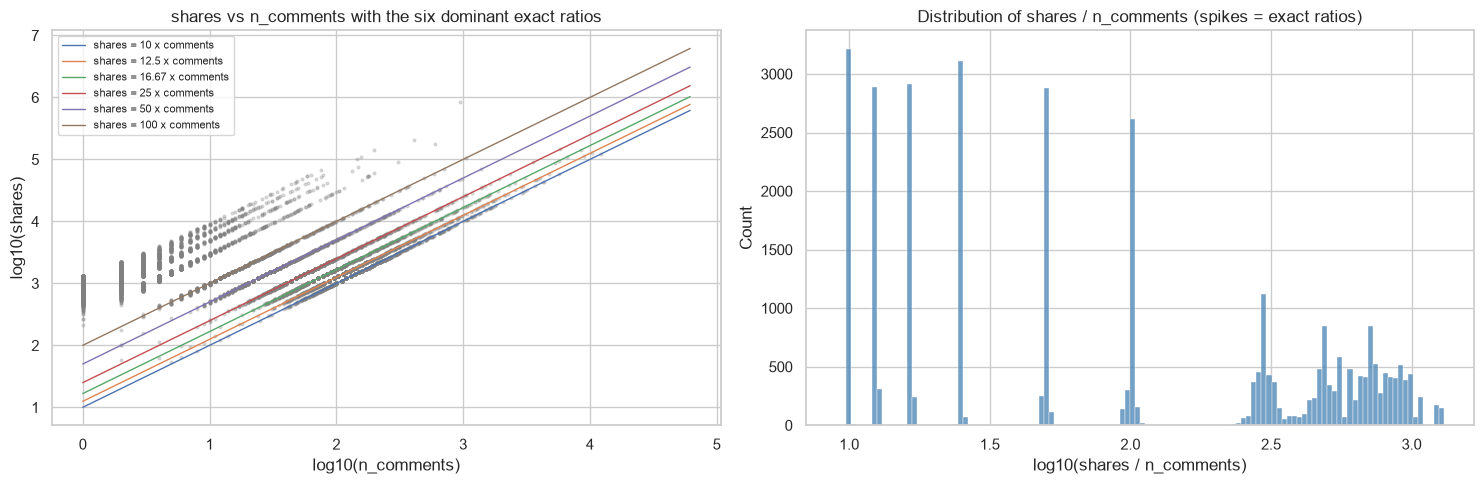

In [11]:
# Structural check on n_comments: is it independent of the target, or tied to it arithmetically?
nc = df[df.n_comments > 0].copy()
nc['ratio'] = (nc[TARGET] / nc.n_comments)
vc = nc.ratio.round(2).value_counts()
print(f'Rows with n_comments > 0: {len(nc):,}. Distinct shares/n_comments ratios (2 dp): {len(vc):,}')
print(f'Minimum ratio = {nc.ratio.min():.2f}  (i.e. n_comments never exceeds shares/{nc.ratio.min():.0f})')
print(f'Top-6 ratio values cover {vc.head(6).sum()/len(nc):.1%} of rows; top-20 cover {vc.head(20).sum()/len(nc):.1%}; top-50 cover {vc.head(50).sum()/len(nc):.1%}')
display(vc.head(12).to_frame('rows').assign(pct=lambda t: t.rows / len(nc) * 100))
# If comments were independent of shares, ratios would be spread continuously. Compare with a shuffled null:
null = (nc[TARGET].values / RNG.permutation(nc.n_comments.values)).round(2)
print(f'Null (n_comments shuffled across rows): top-6 ratio values cover {pd.Series(null).value_counts().head(6).sum()/len(nc):.2%} of rows; distinct ratios = {pd.Series(null).nunique():,}')

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
smp = nc.sample(8000, random_state=2)
ax[0].scatter(np.log10(smp.n_comments), np.log10(smp[TARGET]), s=4, alpha=.25, color='grey')
xs = np.linspace(0, np.log10(nc.n_comments.max()), 50)
for k in [10, 12.5, 16.67, 25, 50, 100]:
    ax[0].plot(xs, xs + np.log10(k), lw=1, label=f'shares = {k} x comments')
ax[0].set_xlabel('log10(n_comments)'); ax[0].set_ylabel('log10(shares)'); ax[0].legend(fontsize=8); ax[0].set_title('shares vs n_comments with the six dominant exact ratios')
sns.histplot(np.log10(nc.ratio), bins=120, ax=ax[1], color='steelblue'); ax[1].set_xlabel('log10(shares / n_comments)'); ax[1].set_title('Distribution of shares / n_comments (spikes = exact ratios)')
plt.tight_layout(); plt.show()

**Observation (important):** `n_comments` is not independent of the target. Among the 32,249 rows with comments, `shares / n_comments` takes only a few exact values: six ratios (10, 12.5, 16.67, 25, 50, 100) each account for ≈7.2–7.4% of rows (43.8% together), and the 50 most common ratios cover 65.9%. When I shuffle `n_comments` across rows the six most common ratios cover only 4.1%, so this is not a coincidence of round-number shares. In addition `n_comments` never exceeds `shares / 9` (minimum ratio = 9.0). The scatter shows rows sitting on straight lines `shares = k × comments`.

This is the signature of `n_comments` having been **derived from (or jointly generated with) the target**, not an independently observed engagement measure. Real comments would not be an exact fraction of shares. Even if it were real data, comment counts accumulate after publication. Either way, it is a **leakage risk**, and the strong correlations reported for it later (the largest in the dataset) should not be read as predictive power available for a new article. I flag it as `LEAKAGE-suspect` from here on.

## 3. Descriptive statistics

In [12]:
d = df[num_cols + [TARGET]]
desc = d.describe().T
desc['skew'] = d.skew()
desc['excess_kurtosis'] = d.kurt()
desc['pct_zero'] = (d == 0).mean() * 100
q1, q3 = d.quantile(.25), d.quantile(.75); iqr = q3 - q1
desc['pct_outside_1.5IQR'] = (((d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)).mean() * 100)
desc['pct_missing'] = d.isna().mean() * 100
display(desc[['count','mean','std','min','25%','50%','75%','max','skew','excess_kurtosis','pct_zero','pct_outside_1.5IQR','pct_missing']])
print('Strongly right-skewed (skew > 2):', list(desc.index[desc['skew'] > 2]))
print('Left-skewed (skew < -1):', list(desc.index[desc['skew'] < -1]))
print('Heavy-tailed (excess kurtosis > 10):', list(desc.index[desc.excess_kurtosis > 10]))

,count,mean,std,min,25%,50%,75%,max,skew,excess_kurtosis,pct_zero,pct_outside_1.5IQR,pct_missing
timedelta,"35,680.0000",354.5232,214.3011,8.0000,163.0000,339.0000,543.0000,731.0000,0.1196,-1.2595,0.0000,0.0000,0.0000
n_tokens_title,"35,680.0000",10.3954,2.1146,2.0000,9.0000,10.0000,12.0000,23.0000,0.1710,0.0036,0.0000,0.3924,0.0000
n_tokens_content,"35,680.0000",545.9951,469.5501,0.0000,247.0000,410.0000,716.0000,"8,474.0000",2.9883,20.4217,2.9737,4.7786,0.0000
n_unique_tokens,"35,680.0000",0.5305,0.1369,0.0000,0.4710,0.5390,0.6082,1.0000,-1.4611,4.8033,2.9737,4.0919,0.0000
n_non_stop_words,"35,680.0000",0.9703,0.1699,0.0000,1.0000,1.0000,1.0000,1.0000,-5.5373,28.6635,2.9737,7.1076,0.0000
n_non_stop_unique_tokens,"35,680.0000",0.6727,0.1539,0.0000,0.6259,0.6903,0.7540,1.0000,-2.4095,8.6296,2.9737,4.4058,0.0000
num_hrefs,"34,959.0000",10.8664,11.2610,0.0000,4.0000,8.0000,14.0000,304.0000,3.9572,35.4489,3.2147,5.3223,2.0207
num_self_hrefs,"34,959.0000",3.2825,3.8341,0.0000,1.0000,3.0000,4.0000,116.0000,5.3403,61.0163,13.2091,5.0841,2.0207
num_imgs,"34,261.0000",4.5130,8.2597,0.0000,1.0000,1.0000,4.0000,128.0000,3.9623,24.6810,16.9815,18.5370,3.9770
num_videos,"18,925.0000",1.2864,4.1482,0.0000,0.0000,0.0000,1.0000,91.0000,6.7295,68.6559,33.3352,4.1031,46.9591


Strongly right-skewed (skew > 2): ['n_tokens_content', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos', 'n_comments', 'self_reference_min_shares', 'self_reference_max_shares', 'self_reference_avg_shares', 'kw_min_min', 'kw_max_min', 'kw_avg_min', 'kw_min_max', 'kw_max_avg', 'kw_avg_avg', 'shares']
Left-skewed (skew < -1): ['n_unique_tokens', 'n_non_stop_words', 'n_non_stop_unique_tokens', 'average_token_length', 'kw_max_max']
Heavy-tailed (excess kurtosis > 10): ['n_tokens_content', 'n_non_stop_words', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos', 'n_comments', 'average_token_length', 'self_reference_min_shares', 'self_reference_max_shares', 'self_reference_avg_shares', 'kw_max_min', 'kw_avg_min', 'kw_min_max', 'kw_max_avg', 'kw_avg_avg', 'shares']


**Observation:**
- **Most heavily right-skewed:** `n_comments` (skew 67), `kw_max_min` (37), `kw_avg_min` (33), `self_reference_min_shares` (26), `self_reference_avg_shares` (18), `kw_max_avg` (17), `kw_min_max` (10), plus `num_videos` (6.7), `kw_avg_avg` (5.9), `num_self_hrefs` (5.3). Excess kurtosis reaches 8,022 for `n_comments` and 843 for `self_reference_min_shares`: a few extreme rows dominate the moments.
- **Left-skewed:** `n_non_stop_words` (−5.5), `average_token_length` (−4.6), `n_non_stop_unique_tokens` (−2.4), `n_unique_tokens` (−1.5), `kw_max_max` (−2.6). The first four are due to the 1,061 empty-article zeros, `kw_max_max` due to the 843,300 ceiling.
- **Near-symmetric:** `n_tokens_title` (0.17), `timedelta` (0.12, excess kurtosis −1.26 = flat/uniform), `num_keywords` (−0.15), `kw_avg_max` (0.63).
- **Heaps of zeros:** `kw_min_max` and `kw_min_avg` 43% zeros, `self_reference_*` 17.8%, `num_videos` 33% of its non-missing values.
- Share of values beyond 1.5×IQR is large for `shares` (11.4%), `num_imgs` (18.5%), `kw_max_max` (23.8%) – so IQR fences flag far too many rows to be treated as errors.

In [13]:
for c in ['weekday', 'channel']:
    vc = df[c].value_counts()
    display(pd.DataFrame({'n': vc, 'pct': (vc / len(df) * 100).round(2)}))

,n,pct
weekday,,
wednesday,6663,18.6700
tuesday,6646,18.6300
thursday,6563,18.3900
monday,5977,16.7500
friday,5147,14.4300
sunday,2472,6.9300
saturday,2212,6.2000


,n,pct
channel,,
world,7573,21.2200
technology,6642,18.6200
entertainment,6407,17.9600
business,5623,15.7600
Unknown,5462,15.3100
social_media,2089,5.8500
lifestyle,1884,5.2800


**Observation:** Publication is heavily weekday-weighted: Tuesday–Thursday ~18.4–18.7% each, Monday 16.8%, Friday 14.4%, but Saturday 6.2% and Sunday 6.9%. The channel mix is led by `world` (21.2%), `technology` (18.6%) and `entertainment` (18.0%); NaN/Unknown is 15.3%, and `social_media` (5.9%) and `lifestyle` (5.3%) are small, so any interaction cells involving them are thin.

## 4. Univariate analysis
Columns with skew > 1.5 (and no negatives) are drawn on a `log1p` x-axis so their shape is visible; the dashed line is the median. Each figure is followed by a table of the dominant value of every column.

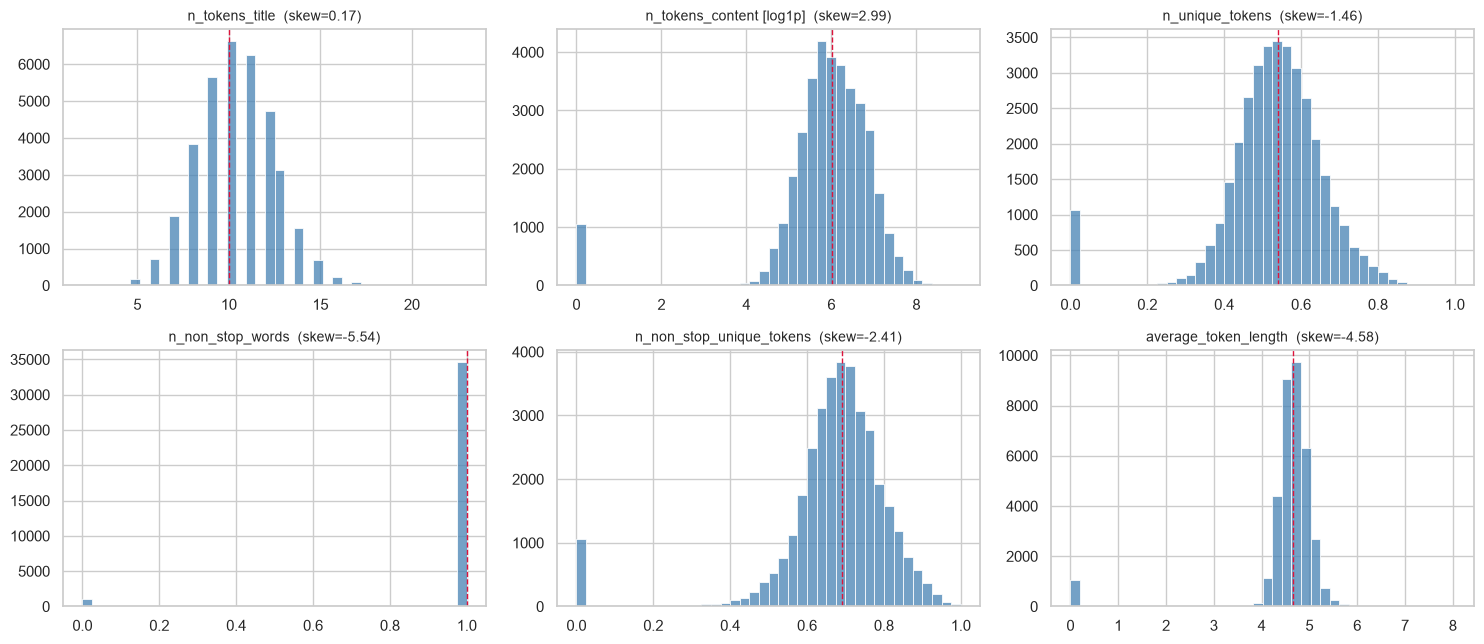

,plotted_scale,skew,modal_value,modal_share_%,n_unique
feature,,,,,
n_tokens_title,raw,0.1700,10.0000,18.6000,20
n_tokens_content,log1p,2.9900,0.0000,3.0000,2324
n_unique_tokens,raw,-1.4600,0.0000,3.0000,25197
n_non_stop_words,raw,-5.5400,0.0000,3.0000,1429
n_non_stop_unique_tokens,raw,-2.4100,0.0000,3.0000,21345
average_token_length,raw,-4.5800,0.0000,3.0000,27595


In [14]:
def plot_group(cols, ncols=3):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.3 * nrows)); axes = np.array(axes).ravel()
    info = []
    for ax, c in zip(axes, cols):
        x = df[c].dropna(); sk = x.skew()
        use_log = (sk > 1.5) and (x.min() >= 0)
        v = np.log1p(x) if use_log else x
        discrete = x.nunique() <= 15
        sns.histplot(v, ax=ax, color='steelblue', **({'discrete': True} if discrete else {'bins': 40}))
        ax.axvline(v.median(), color='crimson', ls='--', lw=1)
        ax.set_title(f"{c}{' [log1p]' if use_log else ''}  (skew={sk:.2f})", fontsize=10); ax.set_xlabel(''); ax.set_ylabel('')
        vc = x.value_counts(normalize=True)
        info.append((c, 'log1p' if use_log else 'raw', round(sk, 2), vc.index[0], round(vc.iloc[0] * 100, 1), x.nunique()))
    for ax in axes[len(cols):]: ax.axis('off')
    plt.tight_layout(); plt.show()
    display(pd.DataFrame(info, columns=['feature', 'plotted_scale', 'skew', 'modal_value', 'modal_share_%', 'n_unique']).set_index('feature'))

G_TEXT = ['n_tokens_title','n_tokens_content','n_unique_tokens','n_non_stop_words','n_non_stop_unique_tokens','average_token_length']
G_LINK = ['num_hrefs','num_self_hrefs','num_imgs','num_videos','n_comments','num_keywords','timedelta']
G_SELF = ['self_reference_min_shares','self_reference_max_shares','self_reference_avg_shares']
G_KW = [c for c in num_cols if c.startswith('kw_')]
plot_group(G_TEXT)

**Observation (text-shape features):**
- `n_tokens_title` is symmetric, centred on 10 words (mode 10 = 18.6% of rows, skew 0.17): a well-behaved feature.
- `n_tokens_content` is right-skewed (skew 2.99, shown on log1p scale where it is roughly bell-shaped), with a median of 410 words, a long tail up to 8,474 and a 3% spike at 0 (empty articles).
- `n_unique_tokens`, `n_non_stop_words`, `n_non_stop_unique_tokens`, `average_token_length` are bounded ratios/lengths concentrated in a narrow band (most mass between ~0.45–0.75 for the ratios, ~4.5–4.9 for word length) with a separate spike at exactly 0 (the same 3% empty articles); that spike is what produces the negative skew. `n_non_stop_words` equals 1.0 for most rows (median = 75th percentile = 1), so it has almost no resolving power for non-empty articles.

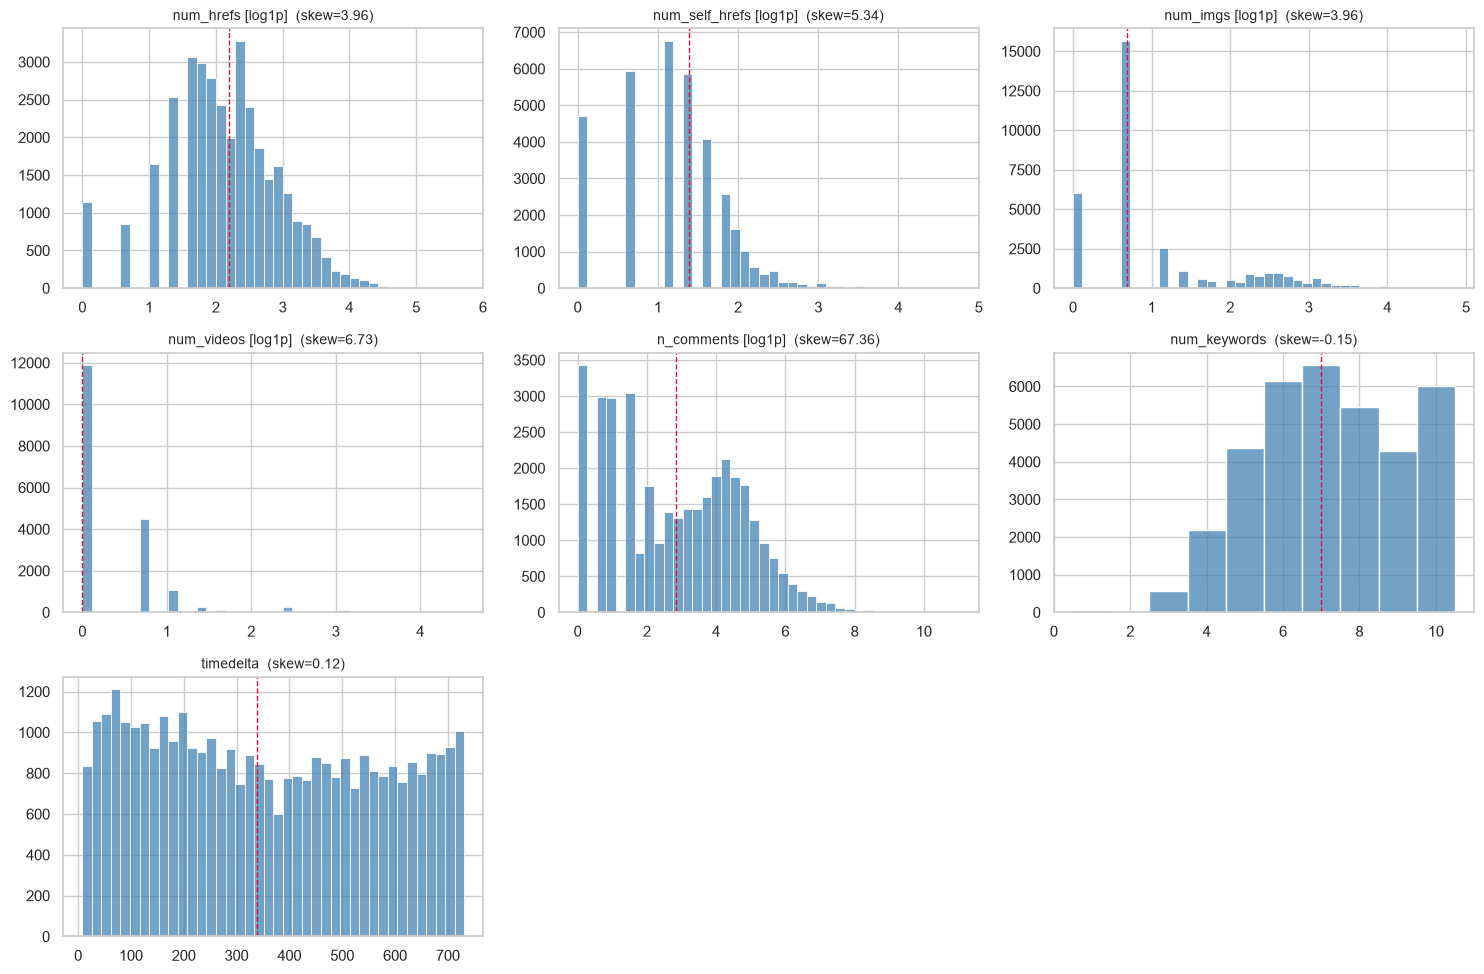

,plotted_scale,skew,modal_value,modal_share_%,n_unique
feature,,,,,
num_hrefs,log1p,3.9600,4.0000,8.8000,128
num_self_hrefs,log1p,5.3400,2.0000,19.4000,57
num_imgs,log1p,3.9600,1.0000,45.7000,89
num_videos,log1p,6.7300,0.0000,62.8000,46
n_comments,log1p,67.3600,0.0000,9.6000,834
num_keywords,raw,-0.1500,7.0000,18.4000,10
timedelta,raw,0.1200,91.0000,0.3000,724


In [15]:
plot_group(G_LINK)

**Observation:**
- `num_hrefs` (median 8, mode 4), `num_self_hrefs` (median 3) and `num_imgs` (45.7% have exactly 1 image) are right-skewed counts with long tails (max 304 links, 128 images). On log scale they look roughly bell-shaped, which suggests multiplicative rather than additive variation.
- `num_videos`: among observed values 62.8% are 0; mean 1.29 against max 91 – a zero-inflated count (plus the 47% missing).
- `n_comments`: extreme (skew 67, max 61,790, 9.6% zeros); on log scale it is smooth but see the leakage observation in §2.
- `num_keywords` is a small integer (1–10), mode 7.
- `timedelta` is close to **uniform** over 8–731 days (skew 0.12, excess kurtosis −1.26): articles arrive roughly evenly over two years, and no modal value exceeds 0.3%.

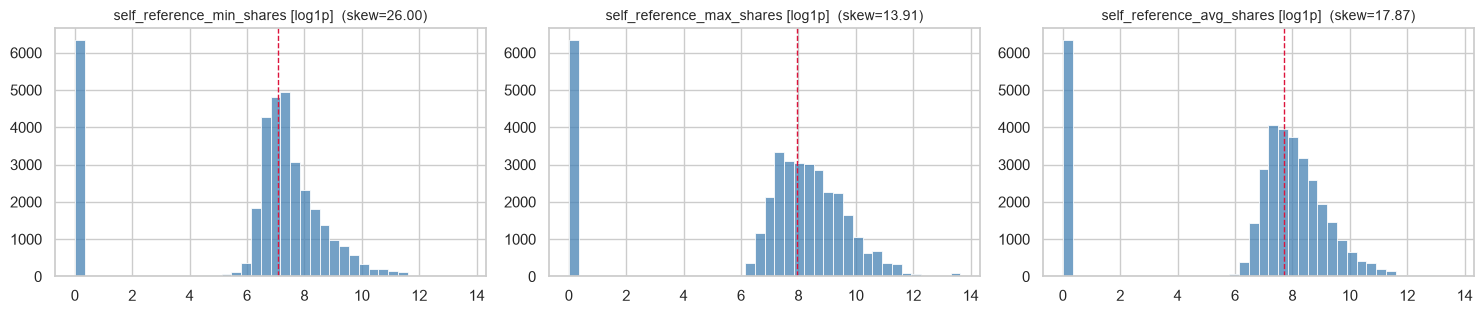

,plotted_scale,skew,modal_value,modal_share_%,n_unique
feature,,,,,
self_reference_min_shares,log1p,26.0000,0.0000,18.1000,1231
self_reference_max_shares,log1p,13.9100,0.0000,18.1000,1119
self_reference_avg_shares,log1p,17.8700,0.0000,18.1000,7853


In [16]:
plot_group(G_SELF)

**Observation:** All three `self_reference_*_shares` columns have an 18.1% spike at exactly 0 (articles that link to no previously shared article, or whose linked pages have zero shares) and, apart from that, a smooth log-normal-like shape between roughly e^6 ≈ 400 and e^12 ≈ 160,000 shares. Skews of 14–26 on the raw scale come from rare linked viral pages. The three columns are strongly redundant (avg correlates 0.82 and 0.86 with min and max), so they largely repeat one piece of information.

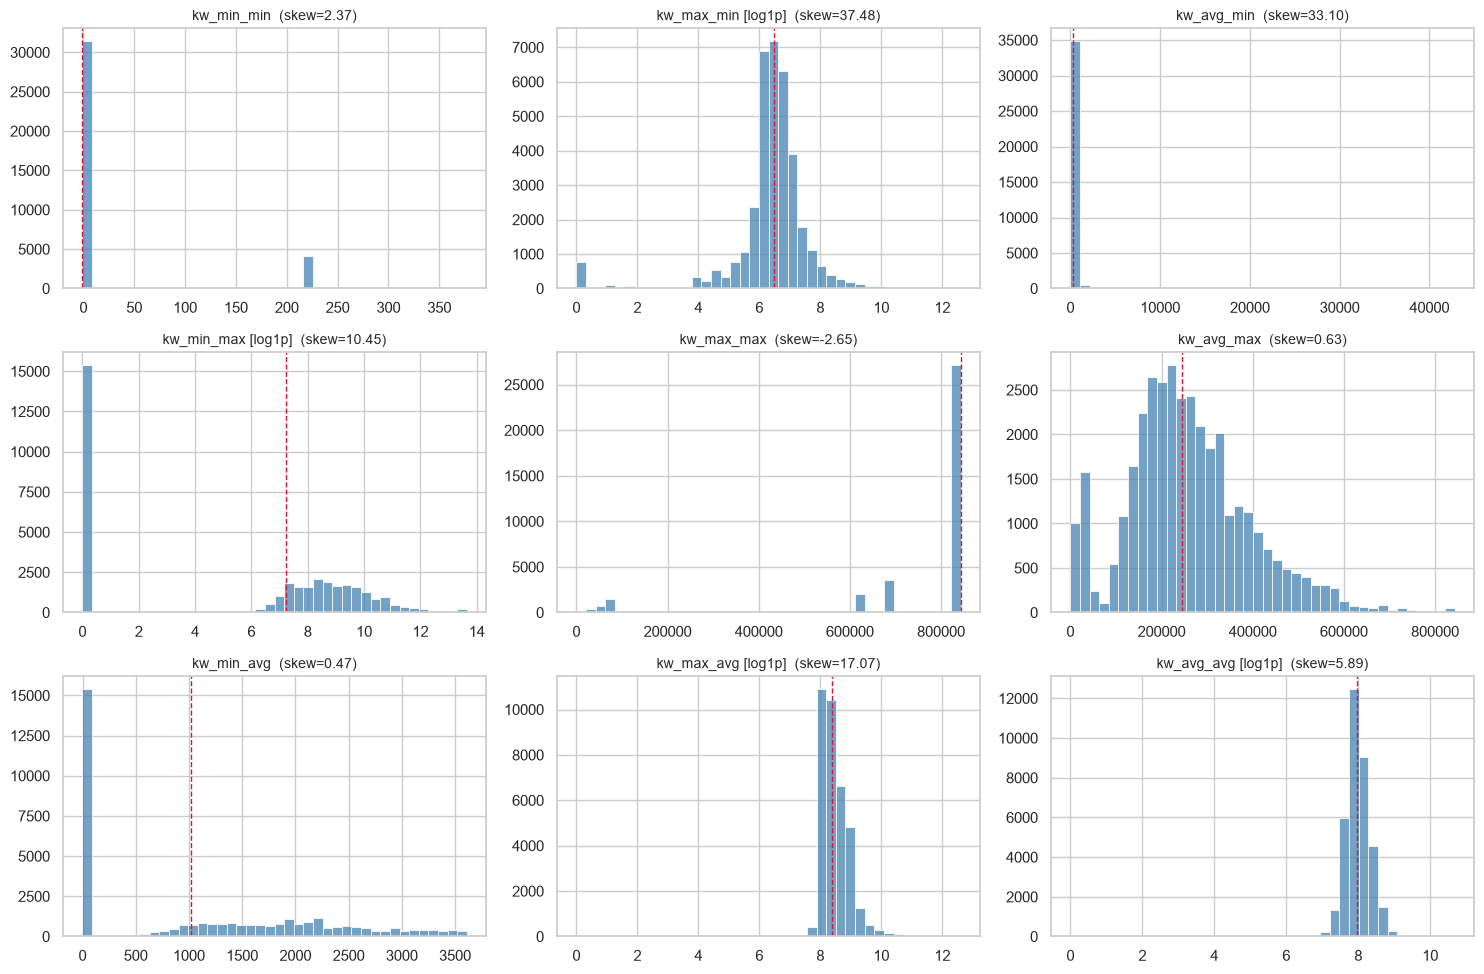

,plotted_scale,skew,modal_value,modal_share_%,n_unique
feature,,,,,
kw_min_min,raw,2.3700,-1.0000,57.9000,22
kw_max_min,log1p,37.4800,"1,100.0000",3.8000,1064
kw_avg_min,raw,33.1000,-1.0000,1.8000,15949
kw_min_max,log1p,10.4500,0.0000,43.2000,1006
kw_max_max,raw,-2.6500,"843,300.0000",76.2000,31
kw_avg_max,raw,0.6300,0.0000,0.2000,28284
kw_min_avg,raw,0.4700,0.0000,43.2000,14686
kw_max_avg,log1p,17.0700,0.0000,0.2000,18053
kw_avg_avg,log1p,5.8900,0.0000,0.2000,35394


In [17]:
plot_group(G_KW)

**Observation:** The `kw_*` block is heavily degenerate: `kw_min_min` is −1 for 57.9% of rows and `kw_max_max` is 843,300 for 76.2%; `kw_min_max` and `kw_min_avg` are 0 for 43% of rows. Only `kw_avg_avg`, `kw_max_avg`, `kw_avg_max` and (partly) `kw_max_min` have a continuous unimodal shape; those are strongly right-skewed (skew 5.9, 17.1, 0.63 and 37.5), well-behaved after a log transform. Because these are *statistics of other articles' shares for the same keywords*, they behave like a "typical popularity of this topic" signal; the sentinel-heavy ones (`kw_min_min`, `kw_max_max`) are mostly not informative.

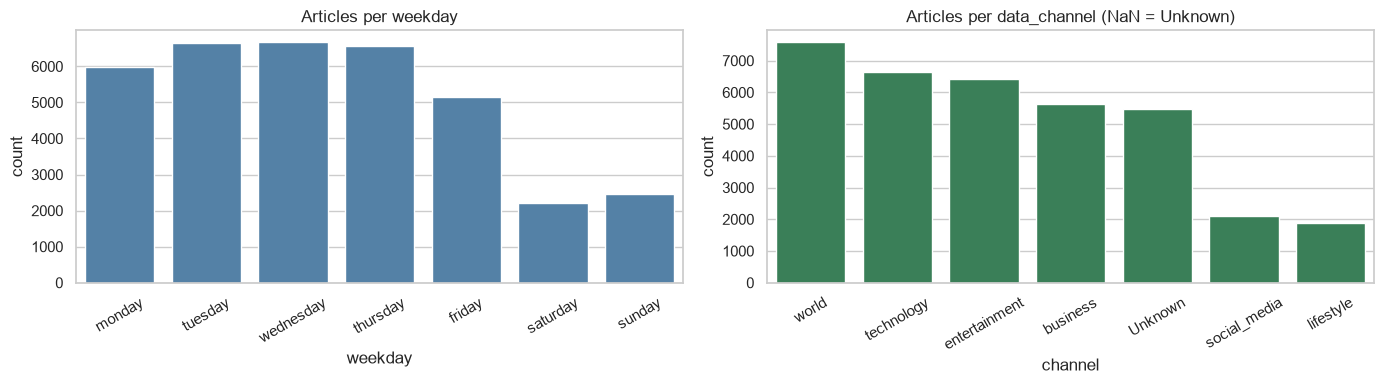

Weekend share of articles: 13.1% (uniform would be 28.6%)
Articles per weekday-day: Mon-Fri avg = 6,199 | Sat-Sun avg = 2,342


Year of publication (URL): {'2013': 16402, '2014': 19278}


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(x='weekday', data=df, order=DAYS, ax=ax[0], color='steelblue'); ax[0].set_title('Articles per weekday'); ax[0].tick_params(axis='x', rotation=30)
order = df.channel.value_counts().index
sns.countplot(x='channel', data=df, order=order, ax=ax[1], color='seagreen'); ax[1].set_title('Articles per data_channel (NaN = Unknown)'); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
wk = df.weekday.isin(['saturday','sunday'])
print(f'Weekend share of articles: {wk.mean():.1%} (uniform would be {2/7:.1%})')
print(f'Articles per weekday-day: Mon-Fri avg = {df[~wk].shape[0]/5:,.0f} | Sat-Sun avg = {df[wk].shape[0]/2:,.0f}')
print(f"Year of publication (URL): {df.URL.str.extract(r'/(\d{4})/')[0].value_counts().sort_index().to_dict()}")

**Observation:** Only 13.1% of articles appear on a weekend (vs 28.6% if uniform): Mon–Fri average ≈ 6,200 articles per day vs ≈ 2,340 per weekend day. 2014 has more articles than 2013 (19,278 vs 16,402). Because weekend articles are few but have higher shares (see §6), the weekend effect is estimated from ~4,700 rows.

## 5. Bivariate analysis
### 5.1 Numeric features vs `shares`: Pearson **and** Spearman for every feature
Columns reported: Pearson with raw `shares`; Pearson with `log1p(shares)` (less outlier-dominated); Pearson with both sides log-transformed (where the feature has no negatives); Spearman (rank-based; invariant to monotone transforms of either side, so identical for raw and log shares). `gap_raw` = |Spearman| − |Pearson raw|: a meaningfully positive gap (here > 0.05) signals a real, monotonic but non-linear (or outlier-masked) relation.

,n,pearson_raw,pearson_logY,pearson_logX_logY,spearman,spearman_p,gap_raw,gap_logY,flag
feature,,,,,,,,,
n_comments,35680,0.5230,0.3272,0.4040,0.3617,0.0000,-0.1613,0.0345,
kw_avg_avg,35680,0.1017,0.2192,0.1817,0.2547,0.0000,0.1530,0.0355,monotonic non-linear / outlier-masked
kw_max_avg,35680,0.0557,0.1067,0.1665,0.2228,0.0000,0.1671,0.1161,monotonic non-linear / outlier-masked
self_reference_avg_shares,34959,0.0590,0.0877,0.1072,0.1909,0.0000,0.1320,0.1033,monotonic non-linear / outlier-masked
self_reference_min_shares,34959,0.0578,0.0743,0.1047,0.1799,0.0000,0.1221,0.1056,monotonic non-linear / outlier-masked
self_reference_max_shares,34959,0.0479,0.0786,0.1033,0.1678,0.0000,0.1198,0.0892,monotonic non-linear / outlier-masked
kw_min_avg,35680,0.0382,0.1084,NaN,0.1028,0.0000,0.0646,-0.0056,monotonic non-linear / outlier-masked
kw_avg_min,35680,0.0166,0.0362,NaN,0.0953,0.0000,0.0788,0.0591,monotonic non-linear / outlier-masked
kw_max_min,35680,0.0160,0.0287,0.0848,0.0922,0.0000,0.0762,0.0635,monotonic non-linear / outlier-masked


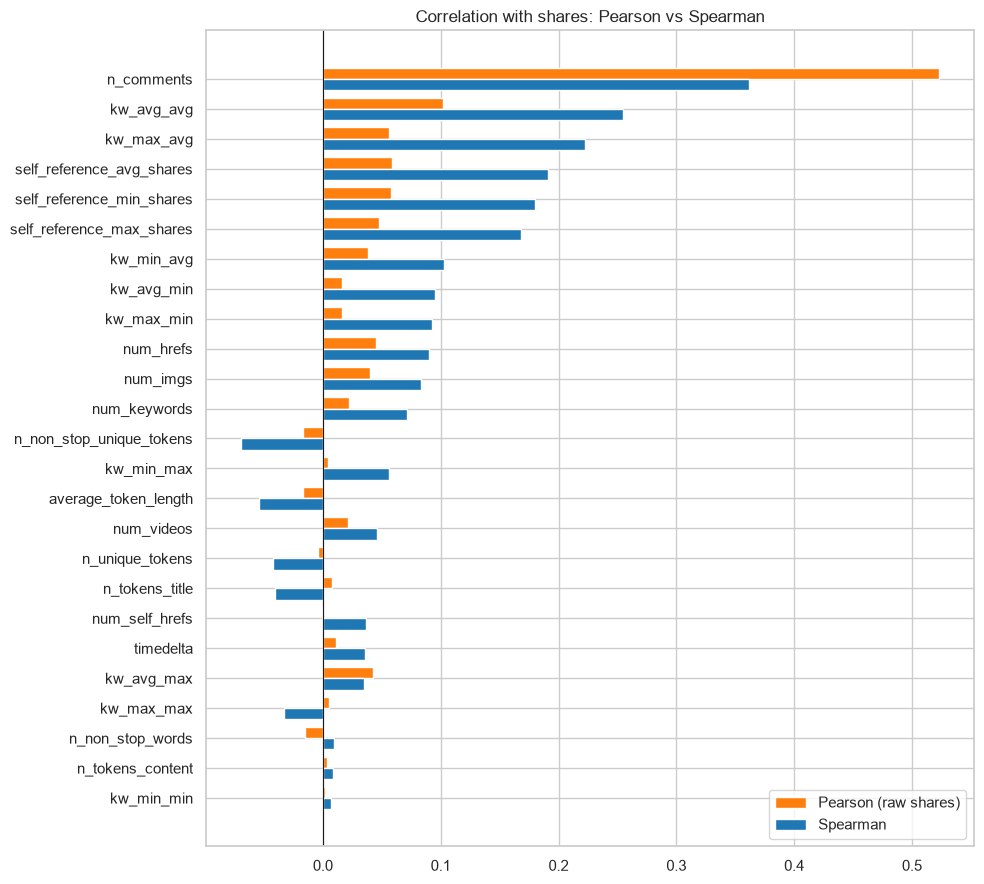

In [19]:
rows = []
for c in num_cols:
    s = df[[c, TARGET, 'log_shares']].dropna(); x = s[c]
    rows.append(dict(feature=c, n=len(s),
        pearson_raw=stats.pearsonr(x, s[TARGET])[0],
        pearson_logY=stats.pearsonr(x, s.log_shares)[0],
        pearson_logX_logY=stats.pearsonr(np.log1p(x), s.log_shares)[0] if x.min() >= 0 else np.nan,
        spearman=stats.spearmanr(x, s[TARGET])[0],
        spearman_p=stats.spearmanr(x, s[TARGET])[1]))
biv = pd.DataFrame(rows).set_index('feature')
biv['gap_raw'] = biv.spearman.abs() - biv.pearson_raw.abs()
biv['gap_logY'] = biv.spearman.abs() - biv.pearson_logY.abs()
biv = biv.reindex(biv.spearman.abs().sort_values(ascending=False).index)
biv['flag'] = np.where(biv.gap_raw > 0.05, 'monotonic non-linear / outlier-masked', '')
display(biv)

fig, ax = plt.subplots(figsize=(10, 9))
y_pos = np.arange(len(biv)); h = 0.38
ax.barh(y_pos - h/2, biv.pearson_raw, h, label='Pearson (raw shares)', color='tab:orange')
ax.barh(y_pos + h/2, biv.spearman, h, label='Spearman', color='tab:blue')
ax.set_yticks(y_pos); ax.set_yticklabels(biv.index); ax.invert_yaxis(); ax.axvline(0, color='k', lw=.8)
ax.set_title('Correlation with shares: Pearson vs Spearman'); ax.legend(); plt.tight_layout(); plt.show()

**Observation:** (Reading note: Spearman is rank-based, so it is the same for raw and log shares.)
- **`n_comments` has the largest correlations, but is leakage-suspect (see §2).** Pearson 0.52 with raw shares is *larger* than Spearman 0.36 (negative gap): it is driven by a few extreme rows (Pearson drops to 0.11 when extremes are removed in §8). Pearson with logs on both sides is 0.40.
- **`kw_avg_avg`** (Spearman 0.25) and **`kw_max_avg`** (0.22), **`self_reference_*`** (0.17–0.19): Spearman is 0.12–0.17 larger than Pearson on raw shares. Be careful: much of that gap (`gap_raw`) is caused by the heavy-tailed *target*; the fairer comparison is `gap_logY`. There, `kw_max_avg` (+0.116), `kw_max_min` (+0.064), `kw_avg_min` (+0.059), and the `self_reference_*` columns (+0.09–0.11) still show a meaningfully larger Spearman, i.e. a real monotonic-but-non-linear (log-shaped) relationship – confirmed by their Pearson(log x, log y) being 0.10–0.17, higher than the plain Pearson with log y (0.03–0.11). `kw_avg_avg` (+0.036) is mostly linear on the log-target scale.
- Everything else is weak: |Spearman| ≤ 0.10. `kw_min_avg` 0.10, `num_hrefs` 0.09, `num_imgs` 0.08, `num_keywords` 0.07, `n_non_stop_unique_tokens` −0.07, `average_token_length` −0.05; `n_tokens_content` is ≈ 0 (0.009), `kw_min_min` ≈ 0.
- **Calibration:** Spearman² (a rough proxy for variance explained) is ≈ 0.065 for the best legitimate feature `kw_avg_avg`, ≈ 0.05 for `kw_max_avg`, ≈ 0.03–0.04 for `self_reference_*`, and ≤ 0.01 for everything else. No single non-leaky feature explains more than ~6% of the ranking of shares. Spearman p-values are ~0 for nearly all features simply because n is large; they say nothing about importance.

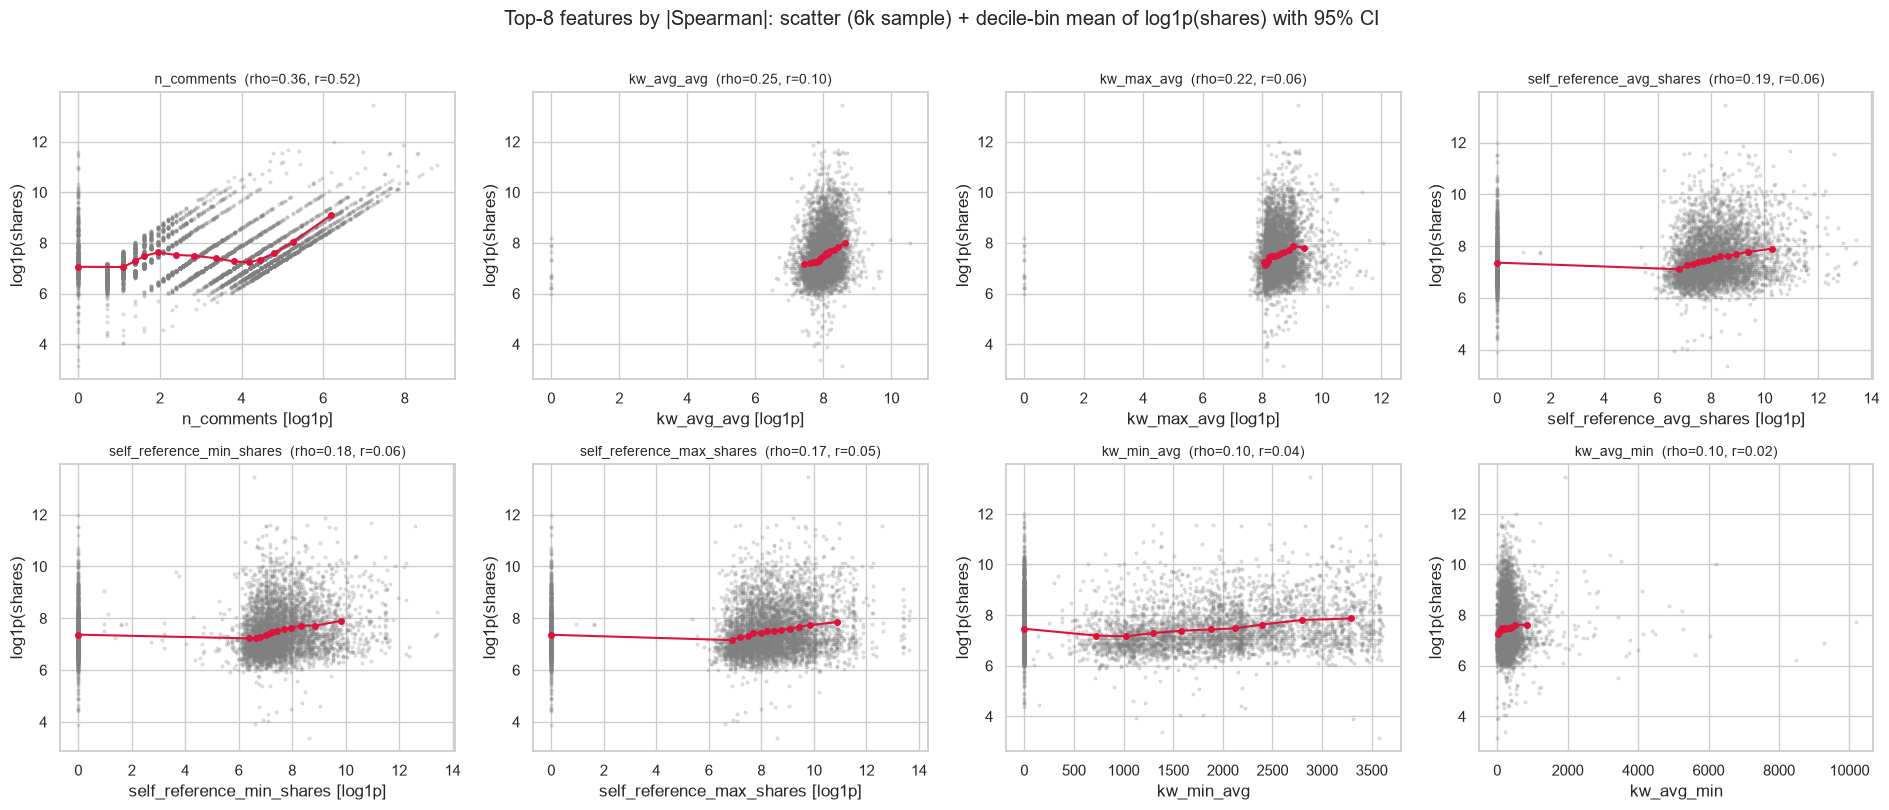

In [20]:
top = list(biv.index[:8])
fig, axes = plt.subplots(2, 4, figsize=(19, 8)); axes = axes.ravel()
samp = df.sample(6000, random_state=1)
for ax, c in zip(axes, top):
    xs = np.log1p(samp[c]) if (df[c].min() >= 0 and df[c].skew() > 1.5) else samp[c]
    ax.scatter(xs, samp.log_shares, s=4, alpha=.2, color='grey')
    g = binned_profile(np.log1p(df[c]) if (df[c].min() >= 0 and df[c].skew() > 1.5) else df[c], df.log_shares, 15)
    if g is not None:
        ax.errorbar(g.x_med, g.y_mean, yerr=1.96 * g.se, color='crimson', marker='o', ms=4, lw=1.5)
    ax.set_title(f"{c}  (rho={biv.loc[c,'spearman']:.2f}, r={biv.loc[c,'pearson_raw']:.2f})", fontsize=10)
    ax.set_xlabel(c + (' [log1p]' if (df[c].min() >= 0 and df[c].skew() > 1.5) else '')); ax.set_ylabel('log1p(shares)')
plt.suptitle('Top-8 features by |Spearman|: scatter (6k sample) + decile-bin mean of log1p(shares) with 95% CI', y=1.01)
plt.tight_layout(); plt.show()

**Observation:** The 6k-row scatters are dominated by a wide cloud (log shares has a standard deviation of ~1 and the relationships are weak), but the red decile-mean lines show the structure: for `kw_avg_avg`, `kw_max_avg` and the `self_reference_*` columns the mean log-shares rises steadily and fairly smoothly over the range of the (log-scaled) feature, a consistent monotonic trend. For `n_comments` the line is steep. Within each x-bin the spread is far larger than the movement of the mean, which is why the correlations are modest.

In [21]:
df['is_weekend'] = df.weekday.isin(['saturday', 'sunday']).astype(int)
rows = []
for c in ['weekday', 'channel', 'is_weekend']:
    groups = [g.log_shares.values for _, g in df.groupby(c)]
    F, pF = stats.f_oneway(*groups); H, pH = stats.kruskal(*groups)
    rows.append(dict(feature=c, n_levels=len(groups), ANOVA_F=F, ANOVA_p=pF, kruskal_H=H, kruskal_p=pH,
                     eta2_log_shares=eta_squared(df.log_shares, df[c]), eta2_raw_shares=eta_squared(df[TARGET], df[c])))
cat_assoc = pd.DataFrame(rows).set_index('feature')
display(cat_assoc)
print('Note: with ~35k rows even trivial effects give tiny p-values, so eta-squared (share of variance explained) is the number to read.')

,n_levels,ANOVA_F,ANOVA_p,kruskal_H,kruskal_p,eta2_log_shares,eta2_raw_shares
feature,,,,,,,
weekday,7,87.9686,0.0000,903.5688,0.0000,0.0146,0.0005
channel,7,345.1938,0.0000,"2,441.7216",0.0000,0.0549,0.0095
is_weekend,2,490.6789,0.0000,840.6774,0.0000,0.0136,0.0003


Note: with ~35k rows even trivial effects give tiny p-values, so eta-squared (share of variance explained) is the number to read.


**Observation:** Both categorical features have overwhelmingly significant tests (ANOVA / Kruskal-Wallis p ≈ 0), but p-values are not informative at n = 35k. The effect sizes are small: `data_channel` explains **5.5%** of the variance of log shares (η² = 0.055), `weekday` **1.5%** (0.0146), `is_weekend` alone **1.4%** (0.0136), so the weekday effect is almost entirely a weekend-vs-rest contrast. On *raw* shares η² collapses to 0.0095 (channel) and 0.0005 (weekday), because a few giant outliers dominate the raw variance. So categories mainly move the *typical* article's popularity and explain little of the variance in the viral tail.

### 5.2 Hunting for non-monotonic structure in features that look weak on BOTH Pearson and Spearman
A feature is called *weak on both* if |Pearson (raw)| < 0.10 and |Spearman| < 0.10. For these we compare (against `log1p(shares)`): linear R²; quadratic R² (with an F-test on the squared term); and the R² of a 10-quantile-bin step function (`R²_bins`), which can capture U-shapes and thresholds that neither correlation can. With n ≈ 35k the p-value is nearly always tiny, so we flag by **effect size**: ΔR²(quad − lin) ≥ 0.002 or R²_bins − R²_lin ≥ 0.003 (the bin model has 9 extra parameters, so pure noise would add only ≈ 0.0003).

In [22]:
weak = list(biv.index[(biv.pearson_raw.abs() < 0.10) & (biv.spearman.abs() < 0.10)])
print(f'{len(weak)} features weak on both Pearson and Spearman:', weak)

def nonlin_tests(x, y):
    d = pd.DataFrame({'x': x, 'y': y}).dropna(); z = (d.x - d.x.mean()) / d.x.std()
    m1 = sm.OLS(d.y, sm.add_constant(z)).fit()
    m2 = sm.OLS(d.y, sm.add_constant(np.column_stack([z, z ** 2]))).fit()
    F = (m2.rsquared - m1.rsquared) / ((1 - m2.rsquared) / m2.df_resid); p = stats.f.sf(F, 1, m2.df_resid)
    b = pd.qcut(d.x, 10, duplicates='drop')
    r2_bins = eta_squared(d.y, b.astype(str)) if b.nunique() > 1 else np.nan
    means = d.groupby(b, observed=True).y.mean().values
    shape_rho = stats.spearmanr(np.arange(len(means)), means)[0] if len(means) > 2 else np.nan
    return dict(n=len(d), R2_linear=m1.rsquared, R2_quad=m2.rsquared, dR2_quad=m2.rsquared - m1.rsquared, quad_coef_sign=np.sign(np.asarray(m2.params)[2]),
                quad_F_p=p, R2_bins=r2_bins, dR2_bins=r2_bins - m1.rsquared, n_bins=len(means), bin_mean_range=means.max() - means.min(), profile_monotonic_rho=shape_rho)

nl = pd.DataFrame({c: nonlin_tests(df[c], df.log_shares) for c in weak}).T.astype(float)
nl['curved?'] = np.where((nl.dR2_quad >= 0.002) | (nl.dR2_bins >= 0.003), 'YES', 'no')
nl = nl.sort_values('dR2_bins', ascending=False)
display(nl)

18 features weak on both Pearson and Spearman: ['kw_avg_min', 'kw_max_min', 'num_hrefs', 'num_imgs', 'num_keywords', 'n_non_stop_unique_tokens', 'kw_min_max', 'average_token_length', 'num_videos', 'n_unique_tokens', 'n_tokens_title', 'num_self_hrefs', 'timedelta', 'kw_avg_max', 'kw_max_max', 'n_non_stop_words', 'n_tokens_content', 'kw_min_min']


,n,R2_linear,R2_quad,dR2_quad,quad_coef_sign,quad_F_p,R2_bins,dR2_bins,n_bins,bin_mean_range,profile_monotonic_rho,curved?
timedelta,"35,680.0000",0.0005,0.0018,0.0013,-1.0000,0.0000,0.0106,0.0100,10.0000,0.3168,0.2606,YES
num_imgs,"34,261.0000",0.0083,0.0115,0.0032,-1.0000,0.0000,0.0172,0.0089,5.0000,0.3175,0.8000,YES
kw_min_max,"35,680.0000",0.0001,0.0023,0.0022,-1.0000,0.0000,0.0069,0.0068,6.0000,0.2630,0.9429,YES
kw_avg_min,"35,680.0000",0.0013,0.0026,0.0013,-1.0000,0.0000,0.0077,0.0064,10.0000,0.3471,0.9515,YES
kw_max_min,"35,680.0000",0.0008,0.0016,0.0008,-1.0000,0.0000,0.0067,0.0059,10.0000,0.2971,0.9636,YES
num_hrefs,"34,959.0000",0.0109,0.0115,0.0006,-1.0000,0.0000,0.0151,0.0042,10.0000,0.3610,0.4303,YES
n_unique_tokens,"35,680.0000",0.0013,0.0020,0.0007,1.0000,0.0000,0.0054,0.0041,10.0000,0.2443,0.0788,YES
n_tokens_content,"35,680.0000",0.0005,0.0014,0.0009,1.0000,0.0000,0.0041,0.0036,10.0000,0.1724,-0.1515,YES
kw_avg_max,"35,680.0000",0.0033,0.0038,0.0005,1.0000,0.0000,0.0065,0.0032,10.0000,0.2433,0.5879,YES
n_non_stop_words,"35,680.0000",0.0010,0.0010,0.0000,-1.0000,0.7179,0.0034,0.0025,10.0000,0.1751,-0.1879,no


**Observation:** 18 of 25 numeric features are weak on both Pearson and Spearman (< 0.10). Testing them for curved structure (against log shares) flags 9 by my effect-size rule: `timedelta`, `num_imgs`, `kw_min_max`, `kw_avg_min`, `kw_max_min`, `num_hrefs`, `n_unique_tokens`, `n_tokens_content`, `kw_avg_max`. The other 9 (including `num_keywords`, `n_tokens_title`, `num_videos`, `kw_min_min`, `n_non_stop_*`, `average_token_length`) show no meaningful curvature.

**Calibration: the effects are real but small.** Even for the flagged ones the extra variance explained beyond a straight line is tiny: ΔR²(bins − linear) is 0.0100 (`timedelta`), 0.0089 (`num_imgs`), 0.0068 (`kw_min_max`), 0.0064, 0.0059, 0.0042, 0.0041, 0.0036, 0.0032, i.e. at most ~1 percentage point of log-share variance. All quadratic F-tests are significant simply due to sample size; the ΔR² is the number to read.

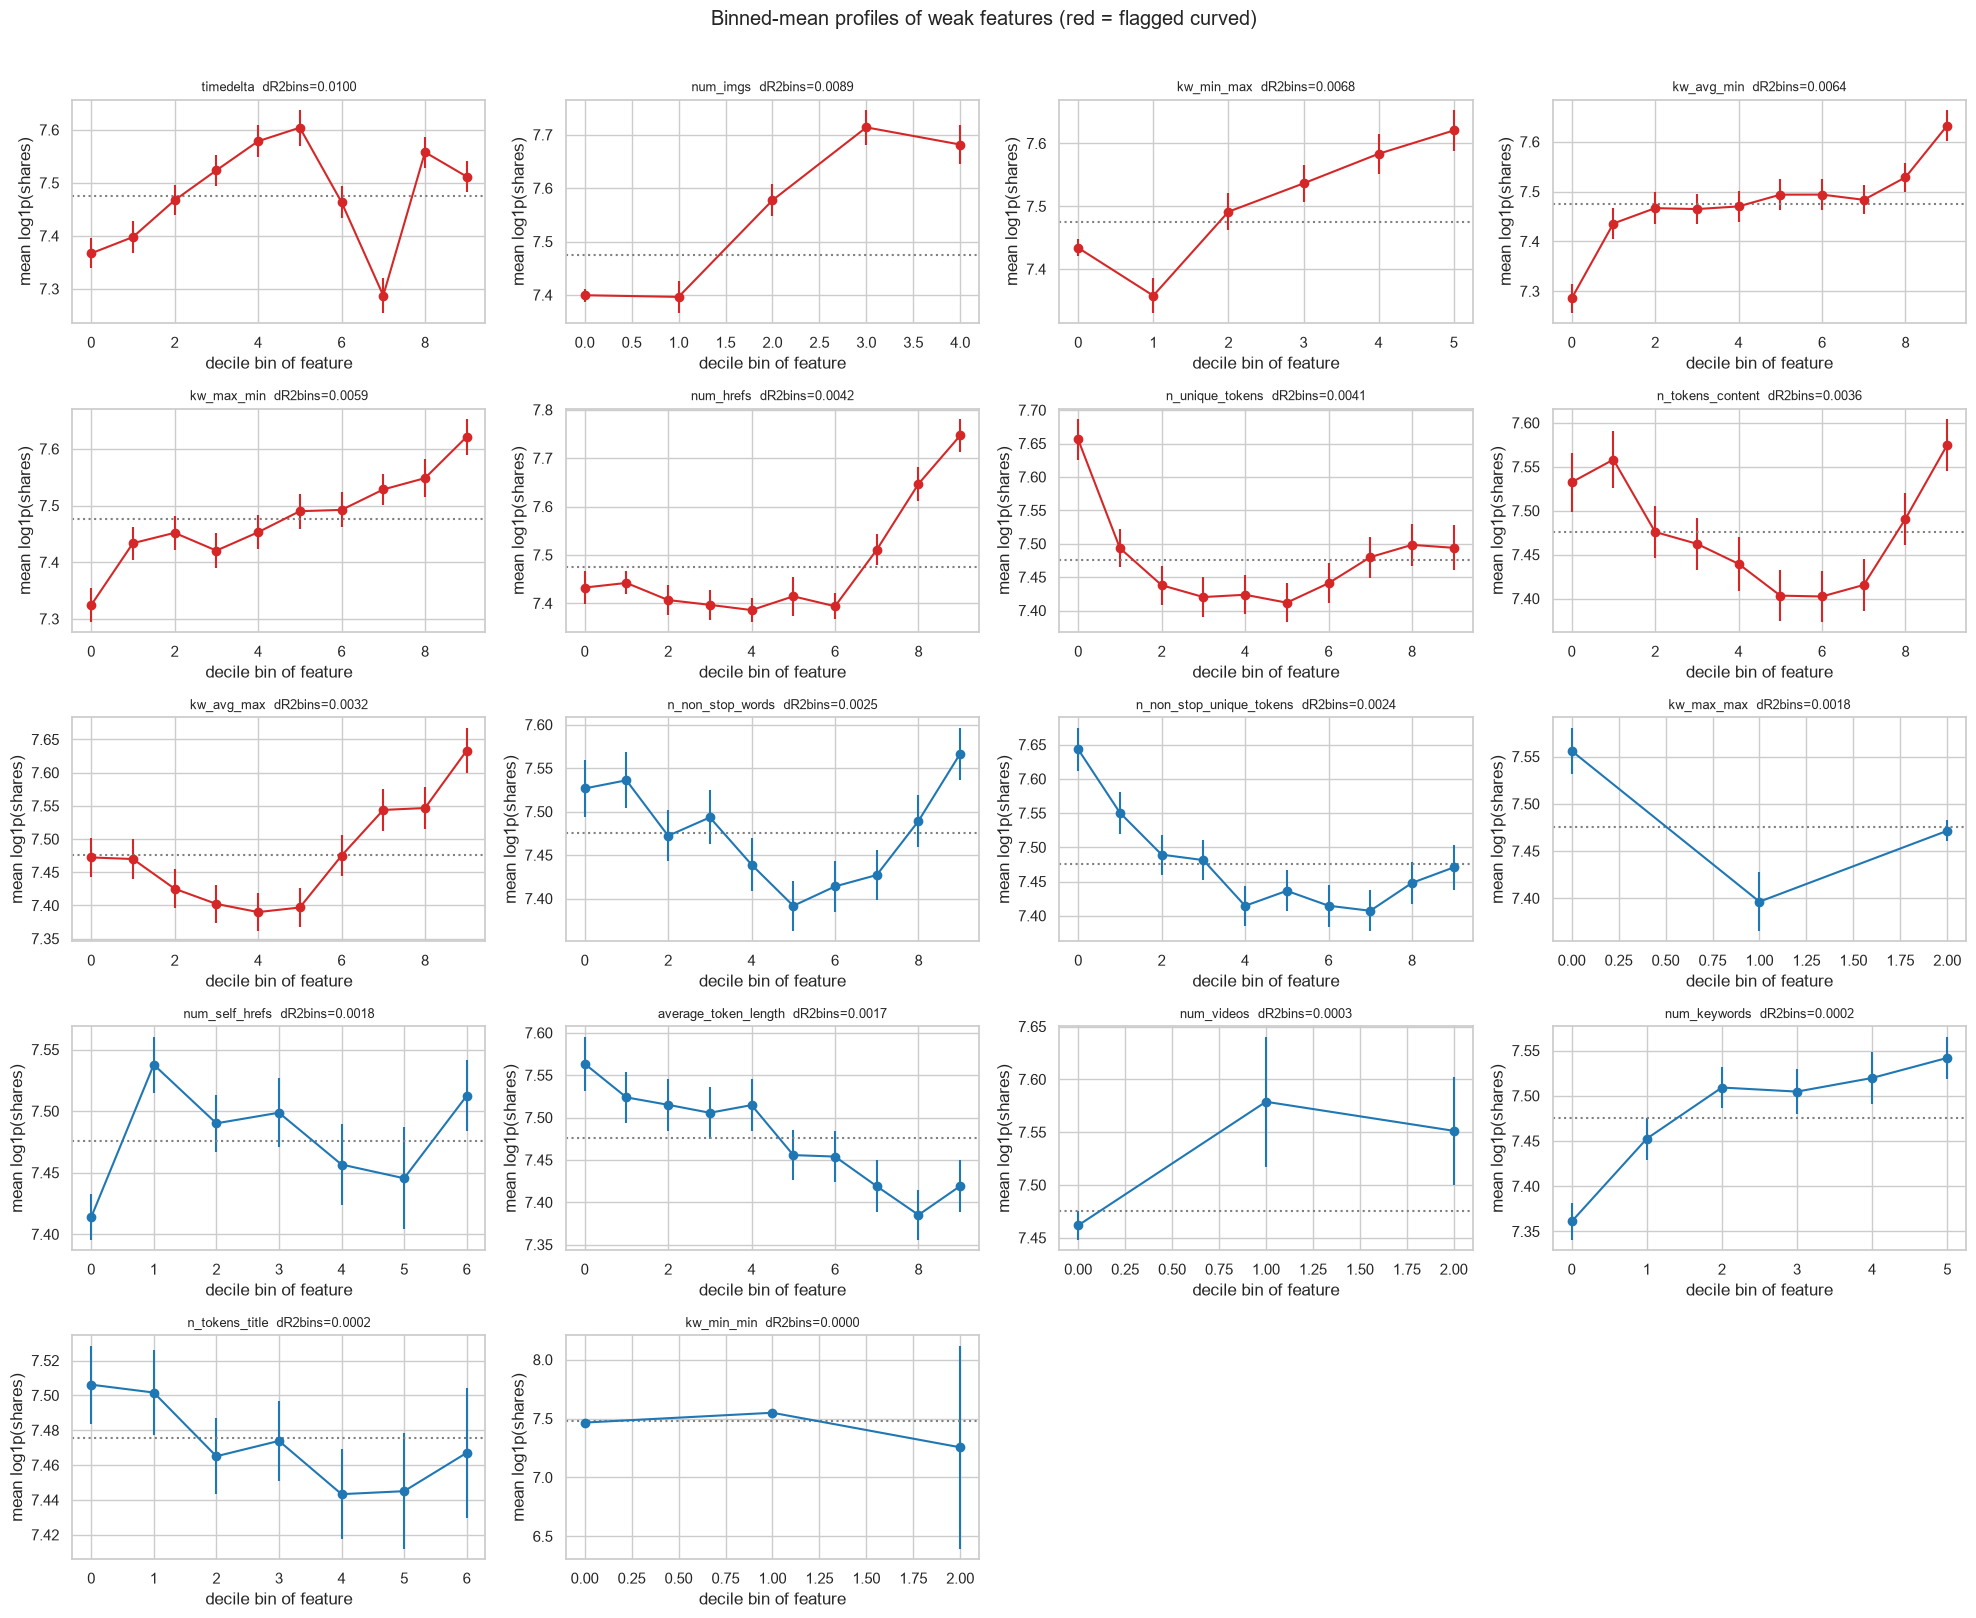

In [23]:
cols = list(nl.index)
ncols = 4; nrows = int(np.ceil(len(cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.2 * nrows)); axes = np.array(axes).ravel()
for ax, c in zip(axes, cols):
    g = binned_profile(df[c], df.log_shares, 10)
    ax.errorbar(range(len(g)), g.y_mean, yerr=1.96 * g.se, marker='o', color='tab:red' if nl.loc[c, 'curved?'] == 'YES' else 'tab:blue')
    ax.axhline(df.log_shares.mean(), color='grey', ls=':')
    ax.set_title(f"{c}  dR2bins={nl.loc[c,'dR2_bins']:.4f}", fontsize=9); ax.set_xlabel('decile bin of feature'); ax.set_ylabel('mean log1p(shares)')
for ax in axes[len(cols):]: ax.axis('off')
plt.suptitle('Binned-mean profiles of weak features (red = flagged curved)', y=1.01); plt.tight_layout(); plt.show()

**Observation:** The profiles show which kind of structure each flagged feature has (error bars are 95% CIs):
- **`timedelta` – genuinely non-monotonic (bin-profile Spearman only 0.26):** mean log-shares rises from ~7.37 (newest articles) to a peak at ~340–430 days, falls sharply to **7.29 for the 504–582 day decile** (median 1,200 vs 1,400 and 1,600 in the adjacent deciles), then recovers to ~7.55. Because `timedelta` is just calendar position (§2), this is a *time-period* effect (and it coincides with a shift of the channel mix: `world` articles are 34% of the newest decile and 13% of the oldest). It is a step-like pattern a linear term would miss.
- **`num_hrefs` – threshold:** flat at ≈ 7.40–7.44 up to the 70th percentile, then rises to 7.75 in the top decile.
- **`num_imgs` – saturating:** the lowest bins (few images) sit at ≈ 7.40; the higher bins reach ≈ 7.7 with no further gain at the top.
- **`n_tokens_content` – U-shaped:** the shortest and the longest articles have the highest means (≈7.5 and ≈7.58) and the middle (deciles 5–7) the lowest (≈7.40). The pattern persists after removing the empty articles. **`n_unique_tokens`:** the lowest decile is highest (7.62 even with empties excluded) and the rest is flat.
- `kw_min_max`, `kw_avg_min`, `kw_max_min`, `kw_avg_max`: monotonic increases with jumps at the extreme bins (the lowest bin of `kw_avg_min` contains the −1 sentinel rows).
- The un-flagged ones (blue) are flat or gently monotonic; `num_keywords` rises with the count and then flattens, but its ΔR² is tiny (0.0002).

In [24]:
# Same nonlinearity diagnostics for ALL numeric features, to see where curved structure adds most beyond a straight line
allnl = pd.DataFrame({c: nonlin_tests(df[c], df.log_shares) for c in num_cols}).T.astype(float)
allnl['spearman'] = biv.spearman
allnl['R2_spearman_sq'] = allnl.spearman ** 2
display(allnl[['R2_linear', 'R2_quad', 'R2_bins', 'dR2_quad', 'dR2_bins', 'spearman', 'R2_spearman_sq', 'profile_monotonic_rho']].sort_values('R2_bins', ascending=False).head(15))

,R2_linear,R2_quad,R2_bins,dR2_quad,dR2_bins,spearman,R2_spearman_sq,profile_monotonic_rho
n_comments,0.1071,0.1913,0.2747,0.0843,0.1677,0.3617,0.1309,0.7091
kw_avg_avg,0.0480,0.0609,0.0692,0.0129,0.0211,0.2547,0.0649,1.0000
kw_max_avg,0.0114,0.0203,0.0572,0.0089,0.0459,0.2228,0.0496,0.9879
self_reference_avg_shares,0.0077,0.0210,0.0479,0.0133,0.0402,0.1909,0.0365,0.9500
self_reference_min_shares,0.0055,0.0193,0.0410,0.0138,0.0355,0.1799,0.0324,0.9500
self_reference_max_shares,0.0062,0.0199,0.0364,0.0137,0.0302,0.1678,0.0281,0.9500
kw_min_avg,0.0117,0.0316,0.0346,0.0199,0.0229,0.1028,0.0106,0.7857
num_imgs,0.0083,0.0115,0.0172,0.0032,0.0089,0.0829,0.0069,0.8000
num_hrefs,0.0109,0.0115,0.0151,0.0006,0.0042,0.0896,0.0080,0.4303
timedelta,0.0005,0.0018,0.0106,0.0013,0.0100,0.0354,0.0013,0.2606


**Observation:** For the stronger features curvature matters more: `n_comments` R² goes from 0.107 (linear) to 0.191 (quadratic) to 0.275 (bins); `kw_max_avg` from 0.011 to 0.057 (bins) and `self_reference_*` from ~0.006 to ~0.03–0.048. `kw_avg_avg` is the most linear of the strong features (0.048 → 0.069). This supports using non-linear learners or log transforms for the keyword and self-reference features, while the weak features add at most ~1 point of R² from curvature.

## 6. Categorical features: size of the differences
For each category: count, median, mean and geometric mean of shares, and the % difference of its median from the overall median (bootstrap 95% CI, 1,000 resamples). Then the largest-vs-smallest comparison and Tukey HSD on `log1p(shares)`.

In [25]:
def boot_median_ci(x, B=1000):
    x = np.asarray(x); idx = RNG.integers(0, len(x), (B, len(x)))
    m = np.median(x[idx], axis=1); return np.percentile(m, [2.5, 97.5])

overall_med = df[TARGET].median()
def cat_table(col, order=None):
    rows = []
    for k, g in df.groupby(col):
        lo, hi = boot_median_ci(g[TARGET].values)
        rows.append(dict(level=k, n=len(g), pct_rows=len(g) / len(df) * 100, median=g[TARGET].median(), mean=g[TARGET].mean(),
                         geo_mean=np.expm1(g.log_shares.mean()), median_ci_lo=lo, median_ci_hi=hi,
                         median_vs_overall_pct=(g[TARGET].median() / overall_med - 1) * 100,
                         geo_mean_vs_overall_pct=(np.expm1(g.log_shares.mean()) / np.expm1(df.log_shares.mean()) - 1) * 100))
    t = pd.DataFrame(rows).set_index('level').sort_values('median', ascending=False)
    return t

tabs = {}
for col in ['weekday', 'channel']:
    tabs[col] = cat_table(col); print(f'--- {col} (overall median = {overall_med:,.0f}) ---'); display(tabs[col])

def extremes(col):
    t = tabs[col]; hi, lo = t.index[0], t.index[-1]
    a = df.loc[df[col] == hi, TARGET].values; b = df.loc[df[col] == lo, TARGET].values
    B = 1000; ratios = np.median(RNG.choice(a, (B, len(a))), axis=1) / np.median(RNG.choice(b, (B, len(b))), axis=1)
    d = (df.loc[df[col] == hi, 'log_shares'].mean() - df.loc[df[col] == lo, 'log_shares'].mean()) / np.sqrt((df.loc[df[col] == hi, 'log_shares'].var() + df.loc[df[col] == lo, 'log_shares'].var()) / 2)
    print(f"{col}: '{hi}' median is {(np.median(a)/np.median(b)-1)*100:.1f}% higher than '{lo}' (95% CI of ratio {np.percentile(ratios,2.5):.2f}-{np.percentile(ratios,97.5):.2f}); Cohen's d on log1p(shares) = {d:.2f}")
extremes('weekday'); extremes('channel')

wk = df.is_weekend == 1
d_wk = (df.loc[wk, 'log_shares'].mean() - df.loc[~wk, 'log_shares'].mean()) / np.sqrt((df.loc[wk, 'log_shares'].var() + df.loc[~wk, 'log_shares'].var()) / 2)
print(f"\nWeekend vs weekday: median {df.loc[wk, TARGET].median():,.0f} vs {df.loc[~wk, TARGET].median():,.0f} "
      f"({(df.loc[wk, TARGET].median() / df.loc[~wk, TARGET].median() - 1) * 100:.1f}% higher); mean {df.loc[wk, TARGET].mean():,.0f} vs {df.loc[~wk, TARGET].mean():,.0f}; Cohen's d (log) = {d_wk:.2f}")
rb, p = rank_biserial(df.loc[wk, 'log_shares'], df.loc[~wk, 'log_shares']); print(f'Rank-biserial = {rb:.3f} (probability weekend article > weekday article = {(rb+1)/2:.1%}), p = {p:.2g}')

--- weekday (overall median = 1,400) ---


,n,pct_rows,median,mean,geo_mean,median_ci_lo,median_ci_hi,median_vs_overall_pct,geo_mean_vs_overall_pct
level,,,,,,,,,
saturday,2212,6.1996,"2,000.0000","4,157.6817","2,362.3920","1,900.0000","2,100.0000",42.8571,33.9690
sunday,2472,6.9283,"1,900.0000","3,732.2617","2,300.2265","1,800.0000","2,000.0000",35.7143,30.4437
friday,5147,14.4254,"1,500.0000","3,314.0591","1,788.8201","1,400.0000","1,500.0000",7.1429,1.4423
monday,5977,16.7517,"1,400.0000","3,652.6164","1,730.2176","1,300.0000","1,400.0000",0.0000,-1.8810
thursday,6563,18.3941,"1,400.0000","3,176.4464","1,666.8903","1,300.0000","1,400.0000",0.0000,-5.4722
tuesday,6646,18.6267,"1,300.0000","3,220.4680","1,663.7253","1,300.0000","1,400.0000",-7.1429,-5.6517
wednesday,6663,18.6743,"1,300.0000","3,275.2484","1,633.8912","1,300.0000","1,300.0000",-7.1429,-7.3436


--- channel (overall median = 1,400) ---


,n,pct_rows,median,mean,geo_mean,median_ci_lo,median_ci_hi,median_vs_overall_pct,geo_mean_vs_overall_pct
level,,,,,,,,,
social_media,2089,5.8548,"2,100.0000","3,590.3351","2,386.4918","2,100.0000","2,200.0000",50.0000,35.3357
Unknown,5462,15.3083,"1,900.0000","5,992.8808","2,487.8051","1,850.0000","2,000.0000",35.7143,41.0811
lifestyle,1884,5.2803,"1,700.0000","3,680.0329","1,996.3227","1,600.0000","1,701.2500",21.4286,13.2096
technology,6642,18.6155,"1,700.0000","3,066.3830","1,958.4086","1,700.0000","1,800.0000",21.4286,11.0595
business,5623,15.7595,"1,400.0000","3,106.4487","1,663.0367","1,400.0000","1,400.0000",0.0000,-5.6908
entertainment,6407,17.9568,"1,200.0000","2,955.6126","1,492.6508","1,100.0000","1,200.0000",-14.2857,-15.3532
world,7573,21.2248,"1,100.0000","2,303.9386","1,345.9964","1,100.0000","1,100.0000",-21.4286,-23.6698


weekday: 'saturday' median is 53.8% higher than 'wednesday' (95% CI of ratio 1.46-1.62); Cohen's d on log1p(shares) = 0.41
channel: 'social_media' median is 90.9% higher than 'world' (95% CI of ratio 1.82-2.00); Cohen's d on log1p(shares) = 0.69



Weekend vs weekday: median 2,000 vs 1,400 (42.9% higher); mean 3,933 vs 3,322; Cohen's d (log) = 0.36
Rank-biserial = 0.262 (probability weekend article > weekday article = 63.1%), p = 7.7e-185


**Observation (size of differences; medians of raw shares, bootstrap 95% CI):**
- **Weekday:** a two-group structure. Saturday median 2,000 (+43% vs the overall median of 1,400; CI 1,900–2,100) and Sunday 1,900 (+36%) versus Monday–Friday between 1,300 and 1,500 (Wednesday and Tuesday −7%, Friday +7%). Saturday vs Wednesday: **+53.8%** (CI of the ratio 1.46–1.62), Cohen's d = 0.41 on log shares (small-to-medium).
- **Weekend vs weekday:** median 2,000 vs 1,400 (**+42.9%**), but means 3,933 vs 3,322 (**+18.4%**), d = 0.36; a random weekend article beats a random weekday article 63.1% of the time (so the overlap is large).
- **Channel:** `social_media` (median 2,100, +50% vs overall), `lifestyle` and `technology` (1,700, +21%), `business` 1,400 (0%), `entertainment` 1,200 (−14%), `world` 1,100 (−21%). Largest gap: `social_media` vs `world` **+90.9%** (CI 1.82–2.00), d = 0.69 (medium).
- **Unknown channel** (NaN): median 1,900 (+36%) and the highest geometric mean (2,488) and arithmetic mean (5,993), higher than any named channel, so the missing channel is not a harmless gap.
- Geometric-mean differences are a bit smaller than median differences for weekday (±1–34%) and similar for channel (−24% to +41%).

--- Tukey HSD on log1p(shares) by weekday: 14 of 21 pairs significant ---


,group1,group2,meandiff,p-adj,reject,pct_diff_geo_mean
6,monday,saturday,0.3113,0.0000,True,36.5199
7,monday,sunday,0.2846,0.0000,True,32.9230
1,friday,saturday,0.2780,0.0000,True,32.0486
14,saturday,wednesday,-0.3685,0.0000,True,-30.8229
13,saturday,tuesday,-0.3504,0.0000,True,-29.5594
12,saturday,thursday,-0.3485,0.0000,True,-29.4254
17,sunday,wednesday,-0.3419,0.0000,True,-28.9581
2,friday,sunday,0.2513,0.0000,True,28.5696
16,sunday,tuesday,-0.3238,0.0000,True,-27.6605
15,sunday,thursday,-0.3219,0.0000,True,-27.5229


--- Tukey HSD on log1p(shares) by channel: 19 of 21 pairs significant ---


,group1,group2,meandiff,p-adj,reject,pct_diff_geo_mean
12,entertainment,social_media,0.4690,0.0000,True,59.8395
5,Unknown,world,-0.6139,0.0000,True,-45.8764
19,social_media,world,-0.5724,0.0000,True,-43.5830
8,business,social_media,0.3610,0.0000,True,43.4763
1,Unknown,entertainment,-0.5106,0.0000,True,-39.9865
11,entertainment,lifestyle,0.2906,0.0000,True,33.7230
0,Unknown,business,-0.4026,0.0000,True,-33.1421
17,lifestyle,world,-0.3939,0.0000,True,-32.5579
20,technology,world,-0.3748,0.0000,True,-31.2573
13,entertainment,technology,0.2714,0.0000,True,31.1800


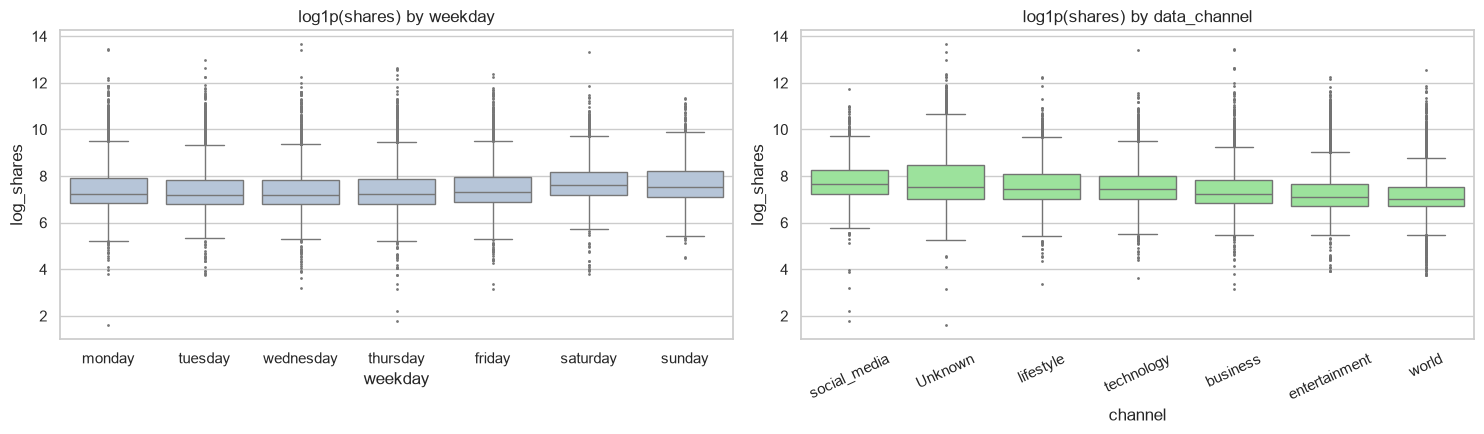

In [26]:
for col in ['weekday', 'channel']:
    tk = pairwise_tukeyhsd(df.log_shares, df[col], alpha=0.05)
    r = pd.DataFrame(tk._results_table.data[1:], columns=tk._results_table.data[0])
    r['meandiff'] = r.meandiff.astype(float); r['pct_diff_geo_mean'] = (np.exp(r.meandiff) - 1) * 100
    print(f'--- Tukey HSD on log1p(shares) by {col}: {int(r.reject.sum())} of {len(r)} pairs significant ---')
    display(r[r.reject].sort_values('pct_diff_geo_mean', key=abs, ascending=False).head(12).drop(columns=['lower', 'upper']))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(x='weekday', y='log_shares', data=df, order=DAYS, ax=ax[0], color='lightsteelblue', fliersize=1); ax[0].set_title('log1p(shares) by weekday')
sns.boxplot(x='channel', y='log_shares', data=df, order=tabs['channel'].index, ax=ax[1], color='lightgreen', fliersize=1); ax[1].set_title('log1p(shares) by data_channel'); ax[1].tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

**Observation:** Tukey HSD (family-wise 5%) on log shares: 14 of 21 weekday pairs are significant: all 10 weekend-vs-Monday–Friday pairs (weekend geometric mean 28–37% higher) plus four small weekday differences (Friday vs Thursday/Tuesday/Wednesday, +7–9%, and Monday vs Wednesday, +6%). Saturday vs Sunday, and Monday vs Tuesday/Thursday/Friday, Tuesday vs Thursday/Wednesday, are not distinguishable. For channel 19 of 21 pairs differ: e.g. `social_media` vs `entertainment` +60%, vs `business` +43%, vs `world` +44%; `Unknown` vs `world` +46%. The boxplots show the same ordering with large within-group spread: the boxes overlap heavily, consistent with the small η² in §5.

## 7. Interaction of the two categorical features (weekday × data_channel)
Cell label = median shares and, in the companion heatmap, the row count behind it. Cells with fewer than 30 rows are masked in the main heatmap.

Median shares:


weekday,monday,tuesday,wednesday,thursday,friday,saturday,sunday
channel,,,,,,,
Unknown,"1,900.0000","1,800.0000","1,800.0000","1,900.0000","2,000.0000","2,500.0000","1,900.0000"
business,"1,400.0000","1,300.0000","1,300.0000","1,300.0000","1,400.0000","2,600.0000","2,200.0000"
entertainment,"1,100.0000","1,100.0000","1,100.0000","1,100.0000","1,200.0000","1,600.0000","1,700.0000"
lifestyle,"1,600.0000","1,500.0000","1,500.0000","1,600.0000","1,500.0000","2,150.0000","2,100.0000"
social_media,"2,400.0000","2,000.0000","2,000.0000","2,000.0000","2,300.0000","2,500.0000","2,350.0000"
technology,"1,600.0000","1,600.0000","1,600.0000","1,600.0000","1,800.0000","2,300.0000","2,400.0000"
world,"1,100.0000","1,100.0000","1,100.0000","1,100.0000","1,100.0000","1,500.0000","1,400.0000"


Rows per cell:


weekday,monday,tuesday,wednesday,thursday,friday,saturday,sunday
channel,,,,,,,
Unknown,791,993,948,981,880,373,496
business,1038,1047,1138,1114,753,223,310
entertainment,1232,1170,1175,1125,874,345,486
lifestyle,294,303,344,315,271,162,195
social_media,298,418,369,424,301,161,118
technology,1110,1342,1281,1181,900,471,357
world,1214,1373,1408,1423,1168,477,510


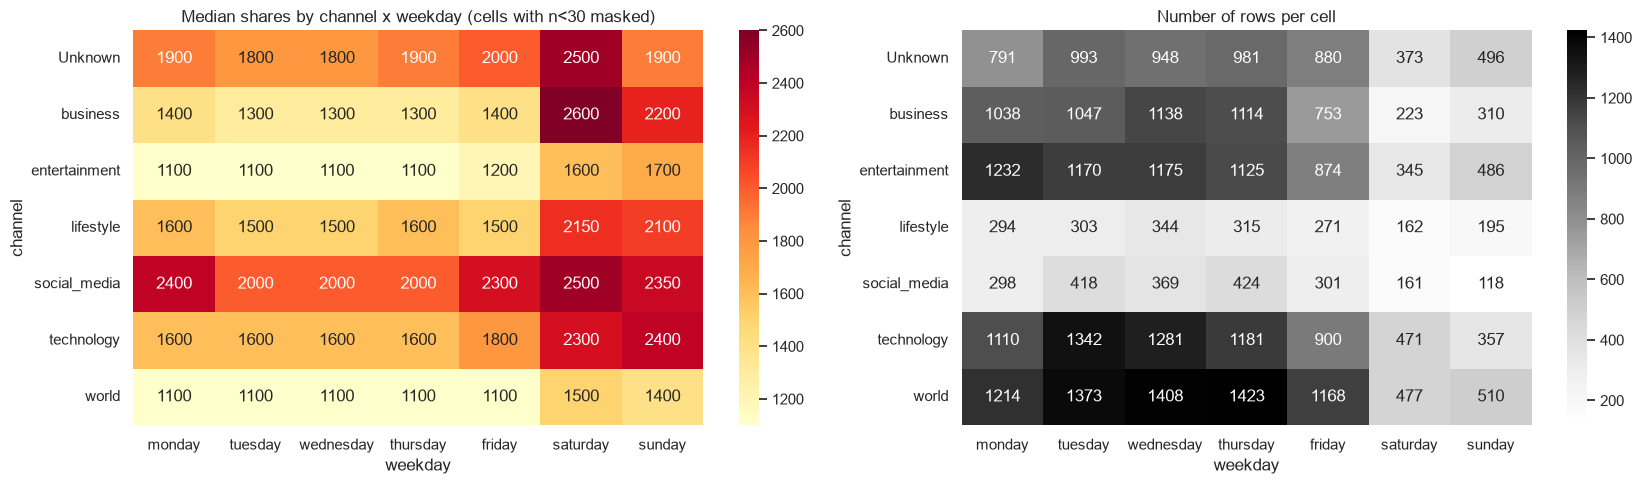

Smallest cells: {('social_media', 'sunday'): 118, ('social_media', 'saturday'): 161, ('lifestyle', 'saturday'): 162, ('lifestyle', 'sunday'): 195, ('business', 'saturday'): 223}


In [27]:
piv_med = df.pivot_table(index='channel', columns='weekday', values=TARGET, aggfunc='median')[DAYS]
piv_n = df.pivot_table(index='channel', columns='weekday', values=TARGET, aggfunc='size')[DAYS]
print('Median shares:'); display(piv_med.round(0))
print('Rows per cell:'); display(piv_n)
mask = piv_n < 30
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
sns.heatmap(piv_med, mask=mask, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax[0]); ax[0].set_title('Median shares by channel x weekday (cells with n<30 masked)')
sns.heatmap(piv_n, annot=True, fmt='d', cmap='Greys', ax=ax[1]); ax[1].set_title('Number of rows per cell')
plt.tight_layout(); plt.show()
print('Smallest cells:', piv_n.stack().nsmallest(5).to_dict())

**Observation:** Median shares by channel × weekday. The weekend column is higher in every channel, but by different amounts: `business` jumps from 1,300–1,400 on weekdays to 2,600 (Sat) / 2,200 (Sun); `social_media` is already high on weekdays (2,000–2,400) and rises only to ~2,350–2,500; `Unknown` is 1,800–2,000 on weekdays and 2,500/1,900 at the weekend. Cell sizes range from **118 (`social_media`×Sunday)** to 1,423 (`world`×Thursday); no cell has fewer than 30 rows, so nothing was masked, but the weekend cells for `social_media`, `lifestyle` (162–195), and `business` Saturday (223) are thin enough that their medians are uncertain (wide uncertainty).

In [28]:
# Departure of each cell from an additive (main-effects-only) expectation on the log scale
cell = df.groupby(['channel', 'weekday']).log_shares.agg(['mean', 'std', 'size'])
gm = df.log_shares.mean()
ch_eff = df.groupby('channel').log_shares.mean() - gm
wd_eff = df.groupby('weekday').log_shares.mean() - gm
cell = cell.reset_index()
cell['expected_additive'] = gm + cell.channel.map(ch_eff) + cell.weekday.map(wd_eff)
cell['resid'] = cell['mean'] - cell.expected_additive
cell['z'] = cell.resid / (cell['std'] / np.sqrt(cell['size']))
cell['pct_vs_additive'] = (np.exp(cell.resid) - 1) * 100
print('Cells that deviate most from additivity (n shown!):')
display(cell.reindex(cell.z.abs().sort_values(ascending=False).index).head(8)[['channel','weekday','size','pct_vs_additive','z']])

m_main = smf.ols('log_shares ~ C(weekday) + C(channel)', df).fit()
m_full = smf.ols('log_shares ~ C(weekday) * C(channel)', df).fit()
m_wk = smf.ols('log_shares ~ is_weekend * C(channel)', df).fit()
print(f'R2 main effects only = {m_main.rsquared:.4f} (adj {m_main.rsquared_adj:.4f}) | R2 with interaction = {m_full.rsquared:.4f} (adj {m_full.rsquared_adj:.4f})')
an = sm.stats.anova_lm(m_full, typ=2); an['partial_eta2'] = an.sum_sq / (an.sum_sq + an.loc['Residual', 'sum_sq'])
display(an)
an2 = sm.stats.anova_lm(m_wk, typ=2); an2['partial_eta2'] = an2.sum_sq / (an2.sum_sq + an2.loc['Residual', 'sum_sq']); print('is_weekend x channel:'); display(an2)

wk_tab = df.groupby(['channel', 'is_weekend']).agg(n=(TARGET, 'size'), median=(TARGET, 'median'), geo_mean=('log_shares', lambda s: np.expm1(s.mean()))).unstack()
wk_tab['weekend_vs_weekday_median_pct'] = (wk_tab[('median', 1)] / wk_tab[('median', 0)] - 1) * 100
display(wk_tab.round(1))

Cells that deviate most from additivity (n shown!):


,channel,weekday,size,pct_vs_additive,z
3,Unknown,sunday,496,-24.6580,-6.4179
9,business,saturday,223,30.6529,5.0843
17,entertainment,sunday,486,16.0522,3.5949
10,business,sunday,310,15.9651,3.5529
30,social_media,saturday,161,-16.7798,-3.4774
2,Unknown,saturday,373,-10.8564,-2.1338
21,lifestyle,friday,271,-8.4058,-1.5806
7,business,friday,753,-4.1797,-1.5230


R2 main effects only = 0.0680 (adj 0.0676) | R2 with interaction = 0.0714 (adj 0.0701)


,sum_sq,df,F,PR(>F),partial_eta2
C(weekday),402.6365,6.0000,83.6904,0.0000,0.0139
C(channel),"1,642.3075",6.0000,341.3636,0.0000,0.0544
C(weekday):C(channel),104.8124,36.0000,3.6310,0.0000,0.0037
Residual,"28,570.2475","35,631.0000",NaN,NaN,0.5000


is_weekend x channel:


,sum_sq,df,F,PR(>F),partial_eta2
C(channel),"1,641.2482",6.0000,340.7630,0.0000,0.0542
is_weekend,370.3896,1.0000,461.4113,0.0000,0.0128
is_weekend:C(channel),77.0652,6.0000,16.0006,0.0000,0.0027
Residual,"28,630.2416","35,666.0000",NaN,NaN,0.5000


n          median              geo_mean            weekend_vs_weekday_median_pct
is_weekend        0    1          0          1          0          1                              
channel                                                                                           
Unknown        4593  869 1,900.0000 2,100.0000 2,456.9000 2,658.0000                       10.5000
business       5090  533 1,400.0000 2,400.0000 1,582.3000 2,674.3000                       71.4000
entertainment  5576  831 1,100.0000 1,600.0000 1,414.1000 2,145.3000                       45.5000
lifestyle      1527  357 1,500.0000 2,100.0000 1,877.7000 2,594.4000                       40.0000
social_media   1810  279 2,100.0000 2,400.0000 2,338.6000 2,721.9000                       14.3000
technology     5814  828 1,600.0000 2,300.0000 1,877.1000 2,637.6000                       43.8000
world          6586  987 1,100.0000 1,500.0000 1,298.5000 1,710.7000                       36.4000

**Observation:** Testing the combined effect directly: a main-effects-only model explains R² = 0.0680 of log shares; adding the full weekday × channel interaction raises it to 0.0714 (adjusted 0.0676 → 0.0701). The interaction term is statistically significant (F = 3.63, p ≈ 0) but its partial η² is only 0.0037, versus 0.054 for channel and 0.014 for weekday. For the simpler weekend × channel version, partial η² = 0.0027.

Where it exists, the pattern is: weekend lift in median shares is largest for `business` (+71%: 1,400 → 2,400, n = 533 weekend rows), then `entertainment` +46%, `technology` +44%, `lifestyle` +40%, `world` +36%, and smallest for `social_media` (+14%, n = 279) and `Unknown` (+10.5%, n = 869). The cells departing most from additivity are `Unknown`×Sunday (−25% vs additive expectation, n = 496), `business`×Saturday (+31%, n = 223), `social_media`×Saturday (−17%, n = 161), `entertainment`×Sunday (+16%, n = 486) and `business`×Sunday (+16%, n = 310). These are the more credible ones (n ≥ 223 for the strongest); the `social_media` cell with n = 161 is a hypothesis rather than a finding. **Overall: a real but small interaction (~0.25 percentage points of extra variance), clearly secondary to the main effects.**

## 8. Outlier analysis
Extreme values are compared directly with typical rows rather than assumed to be noise. (a) The **target's** extremes; (b) **feature** extremes: Q3 + 3×IQR (or the 99th percentile when IQR = 0), compared on `shares` with Mann-Whitney U / rank-biserial effect size.

In [29]:
y = df[TARGET]; q1, q3 = y.quantile([.25, .75]); iqr = q3 - q1
ly = df.log_shares; lq1, lq3 = ly.quantile([.25, .75]); liqr = lq3 - lq1
print(f'Raw shares: 1.5*IQR upper fence = {q3+1.5*iqr:,.0f} -> {(y > q3+1.5*iqr).sum()} rows ({(y > q3+1.5*iqr).mean():.1%}); 3*IQR fence = {q3+3*iqr:,.0f} -> {(y > q3+3*iqr).sum()} rows')
print(f'log1p(shares) fences: lower {np.expm1(lq1-1.5*liqr):,.0f} (rows below: {(ly < lq1-1.5*liqr).sum()}), upper {np.expm1(lq3+1.5*liqr):,.0f} (rows above: {(ly > lq3+1.5*liqr).sum()})')
top1 = y >= y.quantile(.99)
print(f'Top 1% (shares >= {y.quantile(.99):,.0f}): {top1.sum()} rows contribute {y[top1].sum()/y.sum():.1%} of all shares; top 10% contribute {y[y>=y.quantile(.9)].sum()/y.sum():.1%}')
print('Share of rows that are weekend: top1% =', f'{df.loc[top1,"is_weekend"].mean():.1%} vs rest {df.loc[~top1,"is_weekend"].mean():.1%}')
print('Channel mix (top1% vs rest):'); display(pd.concat([df.loc[top1, 'channel'].value_counts(normalize=True).rename('top1%'), df.loc[~top1, 'channel'].value_counts(normalize=True).rename('rest')], axis=1).round(3))

rows = []
for c in num_cols:
    a, b = df.loc[top1, c].dropna(), df.loc[~top1, c].dropna()
    rb, p = rank_biserial(a, b)
    rows.append(dict(feature=c, median_top1=a.median(), median_rest=b.median(), rank_biserial=rb, p=p))
prof = pd.DataFrame(rows).set_index('feature'); prof = prof.reindex(prof.rank_biserial.abs().sort_values(ascending=False).index)
print('Features whose distribution differs most between the top-1% shares rows and the rest:'); display(prof.head(10))
print('Ten largest values of shares:'); display(df.nlargest(10, TARGET)[['URL', TARGET, 'n_comments', 'channel', 'weekday', 'timedelta']])

Raw shares: 1.5*IQR upper fence = 5,581 -> 4080 rows (11.4%); 3*IQR fence = 8,362 -> 2469 rows
log1p(shares) fences: lower 185 (rows below: 139), upper 14,247 (rows above: 1231)
Top 1% (shares >= 32,000): 358 rows contribute 22.0% of all shares; top 10% contribute 54.2%
Share of rows that are weekend: top1% = 13.4% vs rest 13.1%
Channel mix (top1% vs rest):


,top1%,rest
channel,,
Unknown,0.4330,0.1500
entertainment,0.1790,0.1800
business,0.1090,0.1580
world,0.1060,0.2130
technology,0.0810,0.1870
lifestyle,0.0530,0.0530
social_media,0.0390,0.0590


Features whose distribution differs most between the top-1% shares rows and the rest:


,median_top1,median_rest,rank_biserial,p
feature,,,,
n_comments,437.0000,16.0000,0.6609,0.0000
kw_max_avg,"6,603.6302","4,332.9550",0.4402,0.0000
kw_avg_avg,"3,805.5157","2,861.3295",0.4230,0.0000
self_reference_avg_shares,"5,233.3333","2,200.0000",0.3024,0.0000
self_reference_max_shares,"6,900.0000","2,800.0000",0.2711,0.0000
self_reference_min_shares,"2,100.0000","1,200.0000",0.2525,0.0000
kw_avg_max,"306,852.0833","243,630.0000",0.2262,0.0000
num_videos,1.0000,0.0000,0.2203,0.0000
num_hrefs,10.0000,7.0000,0.1445,0.0000


Ten largest values of shares:


,URL,shares,n_comments,channel,weekday,timedelta
8438,http://mashable.com/2013/07/03/low-cost-iphone/,843300,937.0000,Unknown,wednesday,554.0000
4848,http://mashable.com/2013/04/15/dove-ad-beauty-...,690400,"1,381.0000",business,monday,633.0000
20927,http://mashable.com/2014/04/09/first-100-gilt-...,663600,"1,327.0000",technology,wednesday,274.0000
14666,http://mashable.com/2013/11/18/kanye-west-harv...,652900,"6,529.0000",business,monday,416.0000
2828,http://mashable.com/2013/03/02/wealth-inequality/,617900,"61,790.0000",Unknown,saturday,677.0000
14433,http://mashable.com/2013/11/12/roomba-880-review/,441000,"8,820.0000",Unknown,tuesday,422.0000
16932,http://mashable.com/2014/01/14/australia-heatw...,310800,0.0000,business,tuesday,359.0000
4065,http://mashable.com/2013/03/28/blackberry-1-mi...,306100,0.0000,business,thursday,651.0000
14524,http://mashable.com/2013/11/14/ibm-watson-brief/,298400,0.0000,business,thursday,420.0000
31724,http://mashable.com/2014/10/22/ebola-cdc-activ...,284700,"5,694.0000",world,thursday,77.0000


**Observation (target outliers):**
- 11.4% of articles lie above the raw 1.5×IQR fence (5,581 shares) and 6.9% above the 3×IQR fence (8,362): this is the long right tail of a heavy-tailed distribution, not isolated errors. On the log scale only 1,231 (3.4%) exceed the upper fence (14,247) and 139 fall below the lower one (185).
- The top 1% (358 articles, ≥ 32,000 shares) contribute **22.0%** of all shares, the top 10% contribute **54.2%**.
- **They are informative, not noise:** they differ systematically from the rest, e.g. `kw_max_avg` (median 6,604 vs 4,333; rank-biserial 0.44), `kw_avg_avg` (3,806 vs 2,861; 0.42), `self_reference_avg_shares` (5,233 vs 2,200; 0.30), more videos (median 1 vs 0). (`n_comments` is far higher too, 437 vs 16, but see the leakage point.)
- **Channel mix:** the `Unknown` channel supplies **43.3%** of the top-1% articles but only 15.0% of the rest (2.9× over-represented); `world` (10.6% vs 21.3%) and `technology` (8.1% vs 18.7%) are under-represented. Weekend share is no different (13.4% vs 13.1%): virality is not a weekend phenomenon even though typical shares are higher then.
- The ten largest values look like genuine viral stories (the Dove ad, Kanye West, Ebola/CDC…), with no sign of data-entry error, although three of the top ten (>298k shares) have `n_comments = 0`.

,threshold,n_extreme,pct_extreme,median_shares_extreme,median_shares_typical,median_ratio,rank_biserial,MWU_p,Welch_p,pearson_all,pearson_without_extremes,spearman_all,spearman_without_extremes
feature,,,,,,,,,,,,,
n_comments,306.0000,2047,5.7371,"8,600.0000","1,400.0000",6.1429,0.8914,0.0000,0.0000,0.5230,0.1131,0.3617,0.2546
self_reference_avg_shares,"17,732.6667",2154,6.0370,"2,100.0000","1,400.0000",1.5000,0.2528,0.0000,0.0000,0.0590,0.0795,0.1909,0.1677
kw_avg_avg,"7,242.8337",312,0.8744,"2,100.0000","1,400.0000",1.5000,0.2475,0.0000,0.0000,0.1017,0.1143,0.2547,0.2528
self_reference_min_shares,"8,486.0000",2881,8.0746,"2,000.0000","1,400.0000",1.4286,0.2403,0.0000,0.0000,0.0578,0.0502,0.1799,0.1494
self_reference_max_shares,"28,300.0000",2280,6.3901,"2,000.0000","1,400.0000",1.4286,0.2257,0.0000,0.0000,0.0479,0.0736,0.1678,0.1450
num_hrefs,44.0000,643,1.8021,"2,000.0000","1,400.0000",1.4286,0.2150,0.0000,0.0000,0.0450,0.0422,0.0896,0.0810
kw_max_avg,"13,382.7990",1037,2.9064,"1,900.0000","1,400.0000",1.3571,0.1910,0.0000,0.0000,0.0557,0.1028,0.2228,0.2195
n_tokens_content,"2,123.0000",454,1.2724,"1,950.0000","1,400.0000",1.3929,0.1820,0.0000,0.0000,0.0031,-0.0142,0.0089,0.0021
kw_avg_min,"1,003.6786",891,2.4972,"1,800.0000","1,400.0000",1.2857,0.1363,0.0000,0.0000,0.0166,0.0124,0.0953,0.0900


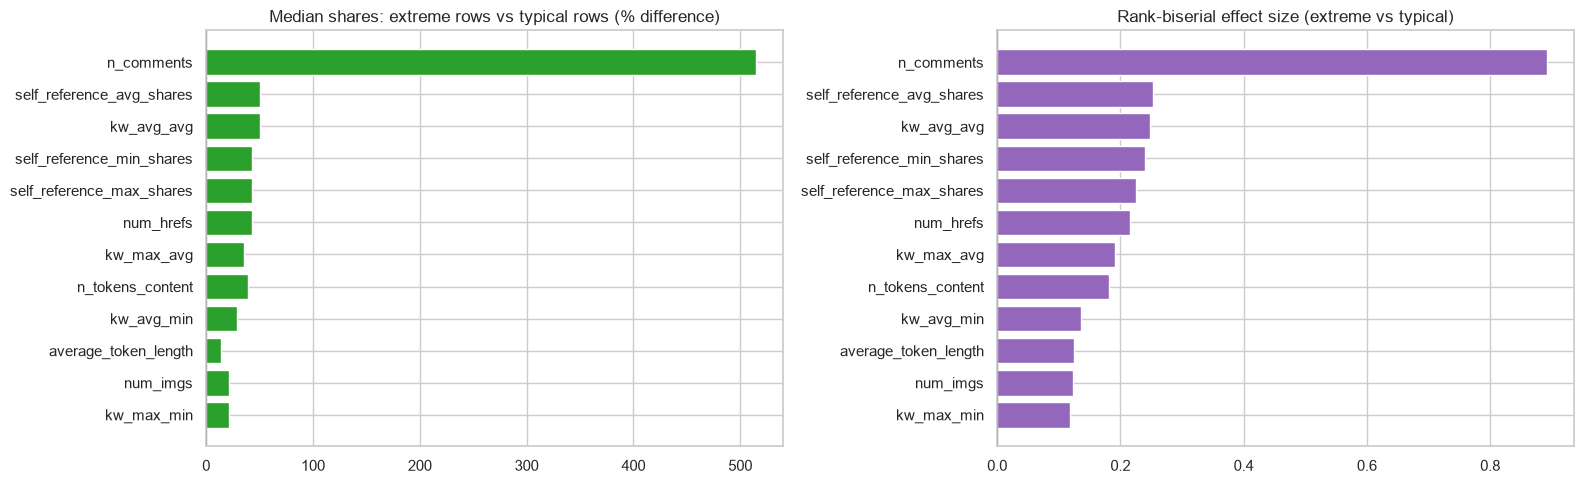

In [30]:
heavy = [c for c in num_cols if abs(df[c].skew()) > 2]
rows = []
for c in heavy:
    x = df[c]; q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    thr = q3 + 3 * iqr if iqr > 0 else x.quantile(.99)
    ext = x > thr; typ = x.notna() & ~ext
    if ext.sum() < 20: continue
    rb, p = rank_biserial(df.loc[ext, 'log_shares'], df.loc[typ, 'log_shares'])
    t, tp = stats.ttest_ind(df.loc[ext, 'log_shares'], df.loc[typ, 'log_shares'], equal_var=False)
    s_all = df[[c, TARGET]].dropna(); s_typ = df.loc[typ, [c, TARGET]]
    rows.append(dict(feature=c, threshold=thr, n_extreme=int(ext.sum()), pct_extreme=ext.mean() * 100,
        median_shares_extreme=df.loc[ext, TARGET].median(), median_shares_typical=df.loc[typ, TARGET].median(),
        median_ratio=df.loc[ext, TARGET].median() / df.loc[typ, TARGET].median(), rank_biserial=rb, MWU_p=p, Welch_p=tp,
        pearson_all=stats.pearsonr(s_all[c], s_all[TARGET])[0], pearson_without_extremes=stats.pearsonr(s_typ[c], s_typ[TARGET])[0],
        spearman_all=stats.spearmanr(s_all[c], s_all[TARGET])[0], spearman_without_extremes=stats.spearmanr(s_typ[c], s_typ[TARGET])[0]))
oe = pd.DataFrame(rows).set_index('feature').sort_values('rank_biserial', key=abs, ascending=False)
display(oe)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
t = oe.head(12)
ax[0].barh(t.index[::-1], (t.median_ratio[::-1] - 1) * 100, color=np.where(t.median_ratio[::-1] > 1, 'tab:green', 'tab:red'))
ax[0].set_title('Median shares: extreme rows vs typical rows (% difference)'); ax[0].axvline(0, color='k', lw=.8)
ax[1].barh(t.index[::-1], t.rank_biserial[::-1], color='tab:purple'); ax[1].set_title('Rank-biserial effect size (extreme vs typical)'); ax[1].axvline(0, color='k', lw=.8)
plt.tight_layout(); plt.show()

**Observation (feature outliers: > Q3 + 3×IQR, or p99 if IQR = 0):**
- **`n_comments` extremes (> 306 comments, 5.7% of rows):** median shares 8,600 vs 1,400 for typical rows, 6.1× (rank-biserial 0.89). They almost *define* the high-share tail, and Pearson with shares falls from 0.52 to 0.11 when they are removed (Spearman 0.36 → 0.25). Informative (and this is the leakage-suspect feature).
- **Moderately informative extremes:** extremes of `self_reference_avg/min/max`, `kw_avg_avg`, `kw_max_avg`, `num_hrefs`, `n_tokens_content` have 1.3–1.5× the typical median shares (rank-biserial 0.18–0.25, p ≈ 0). For `kw_avg_avg` and `kw_max_avg` removing the extremes leaves Spearman unchanged (0.25 → 0.25, 0.22 → 0.22) but *raises* Pearson (0.10 → 0.11 and 0.06 → 0.10): the extreme-keyword articles do not have proportionally extreme shares, so they damp the linear fit; the rank signal lives in the bulk.
- **Weakly informative / ignorable:** `num_videos` extremes (> 4) only 1.07× (rank-biserial 0.05); `average_token_length` extremes (32 rows) show no difference (p = 0.22) and are too few to matter.
- **Conclusion:** extreme feature values are mostly *informative* (they tend to precede higher shares), so deleting them would throw away signal; transforms (log), rank-based or tree models are better responses than removing rows.

## 9. Feature engineering
Candidates are motivated by the findings above (skewed counts, sentinel/zero values, missingness flags, ratios, URL-derived date fields, weekday structure). Each candidate is scored by Pearson and Spearman correlation with `log1p(shares)` and by mutual information (non-parametric, catches non-monotonic dependence; computed on a 15k-row sample with NaNs median-imputed). Priority rank = average of the |Spearman| rank and the MI rank.

In [31]:
u = df.URL.str.extract(r'mashable\.com/(\d{4})/(\d{2})/(\d{2})/([^/]+)/?$')
pub = pd.to_datetime(u[0] + '-' + u[1] + '-' + u[2])
nz = lambda s: s.replace(0, np.nan)
fe, meta = {}, {}
def add(name, series, parent, why, leak=''):
    fe[name] = series; meta[name] = dict(parent=parent, rationale=why, availability_risk=leak)

heavy_pos = [c for c in num_cols if df[c].skew() > 2 and df[c].min() >= 0]
for c in heavy_pos:
    add(f'log_{c}', np.log1p(df[c]), c, 'right-skewed (skew>2): log makes the relation closer to linear and tames outliers',
        'LEAKAGE-suspect' if c == 'n_comments' else '')
add('is_weekend', df.is_weekend, 'weekday', 'weekday effect is mostly weekend vs weekday')
add('channel_unknown', (df.data_channel.isna()).astype(int), 'data_channel', 'NaN channel = a distinct group (maybe "other")')
add('channel_social_media', (df.data_channel == 'social_media').astype(int), 'data_channel', 'highest-median channel')
add('channel_world', (df.data_channel == 'world').astype(int), 'data_channel', 'lowest-median channel')
add('videos_missing', df.num_videos.isna().astype(int), 'num_videos', 'tests whether the 47% NaN carries information')
add('has_video', (df.num_videos.fillna(0) > 0).astype(int), 'num_videos', 'presence of video is simpler than the heavy-tailed count')
add('imgs_missing', df.num_imgs.isna().astype(int), 'num_imgs', 'missing-indicator')
add('hrefs_block_missing', df.num_hrefs.isna().astype(int), 'num_hrefs', '721 rows lose hrefs and all self-reference stats at once')
add('empty_content', (df.n_tokens_content == 0).astype(int), 'n_tokens_content', 'zero-length articles carry 0 placeholders in 3 ratio columns')
add('kw_min_min_sentinel', (df.kw_min_min == -1).astype(int), 'kw_min_min', '-1 is a sentinel for unavailable, 58% of rows')
add('kw_stats_all_zero', (df.kw_avg_avg == 0).astype(int), 'kw_avg_avg', 'all keyword statistics are zero: keyword data unavailable')
add('kw_range_avg', df.kw_max_avg - df.kw_min_avg, 'kw_max_avg', 'spread of keyword popularity within the article')
add('kw_max_over_avg', df.kw_max_avg / nz(df.kw_avg_avg), 'kw_max_avg', 'relative dominance of the best keyword')
add('self_ref_available', df.self_reference_avg_shares.notna().astype(int), 'self_reference_avg_shares', 'missing-indicator for self-reference block')
add('self_ref_zero', (df.self_reference_avg_shares == 0).astype(int), 'self_reference_avg_shares', 'article links only to unshared / no articles')
add('imgs_per_100w', df.num_imgs / nz(df.n_tokens_content) * 100, 'num_imgs', 'image density rather than count (controls for length)')
add('links_per_100w', df.num_hrefs / nz(df.n_tokens_content) * 100, 'num_hrefs', 'link density rather than count')
add('external_hrefs', df.num_hrefs - df.num_self_hrefs, 'num_hrefs', 'links leaving the site')
add('self_link_ratio', df.num_self_hrefs / nz(df.num_hrefs), 'num_self_hrefs', 'share of links that are internal')
add('media_count', df.num_imgs.fillna(0) + df.num_videos.fillna(0), 'num_imgs', 'total rich media')
add('unique_gap', df.n_non_stop_unique_tokens - df.n_unique_tokens, 'n_unique_tokens', 'removes the 0.94 collinearity between the two ratios')
add('comments_per_day', df.n_comments / df.timedelta, 'n_comments', 'engagement velocity (timedelta = days since publication)', 'LEAKAGE-suspect')
add('pub_year', u[0].astype(int), 'timedelta', 'URL date (2013 vs 2014): platform growth / era effect')
add('pub_month', u[1].astype(int), 'timedelta', 'seasonality')
add('pub_ordinal', pub.map(pd.Timestamp.toordinal), 'timedelta', 'continuous calendar time (timedelta is mirror image of it)')
add('weekday_url_mismatch', (pub.dt.day_name().str.lower() != df.weekday).astype(int), 'weekday', 'quality flag for the 24% weekday/URL disagreement')
add('slug_words', u[3].str.count('-') + 1, 'URL', 'headline length proxy from the URL slug')
FE = pd.DataFrame(fe)
print(FE.shape, '| engineered candidates:', FE.shape[1])

(35680, 40) | engineered candidates: 40


**Observation:** 40 candidates were built, each mapped to the EDA finding that motivates it (log for skewed counts; flags for missingness/sentinels; ratios that control for article length; weekend/channel groupings; calendar fields from the URL date). Those derived from `n_comments` are marked `LEAKAGE-suspect`.

In [32]:
y = df.log_shares
samp = FE.sample(15000, random_state=0).index
Xs = FE.loc[samp].copy(); Xs = Xs.fillna(Xs.median()).replace([np.inf, -np.inf], 0)
# KNN-based MI is distorted by heavy ties (e.g. 10% zeros in n_comments), so: flag low-cardinality columns as discrete,
# and break ties among the continuous ones by random-order ranking
rs = np.random.default_rng(0)
Xm = Xs.copy()
disc = np.array([Xs[c].nunique() <= 15 for c in Xs.columns])
for c in Xs.columns[~disc]:
    perm = rs.permutation(len(Xs)); r = pd.Series(Xs[c].values[perm]).rank(method='first').values
    Xm[c] = r[np.argsort(perm)]
mi = pd.Series(mutual_info_regression(Xm, y.loc[samp], discrete_features=disc, random_state=0, n_neighbors=5), index=FE.columns)
rows = []
for c in FE.columns:
    s = pd.concat([FE[c].replace([np.inf, -np.inf], np.nan), y], axis=1).dropna()
    parent = meta[c]['parent']
    p_sp = biv.spearman.get(parent, np.nan) if parent in biv.index else np.nan
    rows.append(dict(feature=c, parent=parent, n=len(s), pearson=stats.pearsonr(s.iloc[:, 0], s.log_shares)[0] if s.iloc[:, 0].std() > 0 else np.nan,
                     spearman=stats.spearmanr(s.iloc[:, 0], s.log_shares)[0], mutual_info=mi[c], parent_spearman=p_sp,
                     availability_risk=meta[c]['availability_risk'], why=meta[c]['rationale']))
fs = pd.DataFrame(rows).set_index('feature')
fs['abs_spearman'] = fs.spearman.abs()
fs['score'] = (fs.abs_spearman.rank(ascending=False) + fs.mutual_info.rank(ascending=False)) / 2
fs = fs.sort_values('score')
fs['priority'] = np.select([fs.abs_spearman >= 0.10, fs.abs_spearman >= 0.05], ['HIGH', 'MEDIUM'], 'LOW')
print('Tier rule: HIGH |Spearman|>=0.10, MEDIUM 0.05-0.10, LOW <0.05; rows are ordered by the combined |Spearman|+MI rank score.')
pd.set_option('display.max_colwidth', 90)
display(fs[['priority', 'parent', 'pearson', 'spearman', 'parent_spearman', 'mutual_info', 'availability_risk', 'why']])

Tier rule: HIGH |Spearman|>=0.10, MEDIUM 0.05-0.10, LOW <0.05; rows are ordered by the combined |Spearman|+MI rank score.


,priority,parent,pearson,spearman,parent_spearman,mutual_info,availability_risk,why
feature,,,,,,,,
log_n_comments,HIGH,n_comments,0.4040,0.3617,0.3617,1.7402,LEAKAGE-suspect,right-skewed (skew>2): log makes the relation closer to linear and tames outliers
comments_per_day,HIGH,n_comments,0.2133,0.3062,0.3617,0.1531,LEAKAGE-suspect,engagement velocity (timedelta = days since publication)
log_kw_avg_avg,HIGH,kw_avg_avg,0.1817,0.2547,0.2547,0.0437,,right-skewed (skew>2): log makes the relation closer to linear and tames outliers
log_kw_max_avg,HIGH,kw_max_avg,0.1665,0.2228,0.2228,0.0421,,right-skewed (skew>2): log makes the relation closer to linear and tames outliers
log_self_reference_avg_shares,HIGH,self_reference_avg_shares,0.1072,0.1909,0.1909,0.0394,,right-skewed (skew>2): log makes the relation closer to linear and tames outliers
log_self_reference_min_shares,HIGH,self_reference_min_shares,0.1047,0.1799,0.1799,0.0266,,right-skewed (skew>2): log makes the relation closer to linear and tames outliers
log_self_reference_max_shares,HIGH,self_reference_max_shares,0.1033,0.1678,0.1678,0.0266,,right-skewed (skew>2): log makes the relation closer to linear and tames outliers
kw_range_avg,HIGH,kw_max_avg,0.0862,0.1307,0.2228,0.0216,,spread of keyword popularity within the article
channel_world,HIGH,data_channel,-0.1509,-0.1678,NaN,0.0161,,lowest-median channel


**Observation (ranked by tier, then by combined rank; tiers by |Spearman|: HIGH ≥ 0.10, MEDIUM 0.05–0.10, LOW < 0.05):**
- **HIGH, leakage-suspect:** `log_n_comments` (ρ 0.36) and `comments_per_day` (0.31). Their mutual information (1.74 nats for `log_n_comments`) is far above any other feature and far above what a correlation of 0.36 could imply (≈0.07 nats for a bivariate normal), consistent with the arithmetic link found in §2. **Do not treat as legitimate predictors.**
- **HIGH, legitimate:** `log_kw_avg_avg` (0.25), `log_kw_max_avg` (0.22), `log_self_reference_avg/min/max_shares` (0.17–0.19), `channel_world` (−0.17), `is_weekend` (0.15), `kw_range_avg` (0.13), `channel_unknown` (0.13), `channel_social_media` (0.11).
- **MEDIUM:** `log_num_imgs`, `log_kw_max_min`, `pub_month` (−0.07; seasonality), `media_count`, `external_hrefs`, `imgs_per_100w`, `log_num_hrefs`, `links_per_100w`, `self_link_ratio`, `log_kw_min_max`.
- **LOW (|ρ| < 0.05, MI ≈ 0):** every missing-value flag (`videos_missing` ρ = −0.002, `imgs_missing`, `hrefs_block_missing`, `self_ref_available`), `kw_min_min_sentinel`, `empty_content`, `weekday_url_mismatch`, `pub_year` (0.001), `slug_words`, `has_video`.
- **Honest caveat:** log transforms keep the Spearman identical to the parent by construction (rank-invariance), so they help linear models only. The *new-information* features do not beat their parents' rank correlation (e.g. `kw_range_avg` 0.13 < `kw_max_avg` 0.22, `imgs_per_100w` 0.074 < `num_imgs` 0.083, `links_per_100w` 0.078 < 0.090). Weekend and channel indicators and `pub_month` are the ones that capture structure not present in a single numeric column. MI estimates for sparse binary flags are small and noisy.

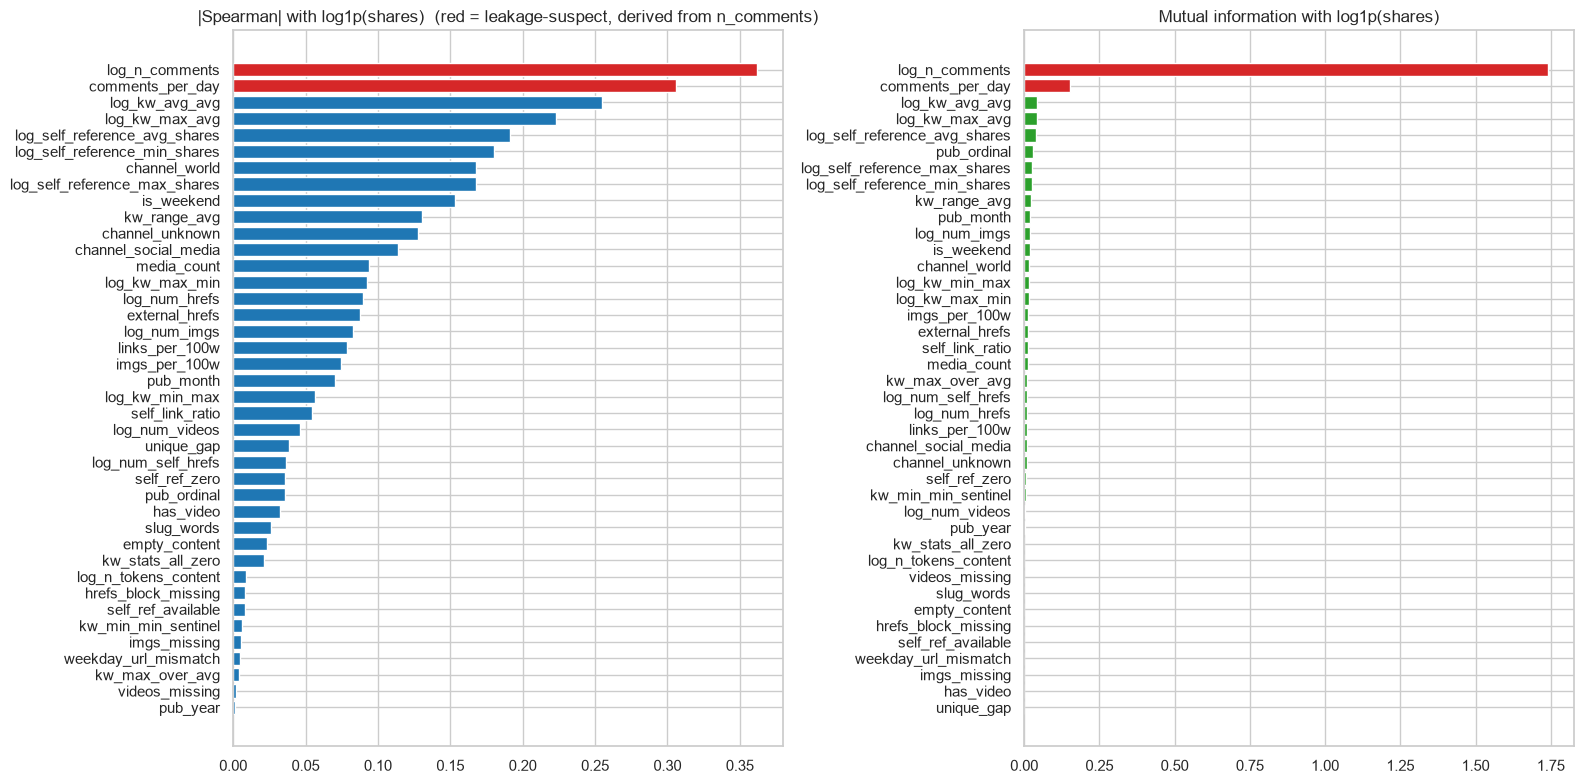

,parent_pearson_raw_vs_logY,log_feature_pearson_vs_logY,gain_in_|r|
log_n_comments,0.3272,0.4040,0.0767
log_kw_max_avg,0.1067,0.1665,0.0598
log_kw_max_min,0.0287,0.0848,0.0560
log_self_reference_min_shares,0.0743,0.1047,0.0304
log_num_videos,0.0338,0.0593,0.0256
log_self_reference_max_shares,0.0786,0.1033,0.0247
log_kw_min_max,0.0089,0.0321,0.0232
log_self_reference_avg_shares,0.0877,0.1072,0.0195
log_num_self_hrefs,0.0283,0.0393,0.0110
log_num_imgs,0.0911,0.0991,0.0080


In [33]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
t = fs.sort_values('abs_spearman')
ax[0].barh(t.index, t.abs_spearman, color=np.where(t.availability_risk != '', 'tab:red', 'tab:blue')); ax[0].set_title('|Spearman| with log1p(shares)  (red = leakage-suspect, derived from n_comments)')
t = fs.sort_values('mutual_info')
ax[1].barh(t.index, t.mutual_info, color=np.where(t.availability_risk != '', 'tab:red', 'tab:green')); ax[1].set_title('Mutual information with log1p(shares)')
plt.tight_layout(); plt.show()

# Did the log transform of skewed parents help? compare Pearson(raw) vs Pearson(log feature) vs log-shares
cmp = pd.DataFrame({'parent_pearson_raw_vs_logY': [biv.loc[p, 'pearson_logY'] for p in fs.loc[[c for c in fs.index if c.startswith('log_')], 'parent']],
                    'log_feature_pearson_vs_logY': fs.loc[[c for c in fs.index if c.startswith('log_')], 'pearson'].values},
                   index=[c for c in fs.index if c.startswith('log_')])
cmp['gain_in_|r|'] = cmp.log_feature_pearson_vs_logY.abs() - cmp.parent_pearson_raw_vs_logY.abs()
display(cmp.sort_values('gain_in_|r|', ascending=False))

**Observation:** The bar charts confirm that the legitimate signals are modest (|ρ| ≤ 0.25; MI ≤ 0.04 nats apart from the leakage-suspect features). The table shows where a log transform actually helps the linear (Pearson vs log-shares) relationship: `log_kw_max_avg` (+0.060), `log_kw_max_min` (+0.056), `log_self_reference_min_shares` (+0.030), `log_num_videos` (+0.026); it hurts or is neutral for `log_kw_avg_avg` (−0.037, already near-linear on the log target), `log_num_hrefs` (−0.024) and `log_n_tokens_content` (≈ 0). So log-transforming everything is not automatically better.

## 10. Synthesis

In [34]:
print('Top drivers (|Spearman| vs shares), with Pearson on raw and log target:')
display(biv[['pearson_raw', 'pearson_logY', 'pearson_logX_logY', 'spearman']].head(10))
print('Categorical association (eta-squared on log1p(shares)):'); display(cat_assoc[['eta2_log_shares', 'eta2_raw_shares']])
print('Features flagged curved (beyond straight line):', list(nl.index[nl['curved?'] == 'YES']))
print('Features with Spearman-minus-Pearson gap > 0.05:', list(biv.index[biv.gap_raw > 0.05]))
print('Top engineered features:'); display(fs[['priority', 'spearman', 'mutual_info', 'availability_risk']].head(10))

Top drivers (|Spearman| vs shares), with Pearson on raw and log target:


,pearson_raw,pearson_logY,pearson_logX_logY,spearman
feature,,,,
n_comments,0.5230,0.3272,0.4040,0.3617
kw_avg_avg,0.1017,0.2192,0.1817,0.2547
kw_max_avg,0.0557,0.1067,0.1665,0.2228
self_reference_avg_shares,0.0590,0.0877,0.1072,0.1909
self_reference_min_shares,0.0578,0.0743,0.1047,0.1799
self_reference_max_shares,0.0479,0.0786,0.1033,0.1678
kw_min_avg,0.0382,0.1084,NaN,0.1028
kw_avg_min,0.0166,0.0362,NaN,0.0953
kw_max_min,0.0160,0.0287,0.0848,0.0922


Categorical association (eta-squared on log1p(shares)):


,eta2_log_shares,eta2_raw_shares
feature,,
weekday,0.0146,0.0005
channel,0.0549,0.0095
is_weekend,0.0136,0.0003


Features flagged curved (beyond straight line): ['timedelta', 'num_imgs', 'kw_min_max', 'kw_avg_min', 'kw_max_min', 'num_hrefs', 'n_unique_tokens', 'n_tokens_content', 'kw_avg_max']
Features with Spearman-minus-Pearson gap > 0.05: ['kw_avg_avg', 'kw_max_avg', 'self_reference_avg_shares', 'self_reference_min_shares', 'self_reference_max_shares', 'kw_min_avg', 'kw_avg_min', 'kw_max_min', 'n_non_stop_unique_tokens', 'kw_min_max']
Top engineered features:


,priority,spearman,mutual_info,availability_risk
feature,,,,
log_n_comments,HIGH,0.3617,1.7402,LEAKAGE-suspect
comments_per_day,HIGH,0.3062,0.1531,LEAKAGE-suspect
log_kw_avg_avg,HIGH,0.2547,0.0437,
log_kw_max_avg,HIGH,0.2228,0.0421,
log_self_reference_avg_shares,HIGH,0.1909,0.0394,
log_self_reference_min_shares,HIGH,0.1799,0.0266,
log_self_reference_max_shares,HIGH,0.1678,0.0266,
kw_range_avg,HIGH,0.1307,0.0216,
channel_world,HIGH,-0.1678,0.0161,


**Observation:** This cell pulls the headline numbers together for the synthesis below.

### 10.1 Findings about the data

**Target.** `shares` is a heavy-tailed count (median 1,400; mean 3,402; skew 34; max 843,300). The top 1% of articles hold 22% of all shares and the top 10% hold 54%. On the log scale the distribution is near-symmetric (skew 1.04). All effects below are therefore best expressed in log/relative terms.

**Strongest drivers (legitimate features)**, by Spearman with shares: `kw_avg_avg` 0.25, `kw_max_avg` 0.22, `self_reference_avg/min/max_shares` 0.17–0.19, then `kw_min_avg`, `kw_avg_min`, `kw_max_min`, `num_hrefs`, `num_imgs` at 0.08–0.10. Everything else has |ρ| < 0.07. The best legitimate feature accounts for roughly 6% of the rank variance; the signal is spread thinly over many weak features, so expect a modest ceiling on predictability (the combined categorical and numeric features explain far from all of the variance).

**`n_comments` is the single strongest correlate (ρ 0.36, Pearson 0.52) but is leakage-suspect:** `shares / n_comments` takes a handful of exact values (six ratios cover 43.8% of rows vs 4.1% under shuffling) and `n_comments ≤ shares/9` always. It should not be regarded as independent evidence of what drives shares.

**Category effects (size, not just significance).**
- `data_channel` (η² = 0.055 on log shares): `social_media` median 2,100 and `world` 1,100, i.e. +91% between the extremes (Cohen's d 0.69, medium); `lifestyle`/`technology` ≈ +21% vs overall; `entertainment` −14%; `Unknown` (missing channel) +36% with the heaviest tail (43% of the top-1% articles).
- `weekday` (η² = 0.015): a weekend-vs-weekday contrast, not a day-by-day gradient: weekend median 2,000 vs 1,400 (+43%) but only +18% in the mean, d = 0.36; among weekdays only tiny differences exist (Friday is +7–9% above Thu/Tue/Wed; Monday +6% above Wednesday), versus a 28–37% weekend lift in geometric mean.
- Interaction (weekday × channel): present but small (partial η² 0.0037; +0.25 points of adjusted R² beyond main effects). The weekend lift is largest for `business` (+71%) and smallest for `social_media` (+14%) and `Unknown` (+10%). Cells with n < ~250 should be treated as hypotheses.

**Non-linearity (calibrated).** Spearman exceeds Pearson-with-log-shares by a meaningful margin for `kw_max_avg` (+0.12), `self_reference_*` (+0.09–0.11), `kw_max_min` and `kw_avg_min` (+0.06): real monotone, log-shaped relations. Among the 18 features weak on *both* correlations, 9 show non-monotonic or threshold structure on the effect-size rule (`timedelta`, `num_imgs`, `num_hrefs`, `n_tokens_content`, `n_unique_tokens`, `kw_min_max`, `kw_avg_min`, `kw_max_min`, `kw_avg_max`), but each adds **at most ~1 percentage point of R²** beyond a straight line. Concrete shapes: `timedelta` is a calendar-period effect with a clear dip around 504–582 days; `num_hrefs` has a threshold near the top 30%; `num_imgs` saturates after ~3; `n_tokens_content` is U-shaped. Real but small.

**Outliers.** Extreme values are informative and not data errors: target extremes differ systematically in keyword popularity, self-reference shares and channel mix; extreme feature values mostly coincide with 1.3–1.5× higher median shares (6× for `n_comments`). The exceptions are very small sets (e.g. 32 extreme `average_token_length` rows) with no detectable difference.

**Data-quality facts a model must respect:** 47% of `num_videos` is missing but appears random; `data_channel` NaN (15%) is informative; 721 rows lose five link/self-reference columns together; 1,061 empty articles carry placeholder zeros; `kw_min_min = −1` (58%) and `kw_max_max = 843,300` (76%) are sentinels/ceilings; the `weekday` column disagrees with the URL date for 24% of rows, increasingly through 2014, with the reported `weekday` the more credible label.

### 10.2 Preprocessing and modelling implications (kept separate from the data findings)

1. **Target:** model `log1p(shares)` (or use a loss robust to the heavy tail) and report errors on both scales; raw-scale RMSE/R² will be dominated by ~1% of articles.
2. **Exclude `n_comments` and everything derived from it** unless it is genuinely available (and not arithmetically derived) at prediction time; evaluate with and without it to quantify the leakage.
3. **Missing values:** impute counts for the 721-row block and `num_imgs` with a constant/median (flags carry no signal); treat `num_videos` NaN as "unknown", or 0 with no loss of information; keep `data_channel` NaN as its own category ("Unknown").
4. **Sentinels/placeholders:** convert `kw_min_min = −1` (and negative `kw_avg_min`/`kw_min_avg`) to NaN or a flag; treat the 1,061 empty-article zeros as missing for the four ratio/length features.
5. **Collinearity** (|r| > 0.8 pairs among `kw_*`, `self_reference_*` and the two unique-token ratios): drop or combine for linear models; harmless for tree ensembles.
6. **Transforms:** log-transform skewed features for linear models, where it helps (`kw_max_avg`, `kw_max_min`, `self_reference_*`), but not blindly (`kw_avg_avg`, `num_hrefs` do not benefit). Tree-based models are invariant to monotone transforms and can pick up the thresholds/U-shapes found in §5.2.
7. **Features worth building first:** `is_weekend`, channel as a categorical (with Unknown), `log` keyword/self-reference columns, calendar position (`timedelta` or the URL date) as a numeric feature that a model can bend, `pub_month`; keep rows with extreme feature values.
8. **Validation:** use a time-aware split or at least check for era effects (the `timedelta` pattern and the channel mix shift over time); stratify on shares quantiles for random splits.
9. **Expectations:** non-leaky features give only a small R² on log shares; a modest score is not evidence of a modelling bug.

## 11. Data cleaning

From here on the notebook is a **self-contained modelling workflow**: everything needed (imports, constants, transformer classes, models) is defined below, starting from the raw CSV, so Sections 11-18 can be run on their own once the data file is in place.

**Problem type (from §1):** supervised **regression**. The target `shares` is a continuous, heavily right-skewed non-negative count, so the **regression** branch of the project specification applies (no class labels, so no stratified split and no class-balance handling). Models are fitted to `log1p(shares)` (the EDA showed raw shares are dominated by ~1% of articles) and evaluated on the log scale (primary) and, for reference, on the raw scale.

**Cleaning policy.** Row-level clean-up that uses no statistics from the data (text normalisation, de-duplication, invalid-target removal) is done once, before the split. Everything that *could* leak (imputation values, clipping bounds, learned transform lists, scaling) is learned **only inside the scikit-learn pipeline** from the training split. Stateless column-level fixes found in the EDA are implemented in a `DataCleaner` transformer that is the first pipeline step.

Requirements: `pandas`, `numpy`, `scipy`, `statsmodels`, `scikit-learn >= 1.2`, `matplotlib`, `seaborn`.

In [35]:
import os, time, platform, warnings, sklearn
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 220, 'display.max_columns', 80, 'display.float_format', lambda x: f'{x:,.4f}')
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

SEED = 42
TARGET = 'shares'
CAT_COLS = ['weekday', 'data_channel']
DATA_PATH = next((p for p in ['data/mini_project_1_data.csv', '../data/mini_project_1_data.csv', 'mini_project_1_data.csv'] if os.path.exists(p)), None)
assert DATA_PATH is not None, 'Put mini_project_1_data.csv in a ./data folder next to this notebook'
print(f'python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}')
print('data file:', DATA_PATH, '| random seed:', SEED)

python 3.12.10 | pandas 3.0.5 | numpy 2.5.2 | scikit-learn 1.9.0
data file: data/mini_project_1_data.csv | random seed: 42


**Observation:** This cell makes Sections 11-18 independent of the EDA code above: it imports everything it needs, fixes the random seed (42), prints the library versions (pandas 3.0, scikit-learn 1.9) and locates the CSV relative to the notebook (`./data/`, `../data/` or next to it).

In [36]:
raw = pd.read_csv(DATA_PATH)
steps = [('rows loaded', len(raw))]

# (a) structural: normalise categorical text (strip + lower); the EDA found none needed, the step guards re-runs on new data
lv_before = {c: raw[c].nunique(dropna=True) for c in CAT_COLS}
for c in CAT_COLS:
    raw[c] = raw[c].str.strip().str.lower()
steps.append(('categorical levels before -> after normalisation', f"{lv_before} -> {({c: raw[c].nunique(dropna=True) for c in CAT_COLS})}"))

# (b) invalid target rows (missing or non-positive)
bad = raw[TARGET].isna() | (raw[TARGET] <= 0)
raw = raw.loc[~bad]
steps.append(('rows removed: missing / non-positive target', int(bad.sum())))

# (c) duplicates: exact duplicates ignoring the ID, and repeated URLs (same article)
dup_cols = [c for c in raw.columns if c != 'ID']
n_exact, n_url = int(raw.duplicated(subset=dup_cols).sum()), int(raw.duplicated(subset=['URL']).sum())
raw = raw.drop_duplicates(subset=dup_cols).drop_duplicates(subset=['URL']).reset_index(drop=True)
steps += [('rows removed: exact duplicates (ignoring ID)', n_exact), ('rows removed: duplicate URLs', n_url), ('rows kept', len(raw))]
display(pd.DataFrame(steps, columns=['cleaning step', 'result']).set_index('cleaning step'))

# (d) features / target. ID is dropped: it is a reverse clock (Spearman with timedelta = -0.99999), i.e. a time stamp and not a feature.
y_raw = raw[TARGET].astype(float)
y_log = np.log1p(y_raw)
X_all = raw.drop(columns=['ID', TARGET])
print('X_all:', X_all.shape, '| target (raw) median', y_raw.median(), '| target (log1p) mean', round(y_log.mean(), 3))

,result
cleaning step,
rows loaded,35680
categorical levels before -> after normalisation,"{'weekday': 7, 'data_channel': 6} -> {'weekday': 7, 'data_channel': 6}"
rows removed: missing / non-positive target,0
rows removed: exact duplicates (ignoring ID),0
rows removed: duplicate URLs,0
rows kept,35680


X_all: (35680, 28) | target (raw) median 1400.0 | target (log1p) mean 7.476


**Observation:** The cleaning steps find **nothing to remove**: no invalid targets, no exact duplicates (ignoring `ID`), no duplicate URLs, and the categorical levels are unchanged by normalisation (7 weekdays, 6 channels). All 35,680 rows are kept, which matches the EDA data-quality results; the steps stay in the workflow as guards for refreshed data. `ID` and the target are removed from the feature matrix, leaving 28 input columns (`ID` is a time stamp in disguise, see §2). The modelling target is `log1p(shares)` (mean 7.476).

In [37]:
RATIO_COLS = ['n_unique_tokens', 'n_non_stop_words', 'n_non_stop_unique_tokens', 'average_token_length']
SENTINEL_COLS = ['kw_min_min', 'kw_avg_min', 'kw_min_avg']      # a negative value means "not available"
LEAKY_COLS = ['n_comments']                                      # see the leakage evidence in section 2


class DataCleaner(BaseEstimator, TransformerMixin):
    """Stateless structural cleaning and missingness indicators (first step of the pipeline).

    * normalises categorical text; missing data_channel becomes the explicit level 'unknown'
    * adds indicator columns: num_videos_missing, num_imgs_missing, hrefs_block_missing, channel_unknown,
      empty_content, kw_min_min_sentinel
    * turns placeholder values into NaN so the imputer treats them as missing: the 4 ratio/length columns of
      empty articles (placeholder 0) and negative kw_* sentinels
    * optionally drops leakage-suspect columns (n_comments)
    Learns nothing from the data, so it cannot leak.
    """
    def __init__(self, drop_leaky=True, add_indicators=True):
        self.drop_leaky = drop_leaky
        self.add_indicators = add_indicators

    def fit(self, X, y=None):
        self.feature_names_out_ = np.array(self.transform(X.head(5)).columns)
        return self

    def transform(self, X):
        X = X.copy()
        for c in CAT_COLS:
            X[c] = X[c].astype('object').where(X[c].notna(), np.nan)
            X[c] = X[c].str.strip().str.lower()
        empty = X['n_tokens_content'] == 0
        if self.add_indicators:
            X['num_videos_missing'] = X['num_videos'].isna().astype(int)
            X['num_imgs_missing'] = X['num_imgs'].isna().astype(int)
            X['hrefs_block_missing'] = X['num_hrefs'].isna().astype(int)
            X['channel_unknown'] = X['data_channel'].isna().astype(int)
            X['empty_content'] = empty.astype(int)
            X['kw_min_min_sentinel'] = (X['kw_min_min'] < 0).astype(int)
        X['data_channel'] = X['data_channel'].fillna('unknown')
        X.loc[empty, RATIO_COLS] = np.nan
        for c in SENTINEL_COLS:
            X.loc[X[c] < 0, c] = np.nan
        if self.drop_leaky:
            X = X.drop(columns=[c for c in LEAKY_COLS if c in X.columns])
        return X

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_out_


# audit: what does the cleaner change on the full (still untouched-by-split) data?
_clean = DataCleaner().fit(X_all).transform(X_all)
audit = pd.DataFrame({
    'new indicator column': ['num_videos_missing', 'num_imgs_missing', 'hrefs_block_missing', 'channel_unknown', 'empty_content', 'kw_min_min_sentinel'],
}).assign(rows_flagged=lambda t: [int(_clean[c].sum()) for c in t['new indicator column']],
          pct=lambda t: [round(_clean[c].mean() * 100, 2) for c in t['new indicator column']])
display(audit)
chg = pd.DataFrame({'NaN before': X_all[RATIO_COLS + SENTINEL_COLS].isna().sum(), 'NaN after cleaning': _clean[RATIO_COLS + SENTINEL_COLS].isna().sum()})
display(chg)
print('Columns dropped as leakage-suspect:', [c for c in X_all.columns if c not in _clean.columns])
print('data_channel levels after cleaning:', sorted(_clean.data_channel.unique()))

,new indicator column,rows_flagged,pct
0,num_videos_missing,16755,46.9600
1,num_imgs_missing,1419,3.9800
2,hrefs_block_missing,721,2.0200
3,channel_unknown,5462,15.3100
4,empty_content,1061,2.9700
5,kw_min_min_sentinel,20660,57.9000


,NaN before,NaN after cleaning
n_unique_tokens,0,1061
n_non_stop_words,0,1061
n_non_stop_unique_tokens,0,1061
average_token_length,0,1061
kw_min_min,0,20660
kw_avg_min,0,767
kw_min_avg,0,6


Columns dropped as leakage-suspect: ['n_comments']
data_channel levels after cleaning: ['business', 'entertainment', 'lifestyle', 'social_media', 'technology', 'unknown', 'world']


**Observation:** `DataCleaner` is stateless (it learns nothing from the data), so it is safe to apply before the split inside the pipeline. On the full data it:
- adds six missingness / sentinel indicators: `num_videos_missing` (16,755 rows, 46.96%), `num_imgs_missing` (1,419; 3.98%), `hrefs_block_missing` (721; 2.02%), `channel_unknown` (5,462; 15.31%), `empty_content` (1,061; 2.97%) and `kw_min_min_sentinel` (20,660; 57.90%), exactly the counts found in the EDA;
- converts placeholders into real NaN so they are imputed instead of being read as values: the four ratio / word-length columns of the 1,061 empty articles, and the negative `kw_*` sentinels (`kw_min_min` 20,660, `kw_avg_min` 767, `kw_min_avg` 6);
- gives the missing `data_channel` its own level, `unknown` (7 channel levels), and drops the leakage-suspect `n_comments`.

## 12. Feature engineering (scikit-learn-compatible transformers)
The candidates come from the EDA (§9, tiers HIGH/MEDIUM). Anything that learns from the data (which columns are skewed enough to log-transform; clipping bounds) is learned in `fit` on the **training split only**. Both classes follow the scikit-learn API (`fit`/`transform`/`get_feature_names_out`, constructor parameters only) so they can be cloned, cross-validated and tuned.

In [38]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Adds engineered features (EDA section 9). Learns which columns to log-transform in fit.

    Adds: is_weekend, imgs_per_100w, links_per_100w, external_hrefs, self_link_ratio, media_count,
          kw_range_avg, pub_month (from the URL date), and log_<col> for every non-negative, non-binary numeric
          column whose training skewness exceeds `skew_threshold`. Drops the URL string afterwards.
    """
    def __init__(self, skew_threshold=2.0, add_ratios=True, add_log=True):
        self.skew_threshold = skew_threshold
        self.add_ratios = add_ratios
        self.add_log = add_log

    def fit(self, X, y=None):
        num = X.select_dtypes('number')
        self.log_cols_ = [c for c in num.columns if num[c].nunique() > 2 and num[c].min() >= 0 and num[c].skew() > self.skew_threshold]
        self.feature_names_out_ = np.array(self.transform(X.head(5)).columns)
        return self

    def transform(self, X):
        X = X.copy()
        X['is_weekend'] = X['weekday'].isin(['saturday', 'sunday']).astype(int)
        X['pub_month'] = X['URL'].str.extract(r'/(\d{4})/(\d{2})/')[1].astype(float)
        if self.add_ratios:
            words = X['n_tokens_content'].replace(0, np.nan)
            X['imgs_per_100w'] = X['num_imgs'] / words * 100
            X['links_per_100w'] = X['num_hrefs'] / words * 100
            X['external_hrefs'] = X['num_hrefs'] - X['num_self_hrefs']
            X['self_link_ratio'] = X['num_self_hrefs'] / X['num_hrefs'].replace(0, np.nan)
            X['media_count'] = X['num_imgs'].fillna(0) + X['num_videos'].fillna(0)
            X['kw_range_avg'] = X['kw_max_avg'] - X['kw_min_avg']
        if self.add_log:
            for c in getattr(self, 'log_cols_', []):
                if c in X.columns:
                    X['log_' + c] = np.log1p(X[c].clip(lower=0))
        return X.drop(columns=['URL'])

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_out_


class Winsorizer(BaseEstimator, TransformerMixin):
    """Outlier handling: clip each non-binary numeric column to its [lower, upper] training quantiles.

    EDA section 8 showed extreme feature values are informative, so rows are never deleted;
    clipping at the 1st/99th percentile only limits their leverage on distance- and
    least-squares-based models. Quantiles come from the training split in `fit`.
    """
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = np.array(X.columns)
        self.lo_ = X.quantile(self.lower)
        self.hi_ = X.quantile(self.upper)
        binary = X.nunique() <= 2
        self.lo_[binary] = -np.inf
        self.hi_[binary] = np.inf
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        return X.clip(lower=self.lo_, upper=self.hi_, axis=1)

    def get_feature_names_out(self, input_features=None):
        return self.columns_


# quick demonstration on the full data (only to show the output columns; the pipeline below fits on train only)
_fe = FeatureEngineer().fit(_clean)
_eng = _fe.transform(_clean)
new_cols = [c for c in _eng.columns if c not in _clean.columns]
print('Learned log-transform columns (fit):', _fe.log_cols_)
print(f'{len(new_cols)} new columns:', new_cols)
display(_eng[new_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

Learned log-transform columns (fit): ['n_tokens_content', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos', 'self_reference_min_shares', 'self_reference_max_shares', 'self_reference_avg_shares', 'kw_max_min', 'kw_avg_min', 'kw_min_max', 'kw_max_avg', 'kw_avg_avg']
21 new columns: ['is_weekend', 'pub_month', 'imgs_per_100w', 'links_per_100w', 'external_hrefs', 'self_link_ratio', 'media_count', 'kw_range_avg', 'log_n_tokens_content', 'log_num_hrefs', 'log_num_self_hrefs', 'log_num_imgs', 'log_num_videos', 'log_self_reference_min_shares', 'log_self_reference_max_shares', 'log_self_reference_avg_shares', 'log_kw_max_min', 'log_kw_avg_min', 'log_kw_min_max', 'log_kw_max_avg', 'log_kw_avg_avg']


,count,mean,std,min,50%,max
is_weekend,"35,680.0000",0.1313,0.3377,0.0000,0.0000,1.0000
pub_month,"35,680.0000",6.6239,3.3916,1.0000,7.0000,12.0000
imgs_per_100w,"33,246.0000",0.9349,1.7378,0.0000,0.3077,30.4348
links_per_100w,"33,919.0000",2.5038,2.2112,0.0000,1.9108,25.9615
external_hrefs,"34,959.0000",7.5838,10.3526,0.0000,4.0000,298.0000
self_link_ratio,"33,812.0000",0.4237,0.3160,0.0000,0.3750,1.0000
media_count,"35,680.0000",5.0159,8.5628,0.0000,1.0000,128.0000
kw_range_avg,"35,674.0000","4,522.4937","6,030.8033",0.0000,"3,567.7608","298,400.0000"
log_n_tokens_content,"35,680.0000",5.8906,1.2539,0.0000,6.0186,9.0449
log_num_hrefs,"34,959.0000",2.1555,0.8095,0.0000,2.1972,5.7203


**Observation:** `FeatureEngineer` produces 21 new columns: 8 hand-built ones (`is_weekend`, `pub_month`, `imgs_per_100w`, `links_per_100w`, `external_hrefs`, `self_link_ratio`, `media_count`, `kw_range_avg`) plus 13 `log_*` columns for the numeric columns the EDA flagged as heavily right-skewed. The log list is **learned in `fit`** from the data it is shown (skewness > 2, no negatives, more than two distinct values); here it was fitted on the full data only to demonstrate the output, and in the real pipeline it is fitted on the training split. The engineered columns keep their NaN where an input is undefined (e.g. `imgs_per_100w` for empty articles, `self_link_ratio` when there are no links); the imputer deals with them later. `Winsorizer` is defined next to it and is used inside the pipeline.

In [39]:
# Spearman of each engineered column with log shares (full data, for orientation only; matches EDA section 9)
chk = pd.concat([_eng[new_cols], y_log.rename('log_shares')], axis=1).corr(method='spearman')['log_shares'].drop('log_shares')
display(chk.sort_values(key=abs, ascending=False).round(3).to_frame('spearman_vs_log_shares').T)
print('NaNs per engineered column (imputed later, inside the pipeline):')
print(_eng[new_cols].isna().sum()[lambda s: s > 0].to_dict())

,log_kw_avg_avg,log_kw_max_avg,log_self_reference_avg_shares,log_self_reference_min_shares,log_self_reference_max_shares,is_weekend,kw_range_avg,media_count,log_kw_max_min,log_num_hrefs,external_hrefs,log_kw_avg_min,log_num_imgs,links_per_100w,imgs_per_100w,pub_month,log_kw_min_max,self_link_ratio,log_num_videos,log_num_self_hrefs,log_n_tokens_content
spearman_vs_log_shares,0.2550,0.2230,0.1910,0.1800,0.1680,0.1530,0.1310,0.0940,0.0920,0.0900,0.0870,0.0870,0.0830,0.0780,0.0740,-0.0700,0.0560,-0.0540,0.0460,0.0360,0.0090


NaNs per engineered column (imputed later, inside the pipeline):
{'imgs_per_100w': 2434, 'links_per_100w': 1761, 'external_hrefs': 721, 'self_link_ratio': 1868, 'kw_range_avg': 6, 'log_num_hrefs': 721, 'log_num_self_hrefs': 721, 'log_num_imgs': 1419, 'log_num_videos': 16755, 'log_self_reference_min_shares': 721, 'log_self_reference_max_shares': 721, 'log_self_reference_avg_shares': 721, 'log_kw_avg_min': 767}


**Observation:** The Spearman correlations of the engineered columns with log shares reproduce the EDA's feature-engineering table (§9): `log_kw_avg_avg` 0.255, `log_kw_max_avg` 0.223, the `log_self_reference_*` columns 0.17-0.19, `is_weekend` 0.153, `kw_range_avg` 0.131, then weaker ones (`media_count` 0.094, `pub_month` −0.070, `log_n_tokens_content` 0.009). So the transformer implements the intended features. Several have NaNs by construction (e.g. 16,755 for `log_num_videos`, 2,434 for `imgs_per_100w`); these are filled inside the pipeline using training-split medians.

## 13. Train / validation / test split (70 / 15 / 15)
The problem is regression, so the split is a plain random split (stratification is only required for classification). The **test set is locked**: it is created here and not used again until the final evaluation phase. Row order in this file follows publication time (ID is a reverse clock), so a random split mixes eras; a time-ordered split is listed as a sensitivity check for the next phase.

,rows,share
train,24976,0.7000
validation,5352,0.1500
test,5352,0.1500


,count,mean,25%,50%,75%,99%,max,mean(log1p)
train,"24,976.0000","3,436.6104",950.0000,"1,400.0000","2,800.0000","32,125.0000","843,300.0000",7.4762
val,"5,352.0000","3,232.9045",951.7500,"1,400.0000","2,800.0000","28,349.0000","441,000.0000",7.4726
test,"5,352.0000","3,409.9467",927.0000,"1,400.0000","2,800.0000","33,594.0000","298,400.0000",7.4756


KS test of the log target, train vs val: p = 0.996 | train vs test: p = 0.163


data_channel,world,technology,entertainment,business,unknown,social_media,lifestyle
train,0.2140,0.1870,0.1780,0.1580,0.1520,0.0580,0.0520
val,0.2030,0.1880,0.1910,0.1540,0.1530,0.0590,0.0520
test,0.2120,0.1780,0.1780,0.1600,0.1590,0.0580,0.0560


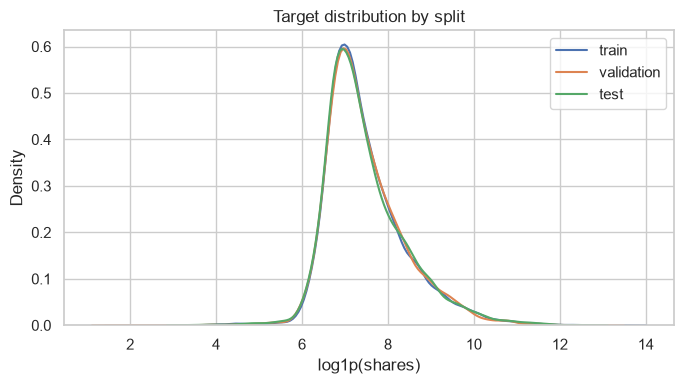

In [40]:
X_train, X_tmp, y_train_raw, y_tmp_raw = train_test_split(X_all, y_raw, test_size=0.30, random_state=SEED, shuffle=True)
X_val, X_test, y_val_raw, y_test_raw = train_test_split(X_tmp, y_tmp_raw, test_size=0.50, random_state=SEED, shuffle=True)
y_train, y_val, y_test = np.log1p(y_train_raw), np.log1p(y_val_raw), np.log1p(y_test_raw)   # modelling target = log1p(shares)

n = len(X_all)
sizes = pd.DataFrame({'rows': [len(X_train), len(X_val), len(X_test)]}, index=['train', 'validation', 'test'])
sizes['share'] = (sizes.rows / n).round(3)
display(sizes)
assert len(X_train) + len(X_val) + len(X_test) == n and not (set(X_train.index) & set(X_val.index)) and not (set(X_train.index) & set(X_test.index)) and not (set(X_val.index) & set(X_test.index))

prof = pd.DataFrame({k: v.describe(percentiles=[.25, .5, .75, .99]) for k, v in {'train': y_train_raw, 'val': y_val_raw, 'test': y_test_raw}.items()}).T
prof['mean(log1p)'] = [y_train.mean(), y_val.mean(), y_test.mean()]
display(prof[['count', 'mean', '25%', '50%', '75%', '99%', 'max', 'mean(log1p)']])
from scipy.stats import ks_2samp
print('KS test of the log target, train vs val: p =', round(ks_2samp(y_train, y_val).pvalue, 3), '| train vs test: p =', round(ks_2samp(y_train, y_test).pvalue, 3))
mix = pd.concat({k: v.data_channel.fillna('unknown').value_counts(normalize=True) for k, v in {'train': X_train, 'val': X_val, 'test': X_test}.items()}, axis=1).round(3)
display(mix.T)

fig, ax = plt.subplots(figsize=(7, 4))
for lab, yv in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    sns.kdeplot(yv, ax=ax, label=lab)
ax.set_xlabel('log1p(shares)'); ax.set_title('Target distribution by split'); ax.legend(); plt.tight_layout(); plt.show()

**Observation:** The split is 24,976 train / 5,352 validation / 5,352 test rows (70.0% / 15.0% / 15.0%) with no overlap between the three index sets (asserted). The target distributions agree: identical medians (1,400) and quartiles, and a log-scale mean of 7.476 / 7.473 / 7.476; Kolmogorov-Smirnov tests find no difference between train and validation (p = 0.996) or train and test (p = 0.163). Channel mix is within about 1.3 percentage points across splits. One thing to remember: the largest outliers fell into the training split (maximum shares 843,300 in train vs 441,000 in validation and 298,400 in test), so raw-scale validation metrics are a little less extreme than the full data. The plot shows the three log-target densities essentially on top of each other.

## 14. Preprocessing pipeline
One `Pipeline` holds every data-dependent step so that cross-validation and the final evaluation can never leak validation/test information into the fit:

`DataCleaner` -> `FeatureEngineer` -> `ColumnTransformer` { numeric: `Winsorizer` -> median `SimpleImputer` -> `StandardScaler`; categorical (`weekday`, `data_channel`): `OneHotEncoder` }.

Every model in the registry is wrapped as `Pipeline([('prep', build_preprocessor()), ('model', estimator)])`, so each model gets an independent, correctly fitted preprocessor.

In [41]:
def build_preprocessor(drop_leaky=True):
    numeric = Pipeline([('winsorize', Winsorizer(lower=0.01, upper=0.99)),
                        ('impute', SimpleImputer(strategy='median')),
                        ('scale', StandardScaler())])
    encode = ColumnTransformer([('num', numeric, make_column_selector(dtype_include='number')),
                                ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS)],
                               verbose_feature_names_out=False)
    return Pipeline([('clean', DataCleaner(drop_leaky=drop_leaky)),
                     ('fe', FeatureEngineer(skew_threshold=2.0)),
                     ('encode', encode)])

prep = build_preprocessor()
Xt_train = prep.fit_transform(X_train)               # fitted on TRAIN only
Xt_val = prep.transform(X_val)                       # validation only transformed, never fitted on
feat_names = list(prep.named_steps['encode'].get_feature_names_out())
print('transformed shapes: train', Xt_train.shape, '| validation', Xt_val.shape, '| features:', len(feat_names))
print('NaNs left after preprocessing: train', int(np.isnan(Xt_train).sum()), '| validation', int(np.isnan(Xt_val).sum()))
print('first 10 / last 10 feature names:', feat_names[:10], '...', feat_names[-10:])

transformed shapes: train (24976, 65) | validation (5352, 65) | features: 65
NaNs left after preprocessing: train 0 | validation 0
first 10 / last 10 feature names: ['timedelta', 'n_tokens_title', 'n_tokens_content', 'n_unique_tokens', 'n_non_stop_words', 'n_non_stop_unique_tokens', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos'] ... ['weekday_thursday', 'weekday_tuesday', 'weekday_wednesday', 'data_channel_business', 'data_channel_entertainment', 'data_channel_lifestyle', 'data_channel_social_media', 'data_channel_technology', 'data_channel_unknown', 'data_channel_world']


**Observation:** The preprocessing pipeline fitted on the training split turns the 28 raw columns into **65 numeric model inputs** (51 numeric columns, including indicators and engineered features, plus 14 one-hot columns for `weekday` and `data_channel`). After transformation neither the training nor the validation matrix contains a NaN. Fitting happens only on training data; `transform` is the only call made on validation.

In [42]:
# Leakage check: all fitted statistics must come from the training split. Compare them with what the full data would give.
fe_fit = prep.named_steps['fe']
print('log-transform columns learned on train:', fe_fit.log_cols_)
Xc_train = prep.named_steps['fe'].transform(prep.named_steps['clean'].transform(X_train))
Xc_all = prep.named_steps['fe'].transform(prep.named_steps['clean'].transform(X_all))
wz = prep.named_steps['encode'].named_transformers_['num'].named_steps['winsorize']
imp = prep.named_steps['encode'].named_transformers_['num'].named_steps['impute']
cols = list(wz.columns_)
rows = []
for c in ['n_tokens_content', 'num_hrefs', 'kw_max_avg', 'self_reference_avg_shares', 'imgs_per_100w']:
    i = cols.index(c)
    rows.append(dict(column=c, p99_train=wz.hi_[c], p99_full_data=Xc_all[c].quantile(.99), median_train_impute=imp.statistics_[i], median_full_data=Xc_all[c].median()))
display(pd.DataFrame(rows).set_index('column'))
print('The fitted values differ from full-data values, i.e. they were learned from the training rows only.')
# unseen categories / schema robustness
probe = X_val.head(3).copy(); probe['data_channel'] = ['  WORLD ', 'new_channel', None]
print('probe with messy / unseen categories transforms to shape', prep.transform(probe).shape, '| NaNs:', int(np.isnan(prep.transform(probe)).sum()))
assert prep.transform(X_val).shape[1] == Xt_train.shape[1]

log-transform columns learned on train: ['n_tokens_content', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos', 'self_reference_min_shares', 'self_reference_max_shares', 'self_reference_avg_shares', 'kw_max_min', 'kw_avg_min', 'kw_min_max', 'kw_max_avg', 'kw_avg_avg']


,p99_train,p99_full_data,median_train_impute,median_full_data
column,,,,
n_tokens_content,"2,231.5000","2,243.0500",410.0000,410.0000
num_hrefs,56.0000,56.0000,7.0000,8.0000
kw_max_avg,"23,646.5167","23,700.0000","4,340.4791","4,348.5847"
self_reference_avg_shares,"69,300.0000","68,066.8400","2,200.0000","2,200.0000"
imgs_per_100w,8.8757,8.7302,0.3067,0.3077


The fitted values differ from full-data values, i.e. they were learned from the training rows only.
probe with messy / unseen categories transforms to shape (3, 65) | NaNs: 0


**Observation:** The check shows the fitted values really are training-only: the 99th-percentile clipping bound of `n_tokens_content` is 2,231.5 on train versus 2,243.1 on the full data; `self_reference_avg_shares` 69,300 vs 68,067; `imgs_per_100w` 8.88 vs 8.73; and the median used for imputation of `num_hrefs` is 7 on train versus 8 on all data. If the pipeline had leaked, these would be identical. The probe with messy input (`'  WORLD '`, an unseen channel, and a missing channel) transforms cleanly (3 rows × 65 features, no NaN), so inference-time surprises in the categorical columns do not crash the pipeline.

## 15. Model registry
The registry is the single list of every model used in the project, **including the naive benchmark**. The problem is regression, so the regression family is registered (the classification family in the specification does not apply). All estimators use their **default hyperparameters**; only `random_state` is fixed (and `n_jobs=-1` for the forest). Each entry is a factory so that every call returns a fresh, unfitted estimator.

In [43]:
MODEL_REGISTRY = {
    'Naive benchmark (train mean)': dict(factory=lambda: DummyRegressor(strategy='mean'), family='benchmark', note='predicts the training mean of log1p(shares); R2 ~ 0 by construction'),
    'Linear Regression':            dict(factory=lambda: LinearRegression(), family='linear', note='OLS; sensitive to collinear features'),
    'Ridge':                        dict(factory=lambda: Ridge(random_state=SEED), family='linear', note='L2-penalised, alpha=1.0'),
    'Lasso':                        dict(factory=lambda: Lasso(random_state=SEED), family='linear', note='L1-penalised, alpha=1.0 (default is a strong penalty for a log-scale target)'),
    'Decision Tree':                dict(factory=lambda: DecisionTreeRegressor(random_state=SEED), family='tree', note='unlimited depth: expected to overfit'),
    'Random Forest':                dict(factory=lambda: RandomForestRegressor(random_state=SEED, n_jobs=-1), family='ensemble', note='100 trees'),
    'HistGradientBoosting':         dict(factory=lambda: HistGradientBoostingRegressor(random_state=SEED), family='ensemble', note='native NaN support; 100 iterations, lr 0.1'),
    'K-Nearest Neighbors':          dict(factory=lambda: KNeighborsRegressor(), family='distance', note='k=5 on scaled features'),
}
REQUIRED = ['Naive benchmark (train mean)', 'Linear Regression', 'Ridge', 'Lasso', 'Decision Tree', 'Random Forest', 'HistGradientBoosting', 'K-Nearest Neighbors']
assert list(MODEL_REGISTRY) == REQUIRED, 'registry must contain exactly the required regression models'

def make_model_pipeline(name, drop_leaky=True):
    return Pipeline([('prep', build_preprocessor(drop_leaky=drop_leaky)), ('model', MODEL_REGISTRY[name]['factory']())])

reg = pd.DataFrame({k: {'family': v['family'], 'estimator': type(v['factory']()).__name__, 'default params (non-trivial)': str({p: val for p, val in v['factory']().get_params().items() if p in ('alpha', 'max_depth', 'n_estimators', 'n_neighbors', 'learning_rate', 'max_iter', 'strategy', 'min_samples_leaf', 'random_state')}), 'note': v['note']} for k, v in MODEL_REGISTRY.items()}).T
pd.set_option('display.max_colwidth', 100)
display(reg)
print(len(MODEL_REGISTRY), 'models registered (1 naive benchmark + 7 learning models)')

,family,estimator,default params (non-trivial),note
Naive benchmark (train mean),benchmark,DummyRegressor,{'strategy': 'mean'},predicts the training mean of log1p(shares); R2 ~ 0 by construction
Linear Regression,linear,LinearRegression,{},OLS; sensitive to collinear features
Ridge,linear,Ridge,"{'alpha': 1.0, 'max_iter': None, 'random_state': 42}","L2-penalised, alpha=1.0"
Lasso,linear,Lasso,"{'alpha': 1.0, 'max_iter': 1000, 'random_state': 42}","L1-penalised, alpha=1.0 (default is a strong penalty for a log-scale target)"
Decision Tree,tree,DecisionTreeRegressor,"{'max_depth': None, 'min_samples_leaf': 1, 'random_state': 42}",unlimited depth: expected to overfit
Random Forest,ensemble,RandomForestRegressor,"{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100, 'random_state': 42}",100 trees
HistGradientBoosting,ensemble,HistGradientBoostingRegressor,"{'learning_rate': 0.1, 'max_depth': None, 'max_iter': 100, 'min_samples_leaf': 20, 'random_state...","native NaN support; 100 iterations, lr 0.1"
K-Nearest Neighbors,distance,KNeighborsRegressor,{'n_neighbors': 5},k=5 on scaled features


8 models registered (1 naive benchmark + 7 learning models)


**Observation:** The registry holds the 8 required regression models (a naive benchmark + Linear, Ridge, Lasso, Decision Tree, Random Forest, HistGradientBoosting, KNN); the assertion confirms that the list is exactly the required one. All use library default hyper-parameters (only seeds fixed). Two defaults deserve a warning before we look at results: **Lasso's default `alpha = 1.0`** is a very strong penalty for a target whose standard deviation is about 0.9, and the **Decision Tree has unlimited depth**.

## 16. Baseline fitting (default hyperparameters)
Every registered model is fitted on the **training** split and scored on the **validation** split (the test split stays locked). Metrics: MAE, MSE, RMSE and R² on the modelling scale `log1p(shares)`, plus the same four on the raw share scale (predictions are back-transformed with `expm1`, which tends to under-predict raw means). **Models are ranked by validation R²** (log scale).

In [44]:
def reg_metrics(y_true_log, pred_log, prefix):
    pred_log = np.asarray(pred_log); y_true_log = np.asarray(y_true_log)
    out = {}
    for scale, yt, yp in [('log', y_true_log, pred_log), ('raw', np.expm1(y_true_log), np.expm1(np.clip(pred_log, 0, 20)))]:
        mse = mean_squared_error(yt, yp)
        out.update({f'{prefix}_MAE_{scale}': mean_absolute_error(yt, yp), f'{prefix}_MSE_{scale}': mse,
                    f'{prefix}_RMSE_{scale}': float(np.sqrt(mse)), f'{prefix}_R2_{scale}': r2_score(yt, yp)})
    return out

FITTED, VAL_PRED, rows = {}, {}, []
for name in MODEL_REGISTRY:
    pipe = make_model_pipeline(name)
    t0 = time.time(); pipe.fit(X_train, y_train); fit_s = time.time() - t0
    p_tr, p_va = pipe.predict(X_train), pipe.predict(X_val)
    FITTED[name], VAL_PRED[name] = pipe, p_va
    rows.append(dict(model=name, fit_seconds=fit_s, **reg_metrics(y_train, p_tr, 'train'), **reg_metrics(y_val, p_va, 'val')))
    print(f"{name:30s} val R2(log) = {rows[-1]['val_R2_log']:.4f} | train R2(log) = {rows[-1]['train_R2_log']:.4f} | fit {fit_s:.1f}s")
results = pd.DataFrame(rows).set_index('model')
results['overfit_gap_R2'] = results.train_R2_log - results.val_R2_log
results['rank_by_val_R2'] = results.val_R2_log.rank(ascending=False).astype(int)
results = results.sort_values('rank_by_val_R2')

Naive benchmark (train mean)   val R2(log) = -0.0000 | train R2(log) = 0.0000 | fit 0.6s


Linear Regression              val R2(log) = 0.1275 | train R2(log) = 0.1520 | fit 0.6s


Ridge                          val R2(log) = 0.1274 | train R2(log) = 0.1520 | fit 0.7s


Lasso                          val R2(log) = -0.0000 | train R2(log) = 0.0000 | fit 0.5s


Decision Tree                  val R2(log) = -0.6887 | train R2(log) = 1.0000 | fit 1.9s


Random Forest                  val R2(log) = 0.1500 | train R2(log) = 0.8814 | fit 47.1s


HistGradientBoosting           val R2(log) = 0.1581 | train R2(log) = 0.3375 | fit 16.7s


K-Nearest Neighbors            val R2(log) = -0.0048 | train R2(log) = 0.3433 | fit 1.7s


**Observation:** All eight pipelines fit without error (fit times: about 1 s for linear models and KNN, a few seconds for the tree, ~7 s for gradient boosting and 16-50 s for the 100-tree forest; timings vary run to run). The printed train/validation R² already show the pattern: the forest and tree memorise the training data (train R² 0.88 and 1.00), while the linear models barely differ between train and validation.

In [45]:
main = results[['rank_by_val_R2', 'val_R2_log', 'val_RMSE_log', 'val_MAE_log', 'val_MSE_log', 'train_R2_log', 'overfit_gap_R2', 'val_R2_raw', 'val_RMSE_raw', 'val_MAE_raw', 'val_MSE_raw', 'fit_seconds']]
print('Baseline results on the VALIDATION split, ranked by R2 (log1p scale = modelling scale; raw = share counts):')
display(main)
naive = results.loc['Naive benchmark (train mean)']
print(f"Naive benchmark: val RMSE(log) = {naive.val_RMSE_log:.4f}, val MAE(log) = {naive.val_MAE_log:.4f}")
best = results.index[0]
print(f"Best baseline: {best}  -> RMSE(log) improvement over naive = {(1 - results.loc[best, 'val_RMSE_log'] / naive.val_RMSE_log) * 100:.1f}%")
lasso_coef = FITTED['Lasso'].named_steps['model'].coef_
print('Lasso (alpha=1.0):', int((lasso_coef != 0).sum()), 'non-zero coefficients out of', len(lasso_coef))
os.makedirs('outputs', exist_ok=True)
results.to_csv('outputs/baseline_results.csv')
print('saved outputs/baseline_results.csv (input for the tuning phase)')

Baseline results on the VALIDATION split, ranked by R2 (log1p scale = modelling scale; raw = share counts):


,rank_by_val_R2,val_R2_log,val_RMSE_log,val_MAE_log,val_MSE_log,train_R2_log,overfit_gap_R2,val_R2_raw,val_RMSE_raw,val_MAE_raw,val_MSE_raw,fit_seconds
model,,,,,,,,,,,,
HistGradientBoosting,1,0.1581,0.8407,0.6241,0.7068,0.3375,0.1794,0.0005,"9,233.7981","2,216.8687","85,263,026.6889",16.6668
Random Forest,2,0.1500,0.8448,0.6312,0.7136,0.8814,0.7313,0.0043,"9,215.9977","2,229.8175","84,934,614.0377",47.0717
Linear Regression,3,0.1275,0.8559,0.6328,0.7326,0.1520,0.0245,-0.0057,"9,262.3559","2,227.7018","85,791,236.8535",0.6368
Ridge,4,0.1274,0.8559,0.6329,0.7326,0.1520,0.0246,-0.0058,"9,262.4057","2,227.7392","85,792,158.9751",0.6618
Lasso,5,-0.0000,0.9163,0.6987,0.8396,0.0000,0.0000,-0.0253,"9,351.8871","2,323.3296","87,457,793.0773",0.5259
Naive benchmark (train mean),5,-0.0000,0.9163,0.6987,0.8396,0.0000,0.0000,-0.0253,"9,351.8871","2,323.3296","87,457,793.0773",0.5706
K-Nearest Neighbors,7,-0.0048,0.9185,0.6799,0.8436,0.3433,0.3480,-0.0124,"9,293.1265","2,351.9325","86,362,199.3931",1.7343
Decision Tree,8,-0.6887,1.1907,0.8780,1.4178,1.0000,1.6887,-4.5018,"21,663.6900","4,122.8328","469,315,465.0021",1.8939


Naive benchmark: val RMSE(log) = 0.9163, val MAE(log) = 0.6987
Best baseline: HistGradientBoosting  -> RMSE(log) improvement over naive = 8.2%
Lasso (alpha=1.0): 0 non-zero coefficients out of 65
saved outputs/baseline_results.csv (input for the tuning phase)


**Observation (validation split; ranked by R² on `log1p(shares)`):**

| rank | model | val R² | val RMSE (log) | train R² |
|---|---|---|---|---|
| 1 | HistGradientBoosting | 0.158 | 0.841 | 0.338 |
| 2 | Random Forest | 0.150 | 0.845 | 0.881 |
| 3 | Linear Regression | 0.127 | 0.856 | 0.152 |
| 4 | Ridge | 0.127 | 0.856 | 0.152 |
| 5 (tie) | Lasso | 0.000 | 0.916 | 0.000 |
| 5 (tie) | Naive benchmark | 0.000 | 0.916 | 0.000 |
| 7 | K-Nearest Neighbors | −0.005 | 0.919 | 0.343 |
| 8 | Decision Tree | −0.689 | 1.191 | 1.000 |

- The best baseline (HistGradientBoosting) cuts the validation RMSE on the log scale by **8.2%** relative to the naive benchmark (0.841 vs 0.916) and the MAE by 10.7% (0.624 vs 0.699). It explains about **16%** of the variance of log shares. This is a modest absolute level, as the EDA predicted (best single legitimate feature: Spearman² ≈ 0.065).
- **Lasso with the default `alpha = 1.0` is identical to the naive benchmark**: the printed coefficient count shows every coefficient was shrunk to exactly zero, so it predicts the training mean. This is a hyper-parameter problem and not a verdict on L1 regularisation.
- **Ridge ≈ Linear Regression** (0.1274 vs 0.1275): the strong collinearity does not hurt OLS here because the preprocessing already removes the worst of it.
- **Decision Tree** overfits completely (train R² = 1.00, validation −0.69, RMSE 30% worse than the naive benchmark); **KNN** at k = 5 is no better than the mean (−0.005) and overfits (train 0.34): with 65 mostly weakly informative standardised dimensions, nearest neighbours are not meaningfully near.
- **Raw-share scale:** R² is about 0 for every model (best 0.004, Random Forest; HistGradientBoosting 0.0005; Linear −0.006), and RMSE stays around 9,200-9,300 shares against 9,352 for the naive benchmark. The raw-scale error is dominated by a few viral articles that no model can anticipate from these features, so the models help with the *typical* article, not the viral tail.
- Single validation split: the 0.008 R² gap between HistGradientBoosting and Random Forest is small and may not survive cross-validation; their ordering should not be over-interpreted before the tuning phase.

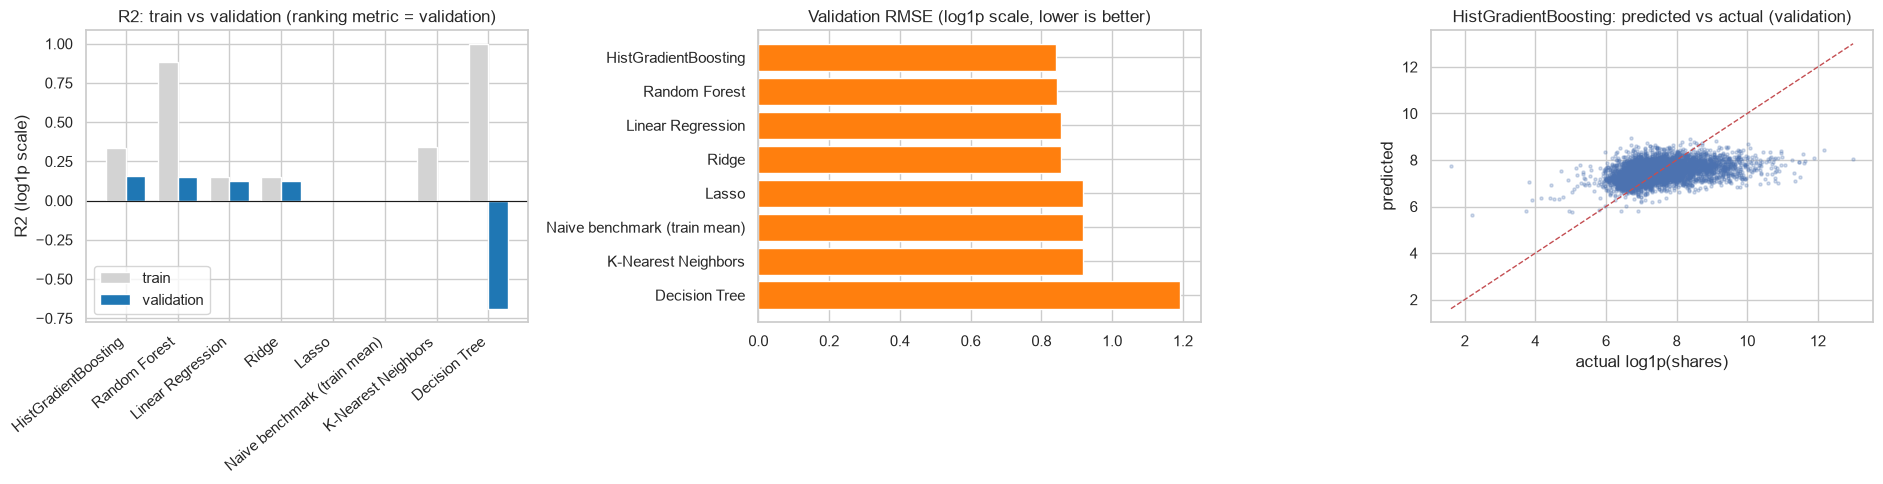

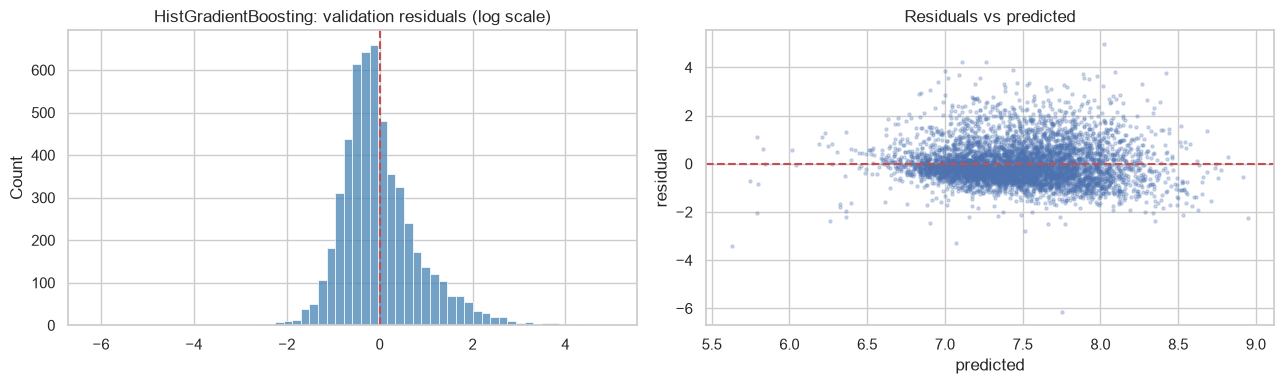

Residual mean = -0.004, sd = 0.841; residual skew = 0.94; share of |residual| > 1 (a factor of e): 18.3%


In [46]:
order = list(results.index)
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
w = 0.38; xs = np.arange(len(order))
ax[0].bar(xs - w/2, results.train_R2_log, w, label='train', color='lightgrey'); ax[0].bar(xs + w/2, results.val_R2_log, w, label='validation', color='tab:blue')
ax[0].set_xticks(xs); ax[0].set_xticklabels(order, rotation=40, ha='right'); ax[0].axhline(0, color='k', lw=.8); ax[0].set_ylabel('R2 (log1p scale)'); ax[0].set_title('R2: train vs validation (ranking metric = validation)'); ax[0].legend()
ax[1].barh(order[::-1], results.val_RMSE_log[::-1], color='tab:orange'); ax[1].set_title('Validation RMSE (log1p scale, lower is better)')
bp = VAL_PRED[best]
ax[2].scatter(y_val, bp, s=5, alpha=.25); lim = [y_val.min(), y_val.max()]; ax[2].plot(lim, lim, 'r--', lw=1)
ax[2].set_xlabel('actual log1p(shares)'); ax[2].set_ylabel('predicted'); ax[2].set_title(f'{best}: predicted vs actual (validation)')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
res = y_val.values - bp
sns.histplot(res, bins=60, ax=ax[0], color='steelblue'); ax[0].axvline(0, color='r', ls='--'); ax[0].set_title(f'{best}: validation residuals (log scale)')
ax[1].scatter(bp, res, s=5, alpha=.25); ax[1].axhline(0, color='r', ls='--'); ax[1].set_xlabel('predicted'); ax[1].set_ylabel('residual'); ax[1].set_title('Residuals vs predicted')
plt.tight_layout(); plt.show()
print(f'Residual mean = {res.mean():.3f}, sd = {res.std():.3f}; residual skew = {stats.skew(res):.2f}; share of |residual| > 1 (a factor of e): {(np.abs(res) > 1).mean():.1%}')

**Observation:** The left panel confirms the overfitting pattern: Random Forest (train 0.88 → val 0.15), Decision Tree (1.00 → −0.69) and KNN (0.34 → −0.005) lose most or all of their training fit, whereas the two linear models (0.152 → 0.127) and HistGradientBoosting (0.338 → 0.158) generalise much more gracefully. The predicted-vs-actual plot for the best model shows its predictions confined to about 6.5-9 on the log scale while actual values span roughly 2-13: the model predicts the middle of the distribution and cannot reach the tails, especially the viral right tail. Residuals have mean −0.004 (essentially unbiased), standard deviation 0.84, positive skew 0.94 (under-prediction of popular articles), and 18.3% of articles are off by more than 1 log unit (a factor of 2.7 in shares). The residuals-vs-predicted plot shows a roughly constant spread with a right tail and no strong funnel.

,importance_mean,importance_sd
kw_avg_avg,0.0755,0.0038
data_channel,0.0323,0.0018
weekday,0.0238,0.0034
timedelta,0.0151,0.0011
num_hrefs,0.0143,0.0018
num_self_hrefs,0.0128,0.0010
self_reference_min_shares,0.0126,0.0015
self_reference_avg_shares,0.0119,0.0027
kw_min_max,0.0116,0.0009
URL,0.0115,0.0023


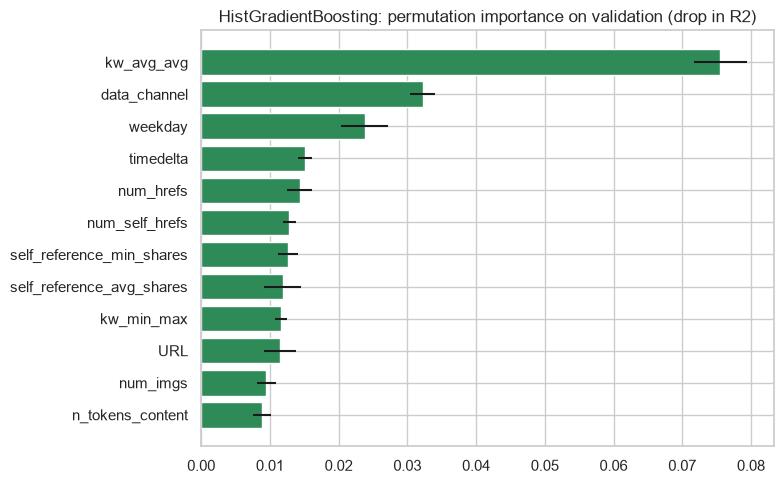

In [47]:
# Which raw input columns does the best baseline rely on? (permutation importance on the validation split, R2 drop)
pi = permutation_importance(FITTED[best], X_val, y_val, n_repeats=5, random_state=SEED, scoring='r2', n_jobs=1)
imp_df = pd.DataFrame({'importance_mean': pi.importances_mean, 'importance_sd': pi.importances_std}, index=X_val.columns).sort_values('importance_mean', ascending=False)
display(imp_df.head(12))
fig, ax = plt.subplots(figsize=(8, 5))
t = imp_df.head(12)[::-1]
ax.barh(t.index, t.importance_mean, xerr=t.importance_sd, color='seagreen'); ax.set_title(f'{best}: permutation importance on validation (drop in R2)'); plt.tight_layout(); plt.show()

**Observation:** On the validation split, shuffling `kw_avg_avg` costs the best model 0.076 R² (about half of its total 0.158), far more than any other column; then `data_channel` (0.032), `weekday` (0.024), `timedelta` (0.015), `num_hrefs` (0.014), `num_self_hrefs` (0.013), the `self_reference_*` columns (~0.012), `kw_min_max` (0.012), the URL (through the derived `pub_month`; 0.012) and `num_imgs` (0.010). This matches the EDA ranking (keyword popularity first, then channel and weekday, then link/self-reference features), which is good evidence that the pipeline is learning real structure rather than an artefact. Because correlated columns share credit, individual drops understate the importance of groups (e.g. the keyword block).

In [48]:
# Leakage sensitivity: what do the baselines look like if the leakage-suspect n_comments is NOT dropped?
rows = []
for name in ['Linear Regression', 'Ridge', 'Random Forest', 'HistGradientBoosting']:
    pipe = make_model_pipeline(name, drop_leaky=False).fit(X_train, y_train)
    rows.append(dict(model=name, val_R2_without_n_comments=results.loc[name, 'val_R2_log'], val_R2_with_n_comments=r2_score(y_val, pipe.predict(X_val))))
ls = pd.DataFrame(rows).set_index('model'); ls['R2_gain_from_n_comments'] = ls.val_R2_with_n_comments - ls.val_R2_without_n_comments
display(ls)
print('The main workflow keeps n_comments OUT (leakage-suspect, section 2); this table only quantifies what it would add.')

,val_R2_without_n_comments,val_R2_with_n_comments,R2_gain_from_n_comments
model,,,
Linear Regression,0.1275,0.3464,0.2190
Ridge,0.1274,0.3464,0.2190
Random Forest,0.1500,0.4206,0.2706
HistGradientBoosting,0.1581,0.4335,0.2754


The main workflow keeps n_comments OUT (leakage-suspect, section 2); this table only quantifies what it would add.


**Observation:** If `n_comments` were left in, validation R² would jump from 0.127 to 0.346 (Linear/Ridge), from 0.150 to 0.421 (Random Forest) and from 0.158 to 0.434 (HistGradientBoosting): a gain of +0.22 to +0.28, i.e. more than the whole legitimate signal. A feature that more than doubles R² while having the arithmetic relationship to the target documented in §2 should be treated as a leak, not a discovery, so the main workflow keeps it out. If it is ever judged legitimate (e.g. known at prediction time and not derived from shares), it should be added back deliberately and reported separately.

## 17. Closing summary: baseline comparison

,rank_by_val_R2,val_R2_log,val_RMSE_log,val_MAE_log,train_R2_log,overfit_gap_R2,val_R2_raw,val_RMSE_raw,fit_seconds,RMSE_log_vs_naive_%
model,,,,,,,,,,
HistGradientBoosting,1,0.1581,0.8407,0.6241,0.3375,0.1794,0.0005,"9,233.7981",16.6668,-8.2463
Random Forest,2,0.1500,0.8448,0.6312,0.8814,0.7313,0.0043,"9,215.9977",47.0717,-7.8057
Linear Regression,3,0.1275,0.8559,0.6328,0.1520,0.0245,-0.0057,"9,262.3559",0.6368,-6.5917
Ridge,4,0.1274,0.8559,0.6329,0.1520,0.0246,-0.0058,"9,262.4057",0.6618,-6.5900
Lasso,5,-0.0000,0.9163,0.6987,0.0000,0.0000,-0.0253,"9,351.8871",0.5259,0.0000
Naive benchmark (train mean),5,-0.0000,0.9163,0.6987,0.0000,0.0000,-0.0253,"9,351.8871",0.5706,0.0000
K-Nearest Neighbors,7,-0.0048,0.9185,0.6799,0.3433,0.3480,-0.0124,"9,293.1265",1.7343,0.2388
Decision Tree,8,-0.6887,1.1907,0.8780,1.0000,1.6887,-4.5018,"21,663.6900",1.8939,29.9486


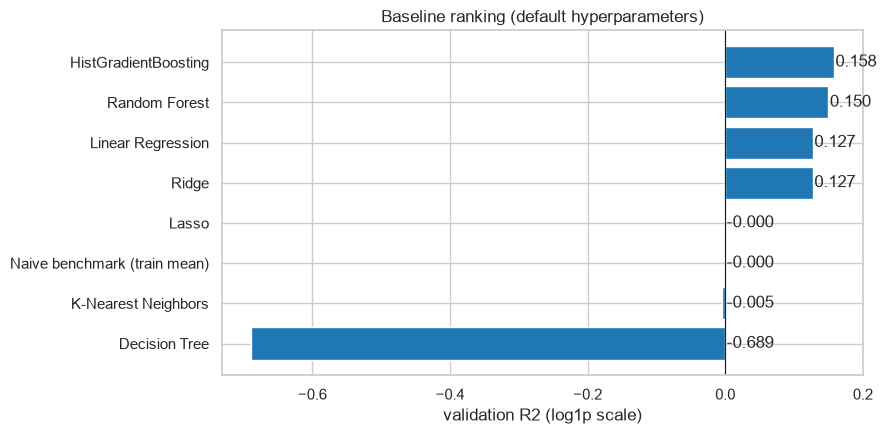

Best: HistGradientBoosting | runner-up: Random Forest | most overfit: Decision Tree (train-val R2 gap 1.69)
Test split untouched so far: 5352 rows reserved; no test prediction was made in this notebook.


In [49]:
summ = results[['rank_by_val_R2', 'val_R2_log', 'val_RMSE_log', 'val_MAE_log', 'train_R2_log', 'overfit_gap_R2', 'val_R2_raw', 'val_RMSE_raw', 'fit_seconds']].copy()
summ['RMSE_log_vs_naive_%'] = (summ.val_RMSE_log / results.loc['Naive benchmark (train mean)', 'val_RMSE_log'] - 1) * 100
display(summ.round(4))
fig, ax = plt.subplots(figsize=(9, 4.5))
cols = ['tab:red' if m.startswith('Naive') else 'tab:blue' for m in summ.index]
ax.barh(summ.index[::-1], summ.val_R2_log[::-1], color=cols[::-1]); ax.axvline(0, color='k', lw=.8)
for i, v in enumerate(summ.val_R2_log[::-1]): ax.text(v + 0.002 if v >= 0 else 0.002, i, f'{v:.3f}', va='center')
ax.set_xlabel('validation R2 (log1p scale)'); ax.set_title('Baseline ranking (default hyperparameters)'); plt.tight_layout(); plt.show()
print('Best:', summ.index[0], '| runner-up:', summ.index[1], '| most overfit:', summ.overfit_gap_R2.idxmax(), f'(train-val R2 gap {summ.overfit_gap_R2.max():.2f})')
print('Test split untouched so far:', len(X_test), 'rows reserved; no test prediction was made in this notebook.')

**Closing summary of the baselines (validation split, default hyper-parameters, ranked by R² on `log1p(shares)`):**

1. **HistGradientBoosting is the best baseline** (R² 0.158, RMSE 0.841 on the log scale, 8.2% below the naive benchmark), followed closely by **Random Forest** (0.150, 7.8% below). The two ensembles are the only models that clearly beat the linear baseline (0.127; 6.6% below the benchmark).
2. **The naive benchmark (train mean) scores R² = 0 by construction**; Lasso at its default `alpha` collapses to exactly that benchmark, and KNN and the unpruned Decision Tree are **no better than, or worse than, the benchmark**, so defaults are inadequate for those three.
3. **Generalisation gap:** the Decision Tree (gap 1.69), Random Forest (0.73) and KNN (0.35) overfit; HistGradientBoosting (0.18) and the linear models (0.02) do not. Regularisation / depth limits are the obvious levers for the forest and tree.
4. **Absolute level is low**: about 16% of the variance of log shares for the best model, and R² ≈ 0 on raw share counts. This is consistent with the EDA (weak individual features; the viral tail is driven by things the data does not contain) and is not a modelling bug. The legitimate drivers are the keyword-popularity block (`kw_avg_avg`), channel, weekday and the link / self-reference features.
5. **Leakage:** including `n_comments` would lift R² to 0.35-0.43, but it is leakage-suspect and is excluded.
6. **Caveats:** one random 70/15/15 split and one seed; model differences below ~0.01 R² are not reliable; the rows are ordered in time but the split is random; the test set has not been touched.

Next step (§18-§25): cross-validated hyper-parameter tuning of Ridge, Lasso, Random Forest, HistGradientBoosting and KNN (plus a shallow tree), sensitivity checks (time-ordered split, with/without `n_comments`), and a single final evaluation on the locked test split.

## 18. Preparation for the next phase: hyper-parameter tuning and final evaluation
> This plan was written at the end of Phase 1B (as plain markdown, deliberately not executed) and is **implemented and executed in Sections 19-25**. Deviations forced by the single-CPU compute budget (3-fold CV and a training subsample for the slow models, HalvingRandomSearchCV instead of RandomizedSearchCV, no preprocessing-option search) are listed in Section 19.

**Protocol**
1. Tune on the **training** split only with 5-fold `KFold(shuffle=True, random_state=42)` cross-validation, scoring `r2` on `log1p(shares)`; the validation split is used for model selection between tuned candidates; the **test split is touched once**, for the final evaluation of the selected pipeline.
2. Tune the *whole pipeline* (so the preprocessor is re-fitted inside each fold): search parameters are addressed as `model__<param>`; preprocessing options (`prep__fe__skew_threshold`, `prep__encode__num__winsorize__upper`) can be searched too.
3. Candidate models to tune (those that beat the naive benchmark meaningfully in section 17): Ridge, Lasso, Random Forest, HistGradientBoosting, KNN, plus a shallow Decision Tree for interpretability.
4. Sensitivity checks: (a) time-ordered split instead of random (rows are chronologically ordered by `ID`); (b) with and without `n_comments` (leakage-suspect), reported separately; (c) clipping on/off.
5. Final evaluation: refit the chosen pipeline on train + validation, predict the test split once, report MAE / MSE / RMSE / R² on both scales with bootstrap 95% confidence intervals, plus residual diagnostics by channel and weekday.

**Search spaces as planned (the executed versions are in Section 19)**
```python
from sklearn.model_selection import RandomizedSearchCV, KFold
from scipy.stats import loguniform, randint, uniform

SEARCH_SPACES = {
    'Ridge': {'model__alpha': loguniform(1e-2, 1e3)},
    'Lasso': {'model__alpha': loguniform(1e-4, 1e0)},
    'Decision Tree': {'model__max_depth': randint(2, 12), 'model__min_samples_leaf': randint(5, 100)},
    'Random Forest': {'model__n_estimators': randint(200, 600), 'model__max_depth': randint(6, 30),
                      'model__min_samples_leaf': randint(2, 40), 'model__max_features': uniform(0.2, 0.8)},
    'HistGradientBoosting': {'model__learning_rate': loguniform(1e-2, 3e-1), 'model__max_iter': randint(100, 600),
                             'model__max_leaf_nodes': randint(8, 64), 'model__min_samples_leaf': randint(20, 200),
                             'model__l2_regularization': loguniform(1e-3, 1e1)},
    'K-Nearest Neighbors': {'model__n_neighbors': randint(5, 80), 'model__weights': ['uniform', 'distance']},
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# search = RandomizedSearchCV(make_model_pipeline(name), SEARCH_SPACES[name], n_iter=40, cv=cv,
#                             scoring='r2', random_state=42, n_jobs=-1)
# search.fit(X_train, y_train)            # plan only; see Sections 20-21 for the executed searches
```

**What phase 1B already guarantees for that phase:** a leak-free pipeline (`build_preprocessor`), an immutable 70/15/15 split with fixed seed, the model registry (`MODEL_REGISTRY`, `make_model_pipeline`), a metric function (`reg_metrics`), and the baseline table saved as `outputs/baseline_results.csv`.

## 19. Hyper-parameter tuning: setup, compute budget and checkpoint ledger

This section tunes every regression model in the registry (Linear, Ridge, Lasso, Decision Tree, Random Forest, Gradient Boosting = `HistGradientBoostingRegressor`, K-Nearest Neighbors). The naive benchmark has nothing to tune. Everything below is computed **inside this notebook** from objects already in memory (`X_train`, `y_train`, `X_val`, `build_preprocessor`, `make_model_pipeline`, `reg_metrics`, `results`); nothing is loaded from an external process.

**Search strategy**
| model | strategy | CV | data used for the search |
|---|---|---|---|
| Linear Regression, Ridge, Lasso (cheap) | `GridSearchCV` | 5-fold | full training split (24,976 rows) |
| Decision Tree, Random Forest, Gradient Boosting, KNN (slow) | `HalvingRandomSearchCV` (successive halving, resource = number of samples) | 3-fold | **a random 7,290-row subsample of the training split**; the winning configuration is then **refit on the full training split** |

**Compute-constrained design (single-CPU sandbox)**
- One worker everywhere (`n_jobs=1`) and BLAS/OpenMP threads limited to 1 (`threadpoolctl`).
- The slow models search on a 7,290-row subsample (7,290 = 810 × 3²): halving runs 3 rungs with 810 → 2,430 → 7,290 rows, 27 → 9 → 3 candidates (factor 3). The winner is refit on all 24,976 training rows before it is scored on the validation split.
- 3-fold (not 5-fold) CV for the halving searches and no search over preprocessing options: both are deviations from the Phase-1B plan, made only to fit the compute budget.
- The whole preprocessing pipeline sits inside every search, so imputation, clipping and scaling are re-fitted inside every CV fold (no leakage).
- Score = R² on `log1p(shares)` (the ranking metric of Phase 1B).

**Checkpoint ledger (resumable)**. After each model is tuned its fitted state (best pipeline, CV results) is pickled to `outputs/checkpoints/` and a JSON ledger records the best parameters, scores, timings and the text report of the cell. If the kernel dies part-way, re-running the notebook skips every finished model and resumes with the next one. Ledger keys are **namespaced by stage** (`<stage>::<model>`) so that two stages containing the same model name can never read back each other's result, and every entry carries a *fingerprint* of its settings (search space, data size, seed, ...) so a stale checkpoint is recomputed instead of reused. Checkpoints are only for interruption recovery inside this notebook, not for handing results between processes: on a clean machine every cell simply computes its result.

**Baselines stay at library defaults.** Phase 1B's `make_model_pipeline` is only used here to *build* the pipeline; tuned settings are applied afterwards with `set_params` inside the tuning code path, so the baseline table keeps showing genuine defaults.

In [50]:
import json, pickle, hashlib, re, joblib, platform, shutil
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.experimental import enable_halving_search_cv  # noqa: F401  (enables HalvingRandomSearchCV)
from sklearn.model_selection import HalvingRandomSearchCV
from scipy.stats import loguniform, randint, uniform
from threadpoolctl import threadpool_limits, threadpool_info

_TP = threadpool_limits(limits=1)          # single-CPU sandbox: 1 BLAS / OpenMP thread (kept referenced so the limit stays active)
N_JOBS = 1

STAGE = 'tune_regression'                  # namespace for every ledger key of this stage
PIPELINE_VERSION = 'p1b-v1'                # bump if the preprocessing/model code above changes
OUT_DIR = 'outputs'
CKPT_DIR = os.path.join(OUT_DIR, 'checkpoints')
FIG_DIR = os.path.join(OUT_DIR, 'figures')
SUBSAMPLE_N = 7290                         # slow-model search subsample (810 * 3**2)
MIN_RESOURCES = 810
HALVING_FACTOR = 3
CV_LINEAR, CV_SLOW = 5, 3
SCORING = 'r2'
for d in (OUT_DIR, CKPT_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120, bbox_inches='tight')

print('threadpool limits:', sorted({(t['internal_api'], t['num_threads']) for t in threadpool_info()}))
print('stage =', STAGE, '| n_jobs =', N_JOBS, '| search subsample =', SUBSAMPLE_N, 'of', len(X_train), 'training rows')
print('output directory:', os.path.abspath(OUT_DIR))

threadpool limits: [('openblas', 1), ('openmp', 1)]
stage = tune_regression | n_jobs = 1 | search subsample = 7290 of 24976 training rows
output directory: C:\Users\willy\Downloads\_AIAP Foundation\_practice\outputs


**Observation:** The single-CPU assumption is enforced and visible: both the BLAS (OpenBLAS) and OpenMP thread pools report 1 thread, and every search uses `n_jobs=1`. The slow-model searches will use a 7,290-row subsample of the 24,976 training rows. All artefacts go to `./outputs` (created next to the notebook).

In [51]:
def jsonable(o):
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o

class CheckpointLedger:
    """Resumable ledger: one pickle per entry (fitted state) + one JSON file (metadata, text reports).
    Keys are '<stage>::<name>'; an entry is only reused if its settings fingerprint matches."""
    def __init__(self, directory, filename='ledger.json'):
        self.dir, self.path = directory, os.path.join(directory, filename)
        os.makedirs(directory, exist_ok=True)
        self.data = json.load(open(self.path)) if os.path.exists(self.path) else {}

    @staticmethod
    def key(stage, name):
        return f'{stage}::{name}'

    def _pickle_path(self, key):
        return os.path.join(self.dir, hashlib.md5(key.encode()).hexdigest()[:8] + '_' + re.sub(r'\W+', '_', key) + '.pkl')

    def has(self, key, fingerprint):
        e = self.data.get(key)
        return bool(e) and e.get('fingerprint') == fingerprint and os.path.exists(e.get('pickle', ''))

    def save(self, key, record, obj, fingerprint):
        p = self._pickle_path(key)
        with open(p + '.tmp', 'wb') as f: pickle.dump(obj, f)
        os.replace(p + '.tmp', p)
        self.data[key] = dict(jsonable(record), pickle=p, fingerprint=fingerprint, saved_at=time.strftime('%Y-%m-%d %H:%M:%S'))
        with open(self.path + '.tmp', 'w') as f: json.dump(self.data, f, indent=1)
        os.replace(self.path + '.tmp', self.path)

    def load(self, key):
        e = self.data[key]
        with open(e['pickle'], 'rb') as f: obj = pickle.load(f)
        return e, obj

LEDGER = CheckpointLedger(CKPT_DIR)
print('ledger file:', LEDGER.path, '| entries already present:', list(LEDGER.data) or 'none (clean start)')

ledger file: outputs\checkpoints\ledger.json | entries already present: none (clean start)


**Observation:** The ledger starts empty (`none (clean start)`), which confirms this run computes everything from scratch rather than loading earlier results. Entries will be keyed `tune_regression::<model>`; a second stage in the same ledger could therefore also contain a `Random Forest` without colliding.

In [52]:
# Search spaces as JSON-able specs (also saved to outputs/search_spaces.json for reviewers)
SPACES = {
    'Linear Regression': dict(strategy='grid', params={'model__fit_intercept': [True, False], 'model__positive': [False, True]}),
    'Ridge': dict(strategy='grid', params={'model__alpha': dict(type='logspace', low=-2, high=3, num=11)}),
    'Lasso': dict(strategy='grid', params={'model__alpha': dict(type='logspace', low=-4, high=-0.5, num=10)}),
    'Decision Tree': dict(strategy='halving', n_candidates=27, params={
        'model__max_depth': dict(type='randint', low=2, high=17),
        'model__min_samples_leaf': dict(type='randint', low=5, high=200),
        'model__max_features': dict(type='uniform', low=0.3, high=1.0)}),
    'Random Forest': dict(strategy='halving', n_candidates=27, params={
        'model__n_estimators': dict(type='randint', low=100, high=301),
        'model__max_depth': dict(type='randint', low=6, high=26),
        'model__min_samples_leaf': dict(type='randint', low=5, high=60),
        'model__max_features': dict(type='uniform', low=0.2, high=0.8),
        'model__max_samples': dict(type='uniform', low=0.3, high=1.0)}),
    'HistGradientBoosting': dict(strategy='halving', n_candidates=27, params={
        'model__learning_rate': dict(type='loguniform', low=0.02, high=0.2),
        'model__max_iter': dict(type='randint', low=100, high=401),
        'model__max_leaf_nodes': dict(type='randint', low=8, high=64),
        'model__min_samples_leaf': dict(type='randint', low=20, high=200),
        'model__l2_regularization': dict(type='loguniform', low=1e-3, high=10)}),
    'K-Nearest Neighbors': dict(strategy='halving', n_candidates=27, params={
        'model__n_neighbors': dict(type='randint', low=5, high=151),
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]}),
}

def build_values(v):
    if isinstance(v, list): return v
    t = v['type']
    if t == 'logspace': return [float(x) for x in np.logspace(v['low'], v['high'], v['num'])]
    if t == 'randint': return randint(v['low'], v['high'])
    if t == 'uniform': return uniform(v['low'], v['high'] - v['low'])
    if t == 'loguniform': return loguniform(v['low'], v['high'])
    raise ValueError(t)

assert set(SPACES) == set(MODEL_REGISTRY) - {'Naive benchmark (train mean)'}, 'every non-naive registry model must have a search space'
json.dump(dict(spaces=SPACES, subsample_n=SUBSAMPLE_N, min_resources=MIN_RESOURCES, halving_factor=HALVING_FACTOR, cv_linear=CV_LINEAR, cv_slow=CV_SLOW, scoring=SCORING),
          open(os.path.join(OUT_DIR, 'search_spaces.json'), 'w'), indent=1)
tbl = pd.DataFrame({m: {'strategy': s['strategy'], 'folds': CV_LINEAR if s['strategy'] == 'grid' else CV_SLOW,
                        'search space': '; '.join(f"{k.split('__')[1]}: {v if isinstance(v, list) else {a: b for a, b in v.items() if a != 'type'} | {'dist': v['type']}}" for k, v in s['params'].items())}
                    for m, s in SPACES.items()}).T
pd.set_option('display.max_colwidth', 200)
display(tbl)

,strategy,folds,search space
Linear Regression,grid,5,"fit_intercept: [True, False]; positive: [False, True]"
Ridge,grid,5,"alpha: {'low': -2, 'high': 3, 'num': 11, 'dist': 'logspace'}"
Lasso,grid,5,"alpha: {'low': -4, 'high': -0.5, 'num': 10, 'dist': 'logspace'}"
Decision Tree,halving,3,"max_depth: {'low': 2, 'high': 17, 'dist': 'randint'}; min_samples_leaf: {'low': 5, 'high': 200, 'dist': 'randint'}; max_features: {'low': 0.3, 'high': 1.0, 'dist': 'uniform'}"
Random Forest,halving,3,"n_estimators: {'low': 100, 'high': 301, 'dist': 'randint'}; max_depth: {'low': 6, 'high': 26, 'dist': 'randint'}; min_samples_leaf: {'low': 5, 'high': 60, 'dist': 'randint'}; max_features: {'low':..."
HistGradientBoosting,halving,3,"learning_rate: {'low': 0.02, 'high': 0.2, 'dist': 'loguniform'}; max_iter: {'low': 100, 'high': 401, 'dist': 'randint'}; max_leaf_nodes: {'low': 8, 'high': 64, 'dist': 'randint'}; min_samples_leaf..."
K-Nearest Neighbors,halving,3,"n_neighbors: {'low': 5, 'high': 151, 'dist': 'randint'}; weights: ['uniform', 'distance']; p: [1, 2]"


**Observation:** Seven search spaces, one per tunable registry model (an assertion checks that none is missing): grids for the three linear models (4, 11 and 10 candidates; 5-fold CV) and random distributions for the four slow models (27 random candidates each; 3-fold CV). Continuous parameters use log-uniform or uniform distributions, integers use `randint`, categorical ones lists. The same specification is saved to `outputs/search_spaces.json`.

In [53]:
NL = chr(10)

def fingerprint(name):
    blob = dict(spec=SPACES[name], n_train=len(X_train), seed=SEED, subsample=SUBSAMPLE_N, min_res=MIN_RESOURCES, factor=HALVING_FACTOR,
                cv_linear=CV_LINEAR, cv_slow=CV_SLOW, scoring=SCORING, version=PIPELINE_VERSION)
    return hashlib.md5(json.dumps(blob, sort_keys=True).encode()).hexdigest()

def pyval(v):
    return v.item() if hasattr(v, 'item') else v

def run_tuning(name):
    """Tune one model (or resume it from the ledger). Baseline helpers are used only to BUILD the pipeline;
    every tuned setting is applied here with set_params, so the baselines keep their library defaults."""
    spec, key, fp = SPACES[name], CheckpointLedger.key(STAGE, name), fingerprint(name)
    if LEDGER.has(key, fp):
        rec, obj = LEDGER.load(key)
        print(f'[resumed from checkpoint {key}, saved {rec["saved_at"]}]'); print(rec['report']); return rec, obj
    pipe = make_model_pipeline(name)
    params = {k: build_values(v) for k, v in spec['params'].items()}
    t0 = time.time()
    if spec['strategy'] == 'grid':
        search = GridSearchCV(pipe, params, cv=KFold(CV_LINEAR, shuffle=True, random_state=SEED), scoring=SCORING, n_jobs=N_JOBS, refit=True)
        search.fit(X_train, y_train)                      # refit=True -> winner is refit on the FULL training split
        search_s, refit_s, best_est, n_search_rows, folds = time.time() - t0, float(search.refit_time_), search.best_estimator_, len(X_train), CV_LINEAR
        search_s -= refit_s
    else:
        sub = X_train.sample(SUBSAMPLE_N, random_state=SEED).index
        search = HalvingRandomSearchCV(pipe, params, n_candidates=spec['n_candidates'], factor=HALVING_FACTOR, resource='n_samples',
                                       min_resources=MIN_RESOURCES, max_resources=SUBSAMPLE_N, cv=KFold(CV_SLOW, shuffle=True, random_state=SEED),
                                       scoring=SCORING, random_state=SEED, refit=False, n_jobs=N_JOBS)
        search.fit(X_train.loc[sub], y_train.loc[sub])    # search on the subsample only
        search_s = time.time() - t0
        t1 = time.time()
        best_est = clone(pipe).set_params(**{k: pyval(v) for k, v in search.best_params_.items()}).fit(X_train, y_train)   # refit winner on FULL training split
        refit_s, n_search_rows, folds = time.time() - t1, SUBSAMPLE_N, CV_SLOW
    best_params = {k: pyval(v) for k, v in search.best_params_.items()}
    cvr = pd.DataFrame(search.cv_results_)
    keep = [c for c in cvr.columns if c.startswith('param_') or c in ('mean_test_score', 'std_test_score', 'rank_test_score', 'iter', 'n_resources', 'mean_fit_time')]
    cvr = cvr[keep]
    p_tr, p_va = best_est.predict(X_train), best_est.predict(X_val)
    m = dict(**reg_metrics(y_train, p_tr, 'train'), **reg_metrics(y_val, p_va, 'val'))
    b = results.loc[name]
    n_fits = int(len(cvr) * folds)
    lines = [f'{name}: {spec["strategy"]} search, {folds}-fold CV on {n_search_rows:,} rows | {len(cvr)} candidate evaluations ({n_fits} fits)',
             f'best params     : {best_params}',
             f'CV best R2      : {search.best_score_:.4f}   (search rows: {n_search_rows:,})',
             f'validation R2   : tuned {m["val_R2_log"]:.4f} vs baseline {b.val_R2_log:.4f}  (delta {m["val_R2_log"] - b.val_R2_log:+.4f})',
             f'validation RMSE : tuned {m["val_RMSE_log"]:.4f} vs baseline {b.val_RMSE_log:.4f} (log scale)',
             f'train R2        : tuned {m["train_R2_log"]:.4f} (baseline {b.train_R2_log:.4f}) -> generalisation gap {m["train_R2_log"] - m["val_R2_log"]:.4f}',
             f'time            : search {search_s:.0f}s + refit on full training split {refit_s:.0f}s']
    if 'iter' in cvr.columns:
        it = cvr.groupby('iter').agg(candidates=('mean_test_score', 'size'), rows=('n_resources', 'first'), best_cv_R2=('mean_test_score', 'max'))
        lines.append('halving rungs   : ' + '; '.join(f'rung {i}: {int(r.candidates)} candidates on {int(r.rows)} rows (best CV R2 {r.best_cv_R2:.3f})' for i, r in it.iterrows()))
    report = NL.join(lines)
    rec = dict(model=name, stage=STAGE, strategy=spec['strategy'], best_params=best_params, cv_best_score=float(search.best_score_), cv_folds=folds,
               search_rows=n_search_rows, n_candidates=len(cvr), n_fits=n_fits, search_seconds=float(search_s), refit_seconds=float(refit_s),
               report=report, **{k: float(v) for k, v in m.items()})
    obj = dict(best_estimator=best_est, cv_results=cvr, best_params=best_params, val_pred=p_va)
    LEDGER.save(key, rec, obj, fp)
    cvr.to_csv(os.path.join(OUT_DIR, 'cv_results_' + re.sub(r'\W+', '_', name) + '.csv'), index=False)
    print(report); print(f'[checkpoint written: {key}]')
    return LEDGER.data[key], obj

TUNED = {}
print('tuning runner ready; models to tune:', list(SPACES))

tuning runner ready; models to tune: ['Linear Regression', 'Ridge', 'Lasso', 'Decision Tree', 'Random Forest', 'HistGradientBoosting', 'K-Nearest Neighbors']


**Observation:** The runner is defined once and used for every model: it builds the pipeline with the Phase-1B helper, applies the search space, refits the winner on the full training split, scores it on the validation split, and writes a pickle plus JSON entry to the ledger. If a matching entry already exists it is loaded instead (printed as `[resumed from checkpoint ...]`).

In [54]:
# Integrity check: baselines are untouched library defaults (the 'before' picture must not pick up any tuning-phase change)
assert MODEL_REGISTRY['Lasso']['factory']().alpha == 1.0
assert MODEL_REGISTRY['Ridge']['factory']().alpha == 1.0
assert MODEL_REGISTRY['Decision Tree']['factory']().max_depth is None
assert MODEL_REGISTRY['Random Forest']['factory']().n_estimators == 100
assert MODEL_REGISTRY['K-Nearest Neighbors']['factory']().n_neighbors == 5
assert MODEL_REGISTRY['HistGradientBoosting']['factory']().learning_rate == 0.1
print('baseline registry still at library defaults (Lasso alpha=1.0, tree depth=None, forest 100 trees, KNN k=5, HGB lr=0.1)')
base_saved = pd.read_csv(os.path.join(OUT_DIR, 'baseline_results.csv'), index_col=0)
assert np.allclose(base_saved.val_R2_log, results.loc[base_saved.index, 'val_R2_log'])
print('outputs/baseline_results.csv matches the in-memory baseline table | test split untouched:', len(X_test), 'rows reserved')

baseline registry still at library defaults (Lasso alpha=1.0, tree depth=None, forest 100 trees, KNN k=5, HGB lr=0.1)
outputs/baseline_results.csv matches the in-memory baseline table | test split untouched: 5352 rows reserved


**Observation:** The guard passes: the baseline registry is still at library defaults (Lasso alpha 1.0, unlimited tree depth, 100 forest trees, KNN k = 5, boosting learning rate 0.1) and the saved baseline table equals the in-memory one, so the baseline-versus-tuned comparison below shows only what tuning changed. The test split (5,352 rows) is still unused.

## 20. Tuning the linear models (`GridSearchCV`, 5-fold, full training split)
These models are cheap, so the grid search uses the complete training split and the search itself refits the winner on it.

In [55]:
TUNED['Linear Regression'] = run_tuning('Linear Regression')

Linear Regression: grid search, 5-fold CV on 24,976 rows | 4 candidate evaluations (20 fits)
best params     : {'model__fit_intercept': False, 'model__positive': False}
CV best R2      : 0.1465   (search rows: 24,976)
validation R2   : tuned 0.1275 vs baseline 0.1275  (delta +0.0000)
validation RMSE : tuned 0.8559 vs baseline 0.8559 (log scale)
train R2        : tuned 0.1520 (baseline 0.1520) -> generalisation gap 0.0245
time            : search 52s + refit on full training split 2s
[checkpoint written: tune_regression::Linear Regression]


**Observation:** The 4-candidate grid (intercept on/off × non-negative coefficients on/off) finds no improvement: validation R² 0.1275, identical to the baseline. The search preferred `fit_intercept=False`, which is harmless here because the complete one-hot encoding of `weekday` and `data_channel` already acts as an intercept (the columns sum to 1). Forcing non-negative coefficients was not preferred. 20 fits took about a minute.

In [56]:
TUNED['Ridge'] = run_tuning('Ridge')

Ridge: grid search, 5-fold CV on 24,976 rows | 11 candidate evaluations (55 fits)
best params     : {'model__alpha': 100.0}
CV best R2      : 0.1467   (search rows: 24,976)
validation R2   : tuned 0.1269 vs baseline 0.1274  (delta -0.0005)
validation RMSE : tuned 0.8562 vs baseline 0.8559 (log scale)
train R2        : tuned 0.1517 (baseline 0.1520) -> generalisation gap 0.0248
time            : search 62s + refit on full training split 1s
[checkpoint written: tune_regression::Ridge]


**Observation:** The grid picks `alpha = 100`, but the CV curve (plot in §22) is essentially flat: mean CV R² is ≈ 0.1465-0.1467 for alpha from 0.01 to ~300 and only drops (0.144) at alpha = 1000, with fold-to-fold standard deviations (~0.008) far larger than the differences. Validation R² is 0.1269 versus 0.1274 at the default alpha = 1, a change of −0.0005, i.e. none. Ridge is insensitive to its penalty on this data because the 65 inputs are already few relative to 25k rows.

In [57]:
TUNED['Lasso'] = run_tuning('Lasso')

Lasso: grid search, 5-fold CV on 24,976 rows | 10 candidate evaluations (50 fits)
best params     : {'model__alpha': 0.0005994842503189409}
CV best R2      : 0.1466   (search rows: 24,976)
validation R2   : tuned 0.1268 vs baseline -0.0000  (delta +0.1268)
validation RMSE : tuned 0.8562 vs baseline 0.9163 (log scale)
train R2        : tuned 0.1514 (baseline 0.0000) -> generalisation gap 0.0246
time            : search 81s + refit on full training split 2s
[checkpoint written: tune_regression::Lasso]


**Observation:** Here tuning matters, but only because the default was broken: the default `alpha = 1.0` zeroed every coefficient (validation R² 0.0000, the naive benchmark), while the tuned `alpha ≈ 6.0e-4` gives validation R² **0.1268** (+0.127; RMSE 0.916 → 0.856) and essentially the same score as Linear Regression and Ridge. The CV curve is flat for alpha ≤ ~1e-3, falls from ~1e-2, and reaches R² ≈ 0 at alpha ≈ 0.3.

## 21. Tuning the slower models (`HalvingRandomSearchCV` on a subsample, then refit on the full training split)
Each search runs on a random 7,290-row subsample of the training split (3-fold CV, 27 random candidates halved to 9 and then 3 as the training size grows from 810 to 2,430 to 7,290 rows). The best configuration is then refit on all 24,976 training rows before it is scored on the validation split. The search for each model is one cell, so each is checkpointed on completion.

In [58]:
TUNED['Decision Tree'] = run_tuning('Decision Tree')

Decision Tree: halving search, 3-fold CV on 7,290 rows | 39 candidate evaluations (117 fits)
best params     : {'model__max_depth': 9, 'model__max_features': 0.8287529872223567, 'model__min_samples_leaf': 138}
CV best R2      : 0.0868   (search rows: 7,290)
validation R2   : tuned 0.0945 vs baseline -0.6887  (delta +0.7832)
validation RMSE : tuned 0.8719 vs baseline 1.1907 (log scale)
train R2        : tuned 0.1698 (baseline 1.0000) -> generalisation gap 0.0753
time            : search 32s + refit on full training split 1s
halving rungs   : rung 0: 27 candidates on 810 rows (best CV R2 0.063); rung 1: 9 candidates on 2430 rows (best CV R2 0.082); rung 2: 3 candidates on 7290 rows (best CV R2 0.087)
[checkpoint written: tune_regression::Decision Tree]


**Observation:** Successive halving evaluated 39 candidates (27 → 9 → 3 on 810 → 2,430 → 7,290 rows; 117 fits, 32 s). The winner is a depth-9 tree with `min_samples_leaf = 138` and `max_features ≈ 0.83`. Refit on all training rows it reaches validation R² **0.0945** versus −0.689 for the unpruned default tree; train R² falls from 1.00 to 0.170 (gap 0.075). It is a large rescue of an overfit model, yet still the weakest tuned model: a single tree is too unstable to compete with ensembles or linear models on this weak signal.

In [59]:
TUNED['K-Nearest Neighbors'] = run_tuning('K-Nearest Neighbors')

K-Nearest Neighbors: halving search, 3-fold CV on 7,290 rows | 39 candidate evaluations (117 fits)
best params     : {'model__n_neighbors': 63, 'model__p': 1, 'model__weights': 'distance'}
CV best R2      : 0.1124   (search rows: 7,290)
validation R2   : tuned 0.1354 vs baseline -0.0048  (delta +0.1402)
validation RMSE : tuned 0.8520 vs baseline 0.9185 (log scale)
train R2        : tuned 1.0000 (baseline 0.3433) -> generalisation gap 0.8646
time            : search 103s + refit on full training split 1s
halving rungs   : rung 0: 27 candidates on 810 rows (best CV R2 0.065); rung 1: 9 candidates on 2430 rows (best CV R2 0.097); rung 2: 3 candidates on 7290 rows (best CV R2 0.112)
[checkpoint written: tune_regression::K-Nearest Neighbors]


**Observation:** The search chose k = 63 neighbours, Manhattan distance (`p = 1`) and distance-weighted voting. Validation R² improves from −0.005 to **0.135** (RMSE 0.919 → 0.852), the third-best tuned model. Two cautions: (1) train R² is exactly 1.000 because with `weights='distance'` each training point is its own zero-distance neighbour, so the "generalisation gap" of 0.86 is an artefact of that setting and the validation score is the only meaningful one; (2) the search CV score (0.112, measured on only ~4,900 training rows per fold) is below the validation score of the full-data refit (0.135), which shows that KNN benefits strongly from more data. This is the model whose subsample-then-refit step mattered most.

In [60]:
TUNED['HistGradientBoosting'] = run_tuning('HistGradientBoosting')

HistGradientBoosting: halving search, 3-fold CV on 7,290 rows | 39 candidate evaluations (117 fits)
best params     : {'model__l2_regularization': 0.09565499215943825, 'model__learning_rate': 0.021648036763001914, 'model__max_iter': 305, 'model__max_leaf_nodes': 24, 'model__min_samples_leaf': 183}
CV best R2      : 0.1504   (search rows: 7,290)
validation R2   : tuned 0.1570 vs baseline 0.1581  (delta -0.0011)
validation RMSE : tuned 0.8413 vs baseline 0.8407 (log scale)
train R2        : tuned 0.2472 (baseline 0.3375) -> generalisation gap 0.0902
time            : search 165s + refit on full training split 11s
halving rungs   : rung 0: 27 candidates on 810 rows (best CV R2 0.084); rung 1: 9 candidates on 2430 rows (best CV R2 0.132); rung 2: 3 candidates on 7290 rows (best CV R2 0.150)
[checkpoint written: tune_regression::HistGradientBoosting]


**Observation:** The halving search (165 s for 117 fits, plus an 11 s refit on the full training split) picks a slower, more regularised booster: learning rate 0.022, 305 iterations, 24 leaves, `min_samples_leaf = 183`, L2 = 0.096. Validation R² is **0.1570 versus 0.1581** for the library defaults (−0.0011): no gain. The train-validation gap does shrink from 0.179 to 0.090, i.e. the tuned model is less over-fitted but not better. The default configuration was already close to the best this feature set allows.

In [61]:
TUNED['Random Forest'] = run_tuning('Random Forest')

Random Forest: halving search, 3-fold CV on 7,290 rows | 39 candidate evaluations (117 fits)
best params     : {'model__max_depth': 12, 'model__max_features': 0.4852221339092671, 'model__max_samples': 0.6942929003834686, 'model__min_samples_leaf': 8, 'model__n_estimators': 250}
CV best R2      : 0.1455   (search rows: 7,290)
validation R2   : tuned 0.1519 vs baseline 0.1500  (delta +0.0019)
validation RMSE : tuned 0.8438 vs baseline 0.8448 (log scale)
train R2        : tuned 0.3800 (baseline 0.8814) -> generalisation gap 0.2281
time            : search 220s + refit on full training split 40s
halving rungs   : rung 0: 27 candidates on 810 rows (best CV R2 0.099); rung 1: 9 candidates on 2430 rows (best CV R2 0.119); rung 2: 3 candidates on 7290 rows (best CV R2 0.145)
[checkpoint written: tune_regression::Random Forest]


**Observation:** The forest search (220 s for 117 fits on the subsample, then a 40 s refit on all 24,976 rows) selects depth 12, `max_features ≈ 0.49`, `max_samples ≈ 0.69`, `min_samples_leaf = 8`, 250 trees. Validation R² is **0.1519 versus 0.1500** (+0.0019, within noise), but the gap between train and validation R² drops from 0.731 to 0.228, so the forest is far less over-fitted at the same accuracy. In all four halving searches the best CV R² rises with each rung (e.g. boosting 0.084 → 0.132 → 0.150): more training rows mean higher scores, so scores are only comparable within a rung.

## 22. Tuned versus baseline models (validation split)

In [62]:
rows = []
for name, (rec, obj) in TUNED.items():
    b = results.loc[name]
    rows.append(dict(model=name, strategy=rec['strategy'], baseline_val_R2=b.val_R2_log, tuned_val_R2=rec['val_R2_log'], delta_R2=rec['val_R2_log'] - b.val_R2_log,
                     baseline_val_RMSE=b.val_RMSE_log, tuned_val_RMSE=rec['val_RMSE_log'], tuned_val_MAE=rec['val_MAE_log'], tuned_val_MSE=rec['val_MSE_log'],
                     baseline_train_R2=b.train_R2_log, tuned_train_R2=rec['train_R2_log'], tuned_gap=rec['train_R2_log'] - rec['val_R2_log'],
                     cv_best_R2=rec['cv_best_score'], tuned_val_R2_raw=rec['val_R2_raw'], tuned_val_RMSE_raw=rec['val_RMSE_raw'],
                     search_s=rec['search_seconds'], refit_s=rec['refit_seconds'], n_fits=rec['n_fits'], best_params=json.dumps(rec['best_params'])))
tuned = pd.DataFrame(rows).set_index('model')
tuned['rank_tuned_val_R2'] = tuned.tuned_val_R2.rank(ascending=False, method='min').astype(int)
tuned = tuned.sort_values('rank_tuned_val_R2')
display(tuned.drop(columns=['best_params']))
print('Naive benchmark reference: val R2 = 0.0000, val RMSE(log) =', round(results.loc['Naive benchmark (train mean)', 'val_RMSE_log'], 4))
display(tuned[['best_params']])
tuned.to_csv(os.path.join(OUT_DIR, 'tuned_results.csv'))
json.dump({m: r[0]['best_params'] for m, r in TUNED.items()}, open(os.path.join(OUT_DIR, 'best_params.json'), 'w'), indent=1)
print('saved outputs/tuned_results.csv and outputs/best_params.json')

,strategy,baseline_val_R2,tuned_val_R2,delta_R2,baseline_val_RMSE,tuned_val_RMSE,tuned_val_MAE,tuned_val_MSE,baseline_train_R2,tuned_train_R2,tuned_gap,cv_best_R2,tuned_val_R2_raw,tuned_val_RMSE_raw,search_s,refit_s,n_fits,rank_tuned_val_R2
model,,,,,,,,,,,,,,,,,,
HistGradientBoosting,halving,0.1581,0.1570,-0.0011,0.8407,0.8413,0.6231,0.7077,0.3375,0.2472,0.0902,0.1504,-0.0018,"9,244.1402",164.5813,11.1100,117,1
Random Forest,halving,0.1500,0.1519,0.0019,0.8448,0.8438,0.6264,0.7121,0.8814,0.3800,0.2281,0.1455,-0.0020,"9,245.2182",219.6858,39.9717,117,2
K-Nearest Neighbors,halving,-0.0048,0.1354,0.1402,0.9185,0.8520,0.6223,0.7259,0.3433,1.0000,0.8646,0.1124,-0.0101,"9,282.2287",103.3325,1.0542,117,3
Linear Regression,grid,0.1275,0.1275,0.0000,0.8559,0.8559,0.6328,0.7326,0.1520,0.1520,0.0245,0.1465,-0.0057,"9,262.3559",51.7756,2.4835,20,4
Ridge,grid,0.1274,0.1269,-0.0005,0.8559,0.8562,0.6334,0.7330,0.1520,0.1517,0.0248,0.1467,-0.0060,"9,263.5059",62.4381,0.9716,55,5
Lasso,grid,-0.0000,0.1268,0.1268,0.9163,0.8562,0.6333,0.7331,0.0000,0.1514,0.0246,0.1466,-0.0060,"9,263.7489",81.2077,1.5746,50,6
Decision Tree,halving,-0.6887,0.0945,0.7832,1.1907,0.8719,0.6486,0.7602,1.0000,0.1698,0.0753,0.0868,-0.0033,"9,251.3113",31.8705,1.0147,117,7


Naive benchmark reference: val R2 = 0.0000, val RMSE(log) = 0.9163


,best_params
model,
HistGradientBoosting,"{""model__l2_regularization"": 0.09565499215943825, ""model__learning_rate"": 0.021648036763001914, ""model__max_iter"": 305, ""model__max_leaf_nodes"": 24, ""model__min_samples_leaf"": 183}"
Random Forest,"{""model__max_depth"": 12, ""model__max_features"": 0.4852221339092671, ""model__max_samples"": 0.6942929003834686, ""model__min_samples_leaf"": 8, ""model__n_estimators"": 250}"
K-Nearest Neighbors,"{""model__n_neighbors"": 63, ""model__p"": 1, ""model__weights"": ""distance""}"
Linear Regression,"{""model__fit_intercept"": false, ""model__positive"": false}"
Ridge,"{""model__alpha"": 100.0}"
Lasso,"{""model__alpha"": 0.0005994842503189409}"
Decision Tree,"{""model__max_depth"": 9, ""model__max_features"": 0.8287529872223567, ""model__min_samples_leaf"": 138}"


saved outputs/tuned_results.csv and outputs/best_params.json


**Observation (validation split, ranked by tuned R² on `log1p(shares)`):**

| rank | model | baseline R² | tuned R² | change |
|---|---|---|---|---|
| 1 | HistGradientBoosting | 0.1581 | 0.1570 | −0.0011 |
| 2 | Random Forest | 0.1500 | 0.1519 | +0.0019 |
| 3 | K-Nearest Neighbors | −0.0048 | 0.1354 | +0.1402 |
| 4 | Linear Regression | 0.1275 | 0.1275 | 0.0000 |
| 5 | Ridge | 0.1274 | 0.1269 | −0.0005 |
| 6 | Lasso | −0.0000 | 0.1268 | +0.1268 |
| 7 | Decision Tree | −0.6887 | 0.0945 | +0.7832 |

- Tuning pays off only where the library default was unsuitable (Lasso's alpha, the unpruned tree, KNN's k = 5). For the models that already worked (Linear, Ridge, boosting, forest) the change is at most ±0.002 R², well within the noise of a single split (CV fold standard deviation ≈ 0.008).
- **Gradient boosting remains first and the forest second, now 0.005 apart**; tuned linear models (≈ 0.127) are third to sixth in practice, so the ranking among the middle group is not meaningful.
- On raw share counts every tuned model has R² between about −0.010 and −0.002 (RMSE ≈ 9,240-9,280 vs 9,352 for the naive benchmark): the models help the typical article but not the viral tail.
- Search scores (CV) and validation scores differ by up to ±0.02 (linear models: CV 0.147 vs validation 0.127; KNN the other way round), which is ordinary variation between samples of this size, not a bug.
- Total compute: about 13 minutes on one CPU; the table also lists the per-model search/refit times, number of fits and best parameters (saved to `outputs/tuned_results.csv` and `best_params.json`).

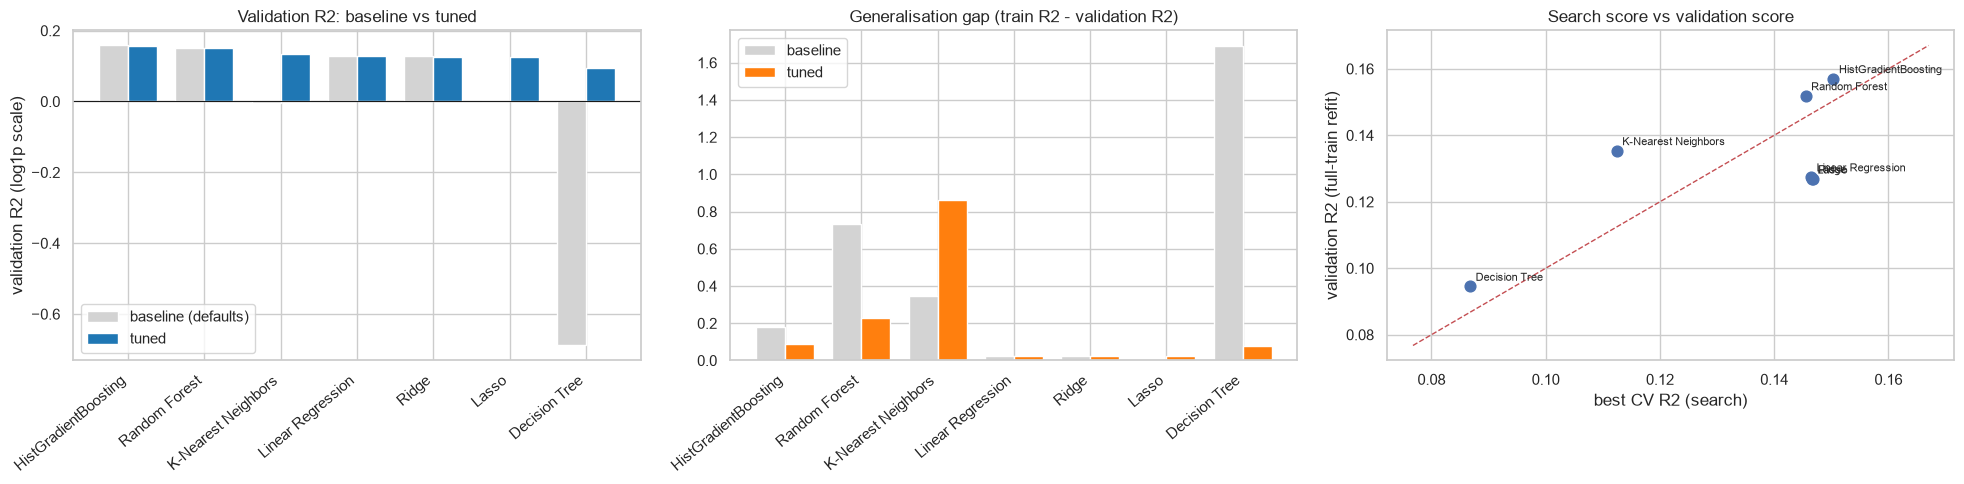

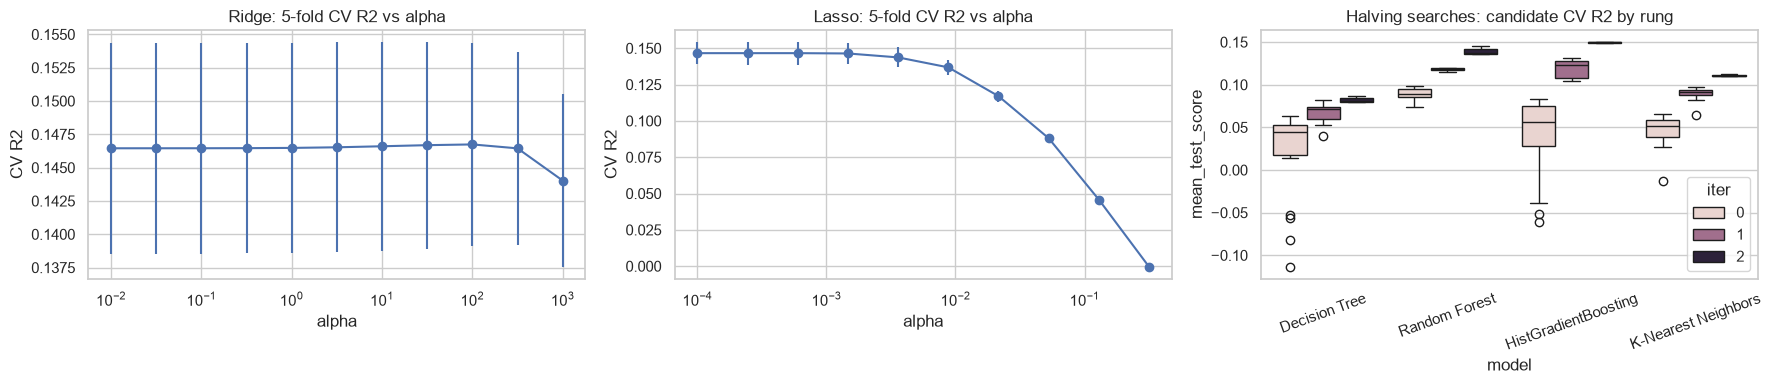

In [63]:
order = list(tuned.index)
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
w = 0.38; xs = np.arange(len(order))
ax[0].bar(xs - w/2, tuned.baseline_val_R2, w, label='baseline (defaults)', color='lightgrey'); ax[0].bar(xs + w/2, tuned.tuned_val_R2, w, label='tuned', color='tab:blue')
ax[0].set_xticks(xs); ax[0].set_xticklabels(order, rotation=40, ha='right'); ax[0].axhline(0, color='k', lw=.8); ax[0].set_ylabel('validation R2 (log1p scale)'); ax[0].set_title('Validation R2: baseline vs tuned'); ax[0].legend()
ax[1].bar(xs - w/2, tuned.baseline_train_R2 - tuned.baseline_val_R2, w, label='baseline', color='lightgrey'); ax[1].bar(xs + w/2, tuned.tuned_gap, w, label='tuned', color='tab:orange')
ax[1].set_xticks(xs); ax[1].set_xticklabels(order, rotation=40, ha='right'); ax[1].set_title('Generalisation gap (train R2 - validation R2)'); ax[1].legend()
ax[2].scatter(tuned.cv_best_R2, tuned.tuned_val_R2, s=60)
for n_, r in tuned.iterrows(): ax[2].annotate(n_, (r.cv_best_R2, r.tuned_val_R2), fontsize=8, xytext=(4, 4), textcoords='offset points')
lim = [min(tuned.cv_best_R2.min(), tuned.tuned_val_R2.min()) - .01, max(tuned.cv_best_R2.max(), tuned.tuned_val_R2.max()) + .01]
ax[2].plot(lim, lim, 'r--', lw=1); ax[2].set_xlabel('best CV R2 (search)'); ax[2].set_ylabel('validation R2 (full-train refit)'); ax[2].set_title('Search score vs validation score')
plt.tight_layout(); save_fig(fig, 'tuned_vs_baseline.png'); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, nm in zip(ax[:2], ['Ridge', 'Lasso']):
    cv = TUNED[nm][1]['cv_results'].sort_values('param_model__alpha')
    a.errorbar(cv.param_model__alpha.astype(float), cv.mean_test_score, yerr=cv.std_test_score, marker='o'); a.set_xscale('log')
    a.set_title(f'{nm}: 5-fold CV R2 vs alpha'); a.set_xlabel('alpha'); a.set_ylabel('CV R2')
hv = [m for m in ['Decision Tree', 'Random Forest', 'HistGradientBoosting', 'K-Nearest Neighbors']]
data = pd.concat([TUNED[m][1]['cv_results'].assign(model=m)[['model', 'iter', 'mean_test_score']] for m in hv])
sns.boxplot(data=data, x='model', y='mean_test_score', hue='iter', ax=ax[2]); ax[2].set_title('Halving searches: candidate CV R2 by rung'); ax[2].tick_params(axis='x', rotation=20)
plt.tight_layout(); save_fig(fig, 'search_diagnostics.png'); plt.show()

**Observation:** Left: the tuned bars are at or above the baseline bars everywhere except the two ensembles, where they are equal within noise; the visible jumps are Lasso, KNN and the Decision Tree. Middle: tuning cuts the train-validation gap for the tree (1.69 → 0.075), the forest (0.73 → 0.23) and boosting (0.18 → 0.09); the KNN bar (0.86) is the distance-weighting artefact explained above. Right: for the ensembles the search CV R² and the validation R² sit close to the diagonal, for the linear models the validation score is about 0.02 below the CV score, for KNN above it. Second figure: Ridge's CV curve is flat (with wide fold error bars), Lasso's falls off from alpha ≈ 1e-2, and in the halving boxplots the spread of candidate scores narrows and the median rises with every rung, as successive halving intends.

In [64]:
# Reassemble the per-model reports from the JSON ledger (this is how a reviewer, or a resumed run, can reconstruct the tuning log)
led = json.load(open(LEDGER.path))
print('Ledger entries (stage-namespaced keys):', [k for k in led])
for k in led:
    if k.startswith(STAGE + '::') and k != STAGE + '::FINAL_TEST':
        print(NL + '=' * 100 + NL + k + '  (saved ' + led[k]['saved_at'] + ')')
        print(led[k]['report'])
tot = sum(v['search_seconds'] + v['refit_seconds'] for k, v in led.items() if k.startswith(STAGE + '::') and 'search_seconds' in v)
print(NL + f'Total tuning compute recorded in the ledger: {tot / 60:.1f} minutes on a single CPU')

Ledger entries (stage-namespaced keys): ['tune_regression::Linear Regression', 'tune_regression::Ridge', 'tune_regression::Lasso', 'tune_regression::Decision Tree', 'tune_regression::K-Nearest Neighbors', 'tune_regression::HistGradientBoosting', 'tune_regression::Random Forest']

tune_regression::Linear Regression  (saved 2026-10-16 12:52:48)
Linear Regression: grid search, 5-fold CV on 24,976 rows | 4 candidate evaluations (20 fits)
best params     : {'model__fit_intercept': False, 'model__positive': False}
CV best R2      : 0.1465   (search rows: 24,976)
validation R2   : tuned 0.1275 vs baseline 0.1275  (delta +0.0000)
validation RMSE : tuned 0.8559 vs baseline 0.8559 (log scale)
train R2        : tuned 0.1520 (baseline 0.1520) -> generalisation gap 0.0245
time            : search 52s + refit on full training split 2s

tune_regression::Ridge  (saved 2026-10-16 12:53:52)
Ridge: grid search, 5-fold CV on 24,976 rows | 11 candidate evaluations (55 fits)
best params     : {'model__alpha

**Observation:** The seven per-model reports were reassembled from `ledger.json` alone (the keys are stage-namespaced, `tune_regression::<model>`), the same information printed by the tuning cells. The recorded tuning compute is **12.9 minutes** on a single CPU (about 773 s of search plus refits). Because every finished model has its own pickle and JSON entry, a kernel restart during, say, the forest search would only repeat that search.

## 23. Final model selection and the one-time test-set evaluation
**Selection rule (fixed in advance):** among the tuned models, take the one with the highest **validation R²** (log scale). The test split is then used **once**: the chosen configuration is refit on train + validation (30,328 rows; the preprocessing is re-fitted on those rows too) and predicts the test split a single time. In the same cell, two *reference* models (the naive benchmark and the default-parameter version of the same model, both refit on train + validation) are scored on the test split for context only; they take no part in the selection. The result is stored in the ledger, so a re-run reuses it instead of evaluating on the test set again.

In [65]:
final_name = tuned.index[0]
final_params = TUNED[final_name][0]['best_params']
print('Selected model :', final_name)
print('Best params    :', final_params)
print(f"Validation R2  : {tuned.loc[final_name, 'tuned_val_R2']:.4f} (runner-up {tuned.index[1]}: {tuned.iloc[1].tuned_val_R2:.4f}, difference {tuned.loc[final_name, 'tuned_val_R2'] - tuned.iloc[1].tuned_val_R2:.4f})")
display(tuned[['tuned_val_R2', 'tuned_val_RMSE', 'tuned_gap', 'cv_best_R2', 'rank_tuned_val_R2']])

Selected model : HistGradientBoosting
Best params    : {'model__l2_regularization': 0.09565499215943825, 'model__learning_rate': 0.021648036763001914, 'model__max_iter': 305, 'model__max_leaf_nodes': 24, 'model__min_samples_leaf': 183}
Validation R2  : 0.1570 (runner-up Random Forest: 0.1519, difference 0.0051)


,tuned_val_R2,tuned_val_RMSE,tuned_gap,cv_best_R2,rank_tuned_val_R2
model,,,,,
HistGradientBoosting,0.1570,0.8413,0.0902,0.1504,1
Random Forest,0.1519,0.8438,0.2281,0.1455,2
K-Nearest Neighbors,0.1354,0.8520,0.8646,0.1124,3
Linear Regression,0.1275,0.8559,0.0245,0.1465,4
Ridge,0.1269,0.8562,0.0248,0.1467,5
Lasso,0.1268,0.8562,0.0246,0.1466,6
Decision Tree,0.0945,0.8719,0.0753,0.0868,7


**Observation:** The pre-declared rule (highest validation R²) selects the tuned **HistGradientBoosting** (validation R² 0.1570, RMSE 0.841; learning rate 0.022, 305 iterations, 24 leaves, `min_samples_leaf` 183, L2 0.096). Its lead over the runner-up, the tuned Random Forest (0.1519), is 0.005, small enough that either would be a defensible production choice; boosting is also faster to refit and has the smaller generalisation gap (0.09 vs 0.23).

In [66]:
FINAL_KEY = CheckpointLedger.key(STAGE, 'FINAL_TEST')
final_fp = hashlib.md5(json.dumps(dict(model=final_name, params=final_params, n_trval=len(X_train) + len(X_val), seed=SEED, version=PIPELINE_VERSION), sort_keys=True).encode()).hexdigest()
if LEDGER.has(FINAL_KEY, final_fp):
    final_rec, final_obj = LEDGER.load(FINAL_KEY)
    print('[test result resumed from the ledger: the test split is NOT evaluated a second time]')
else:
    X_trval, y_trval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
    final_pipe = clone(make_model_pipeline(final_name)).set_params(**final_params).fit(X_trval, y_trval)
    pred_test = final_pipe.predict(X_test)                                                   # <- the one and only test-set evaluation of the final model
    ref_naive = clone(make_model_pipeline('Naive benchmark (train mean)')).fit(X_trval, y_trval).predict(X_test)
    ref_base = clone(make_model_pipeline(final_name)).fit(X_trval, y_trval).predict(X_test)  # default-parameter version of the same model (reference only)
    met = {k: reg_metrics(y_test, p, 'test') for k, p in [('final', pred_test), ('baseline_same_model', ref_base), ('naive', ref_naive)]}
    ids = raw.loc[X_test.index, 'ID'].values
    final_rec = dict(model=final_name, params=final_params, n_train_final=len(X_trval), n_test=len(X_test), metrics=met)
    final_obj = dict(pipeline=final_pipe, pred_test=pred_test, ref_naive=ref_naive, ref_base=ref_base, test_ids=ids)
    LEDGER.save(FINAL_KEY, final_rec, final_obj, final_fp)
    print('[test set evaluated once; stored in the ledger]')
pred_test, ref_naive, ref_base = final_obj['pred_test'], final_obj['ref_naive'], final_obj['ref_base']
M = final_rec['metrics']
tab = pd.DataFrame({'Naive benchmark (reference)': M['naive'], f'{final_name} - library defaults (reference)': M['baseline_same_model'], f'{final_name} - TUNED (final)': M['final']})
tab.index = [i.replace('test_', '') for i in tab.index]
display(tab)

[test set evaluated once; stored in the ledger]


,Naive benchmark (reference),HistGradientBoosting - library defaults (reference),HistGradientBoosting - TUNED (final)
MAE_log,0.7161,0.6347,0.6331
MSE_log,0.8867,0.7354,0.7317
RMSE_log,0.9416,0.8576,0.8554
R2_log,-0.0000,0.1706,0.1747
MAE_raw,"2,516.9963","2,389.7370","2,387.0942"
MSE_raw,"83,765,205.6959","81,423,174.8891","81,504,738.5706"
RMSE_raw,"9,152.3333","9,023.4791","9,027.9975"
R2_raw,-0.0334,-0.0046,-0.0056


**Observation (test split, evaluated once after refitting on train + validation = 30,328 rows):**

| metric | naive benchmark | boosting, library defaults (reference) | **boosting, tuned (final)** |
|---|---|---|---|
| MAE (log) | 0.7161 | 0.6347 | **0.6331** |
| MSE (log) | 0.8867 | 0.7354 | **0.7317** |
| RMSE (log) | 0.9416 | 0.8576 | **0.8554** |
| R² (log) | −0.0000 | 0.1706 | **0.1747** |
| RMSE (raw shares) | 9,152 | 9,023 | 9,028 |
| R² (raw shares) | −0.0334 | −0.0046 | −0.0056 |

The final model explains about **17.5%** of the variance of log shares on unseen data and cuts the RMSE by 9.2% relative to the naive benchmark. The test R² (0.175) is a little higher than the validation R² (0.157): the final model saw 21% more training rows, and the two held-out sets are different samples; that is within the bootstrap uncertainty below. The test split was predicted exactly once for the final model (plus the two reference models in the same cell for context); the result is stored in the ledger, so a re-run reuses it. On raw counts all models are still at R² ≈ 0 (the tuned model −0.006, the defaults −0.005).

In [67]:
# Bootstrap 95% confidence intervals on the test split (resampling test rows, 1,000 times; predictions are fixed, so no refit)
yt = y_test.values; rb = np.random.default_rng(SEED)
def boot_stats(pred, idx):
    e = yt[idx] - pred[idx]
    return 1 - (e ** 2).sum() / ((yt[idx] - yt[idx].mean()) ** 2).sum(), np.sqrt((e ** 2).mean()), np.abs(e).mean()
B = 1000; idxs = rb.integers(0, len(yt), (B, len(yt)))
bs = {k: np.array([boot_stats(p, i) for i in idxs]) for k, p in [('final', pred_test), ('baseline_same_model', ref_base), ('naive', ref_naive)]}
rows = []
for k, lab in [('final', 'tuned (final)'), ('baseline_same_model', 'library defaults'), ('naive', 'naive benchmark')]:
    pt = {'final': pred_test, 'baseline_same_model': ref_base, 'naive': ref_naive}[k]
    point = boot_stats(pt, np.arange(len(yt)))
    for j, mname in enumerate(['R2', 'RMSE', 'MAE']):
        lo, hi = np.percentile(bs[k][:, j], [2.5, 97.5]); rows.append(dict(model=lab, metric=mname + ' (log1p scale)', point=point[j], ci95_low=lo, ci95_high=hi))
ci = pd.DataFrame(rows).set_index(['model', 'metric']); display(ci)
d_rmse = bs['naive'][:, 1] - bs['final'][:, 1]; d_base = bs['baseline_same_model'][:, 2 - 1] - bs['final'][:, 1]; d_r2 = bs['final'][:, 0] - bs['baseline_same_model'][:, 0]
print(f'Improvement in test RMSE (log) over the naive benchmark: {d_rmse.mean():.4f}  95% CI [{np.percentile(d_rmse, 2.5):.4f}, {np.percentile(d_rmse, 97.5):.4f}]')
print(f'Improvement in test RMSE (log) over the default-parameter model: {d_base.mean():.4f}  95% CI [{np.percentile(d_base, 2.5):.4f}, {np.percentile(d_base, 97.5):.4f}]')
print(f'Gain in test R2 over the default-parameter model: {d_r2.mean():.4f}  95% CI [{np.percentile(d_r2, 2.5):.4f}, {np.percentile(d_r2, 97.5):.4f}]')

point  ci95_low  ci95_high
model            metric                                         
tuned (final)    R2 (log1p scale)    0.1747    0.1563     0.1921
                 RMSE (log1p scale)  0.8554    0.8301     0.8788
                 MAE (log1p scale)   0.6331    0.6170     0.6481
library defaults R2 (log1p scale)    0.1706    0.1501     0.1884
                 RMSE (log1p scale)  0.8576    0.8324     0.8810
                 MAE (log1p scale)   0.6347    0.6186     0.6501
naive benchmark  R2 (log1p scale)   -0.0000   -0.0009    -0.0000
                 RMSE (log1p scale)  0.9416    0.9157     0.9659
                 MAE (log1p scale)   0.7161    0.6997     0.7330

Improvement in test RMSE (log) over the naive benchmark: 0.0862  95% CI [0.0764, 0.0957]
Improvement in test RMSE (log) over the default-parameter model: 0.0023  95% CI [-0.0006, 0.0052]
Gain in test R2 over the default-parameter model: 0.0044  95% CI [-0.0013, 0.0102]


**Observation (bootstrap over test rows, 1,000 resamples):** the final test R² is 0.175 with a 95% interval of **[0.156, 0.192]**, RMSE 0.855 [0.830, 0.879], MAE 0.633 [0.617, 0.648]. The improvement over the naive benchmark is clearly real: RMSE lower by 0.086, 95% CI [0.076, 0.096]. **The improvement from tuning over the library-default boosting model is not distinguishable from zero**: ΔRMSE 0.0023, 95% CI [−0.0006, 0.0052], ΔR² 0.0044, 95% CI [−0.0013, 0.0102]. This bootstrap only reflects test-set sampling (not the randomness of training), but the message agrees with the validation results: the default boosting model was already about as good as this feature set allows.

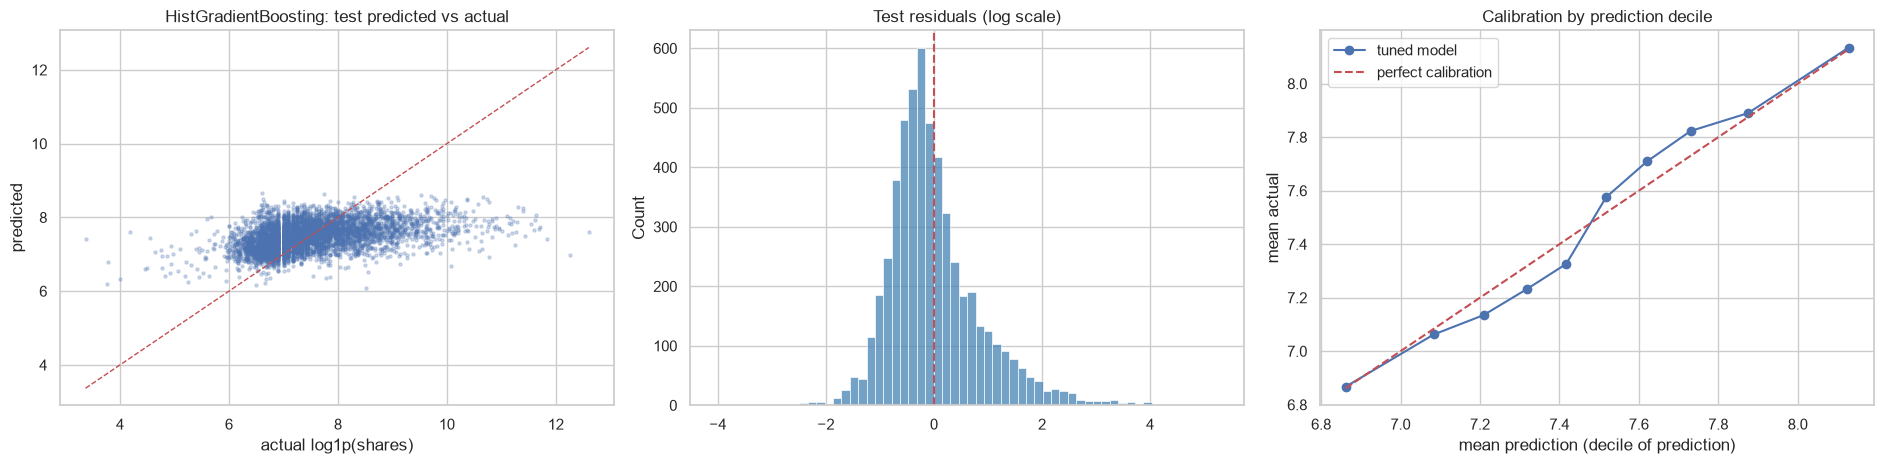

Test residuals: mean -0.001, sd 0.855, skew 1.10; share with |residual| > 1: 18.7%

Residuals by channel (mean residual > 0 = under-prediction):


,n,mean_residual,rmse
channel,,,
lifestyle,300,-0.1151,0.8681
world,1133,-0.0272,0.7412
entertainment,950,-0.0129,0.9164
business,854,-0.0006,0.7466
technology,954,0.0134,0.7480
unknown,850,0.0307,1.1133
social_media,311,0.1155,0.8151



Residuals by weekday (mean residual > 0 = under-prediction):


,n,mean_residual,rmse
weekday,,,
thursday,998,-0.0403,0.8633
tuesday,1018,-0.0361,0.8392
monday,867,-0.0127,0.8323
wednesday,946,0.0095,0.8772
saturday,325,0.0225,0.8583
friday,812,0.0505,0.8976
sunday,386,0.0711,0.7775


In [68]:
res = yt - pred_test
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
ax[0].scatter(yt, pred_test, s=5, alpha=.25); lim = [yt.min(), yt.max()]; ax[0].plot(lim, lim, 'r--', lw=1); ax[0].set_xlabel('actual log1p(shares)'); ax[0].set_ylabel('predicted'); ax[0].set_title(f'{final_name}: test predicted vs actual')
sns.histplot(res, bins=60, ax=ax[1], color='steelblue'); ax[1].axvline(0, color='r', ls='--'); ax[1].set_title('Test residuals (log scale)')
cal = pd.DataFrame({'pred': pred_test, 'actual': yt}); cal['bin'] = pd.qcut(cal.pred, 10, duplicates='drop'); cal = cal.groupby('bin', observed=True).agg(pred=('pred', 'mean'), actual=('actual', 'mean'), n=('actual', 'size'))
ax[2].plot(cal.pred, cal.actual, 'o-', label='tuned model'); ax[2].plot([cal.pred.min(), cal.pred.max()], [cal.pred.min(), cal.pred.max()], 'r--', label='perfect calibration'); ax[2].set_xlabel('mean prediction (decile of prediction)'); ax[2].set_ylabel('mean actual'); ax[2].set_title('Calibration by prediction decile'); ax[2].legend()
plt.tight_layout(); save_fig(fig, 'final_test_diagnostics.png'); plt.show()
print(f'Test residuals: mean {res.mean():.3f}, sd {res.std():.3f}, skew {stats.skew(res):.2f}; share with |residual| > 1: {(np.abs(res) > 1).mean():.1%}')
grp = pd.DataFrame({'res': res, 'channel': X_test.data_channel.fillna('unknown').values, 'weekday': X_test.weekday.values})
for g in ['channel', 'weekday']:
    t = grp.groupby(g).res.agg(n='size', mean_residual='mean', rmse=lambda s: np.sqrt((s ** 2).mean())).sort_values('mean_residual'); print(NL + f'Residuals by {g} (mean residual > 0 = under-prediction):'); display(t)

**Observation:** On the test split the predictions again occupy a narrow band (about 6-8.6 on the log scale) while actual values span roughly 3.5-12.6: the model cannot reach the tails. Residuals have mean −0.001 (unbiased), standard deviation 0.855, positive skew 1.10 (under-prediction of popular articles), and 18.7% of articles are off by more than one log unit (a factor of 2.7). The calibration curve follows the diagonal at both ends but sits slightly below it for predictions around 7.2-7.4 (over-prediction) and above it for 7.5-7.8 (under-prediction), a deviation of about 0.1 log units. By channel the mean residual runs from −0.115 (`lifestyle`, n = 300: over-predicted) to +0.116 (`social_media`, n = 311: under-predicted), roughly ±12% in shares; the `unknown` channel has by far the largest error (RMSE 1.11 against 0.74-0.75 for `world`, `business` and `technology`), consistent with its heavy tail found in the EDA. Mean residuals by weekday stay within about ±0.07, so there is no strong weekday bias.

## 24. Sensitivity checks (validation data only; the test split is not used)
Two checks listed in the Phase-1B plan, using the selected configuration and its library-default twin: (a) a **time-ordered split** (train on the oldest 70% of articles, validate on the next 15%; the newest 15% is left unused), which is a stricter test than a random split because articles are not exchangeable over time; (b) adding back the leakage-suspect **`n_comments`**, to show how much of any gain it would explain.

In [69]:
def val_r2(pipe_fn, tr_idx, va_idx, drop_leaky=True):
    p = pipe_fn(drop_leaky).fit(X_all.loc[tr_idx], y_log.loc[tr_idx])
    return r2_score(y_log.loc[va_idx], p.predict(X_all.loc[va_idx]))

tuned_fn = lambda dl: clone(make_model_pipeline(final_name, drop_leaky=dl)).set_params(**final_params)
default_fn = lambda dl: clone(make_model_pipeline(final_name, drop_leaky=dl))
order = raw.sort_values('timedelta', ascending=False).index          # oldest first (timedelta = days since publication)
n_all = len(order); t_tr, t_va = order[:int(.70 * n_all)], order[int(.70 * n_all):int(.85 * n_all)]
rows = [dict(scenario='random split, validation (main workflow)', defaults=results.loc[final_name, 'val_R2_log'], tuned=tuned.loc[final_name, 'tuned_val_R2']),
        dict(scenario='time-ordered split: train oldest 70% -> validate next 15%', defaults=val_r2(default_fn, t_tr, t_va), tuned=val_r2(tuned_fn, t_tr, t_va)),
        dict(scenario='random split + n_comments added back (leakage-suspect)', defaults=val_r2(default_fn, X_train.index, X_val.index, drop_leaky=False), tuned=val_r2(tuned_fn, X_train.index, X_val.index, drop_leaky=False))]
sens = pd.DataFrame(rows).set_index('scenario'); sens['tuned_minus_defaults'] = sens.tuned - sens.defaults
display(sens)
print('Time split target means (log1p): train', round(y_log.loc[t_tr].mean(), 3), '| validation', round(y_log.loc[t_va].mean(), 3))
sens.to_csv(os.path.join(OUT_DIR, 'sensitivity_checks.csv'))

,defaults,tuned,tuned_minus_defaults
scenario,,,
"random split, validation (main workflow)",0.1581,0.1570,-0.0011
time-ordered split: train oldest 70% -> validate next 15%,0.1734,0.1754,0.0020
random split + n_comments added back (leakage-suspect),0.4335,0.4334,-0.0001


Time split target means (log1p): train 7.503 | validation 7.456


**Observation (validation data only):** (a) With a time-ordered split (train on the oldest 70% of articles, validate on the next 15%) the R² is 0.173 for the default and 0.175 for the tuned boosting model, in line with the random-split value (0.158), so there is no sign that the random split hides a serious time-drift problem for this model (the validation target mean 7.456 is slightly below the training mean 7.503). (b) Adding the leakage-suspect `n_comments` back lifts R² to 0.433 for both default and tuned models, which is 0.28 more than any legitimate feature combination: that difference dwarfs anything hyper-parameter tuning does, and is the reason it stays excluded. Tuned and default models are within ±0.002 R² in all three scenarios.

## 25. Closing summary and saved outputs

Selected model: HistGradientBoosting  |  params: {'model__l2_regularization': 0.09565499215943825, 'model__learning_rate': 0.021648036763001914, 'model__max_iter': 305, 'model__max_leaf_nodes': 24, 'model__min_samples_leaf': 183}


,"baseline (defaults), validation","tuned, validation","FINAL tuned, TEST (train+val refit)","naive benchmark, TEST"
R2,0.1581,0.1570,0.1747,-0.0000
RMSE,0.8407,0.8413,0.8554,0.9416
MAE,0.6241,0.6231,0.6331,0.7161
MSE,0.7068,0.7077,0.7317,0.8867
R2 (raw shares),0.0005,-0.0018,-0.0056,-0.0334
RMSE (raw shares),"9,233.7981","9,244.1402","9,027.9975","9,152.3333"


,baseline_val_R2,tuned_val_R2,delta_R2,baseline_val_RMSE,tuned_val_RMSE,test_R2 (final model only)
model,,,,,,
HistGradientBoosting,0.1581,0.1570,-0.0011,0.8407,0.8413,0.1747
Random Forest,0.1500,0.1519,0.0019,0.8448,0.8438,NaN
K-Nearest Neighbors,-0.0048,0.1354,0.1402,0.9185,0.8520,NaN
Linear Regression,0.1275,0.1275,0.0000,0.8559,0.8559,NaN
Ridge,0.1274,0.1269,-0.0005,0.8559,0.8562,NaN
Lasso,-0.0000,0.1268,0.1268,0.9163,0.8562,NaN
Decision Tree,-0.6887,0.0945,0.7832,1.1907,0.8719,NaN


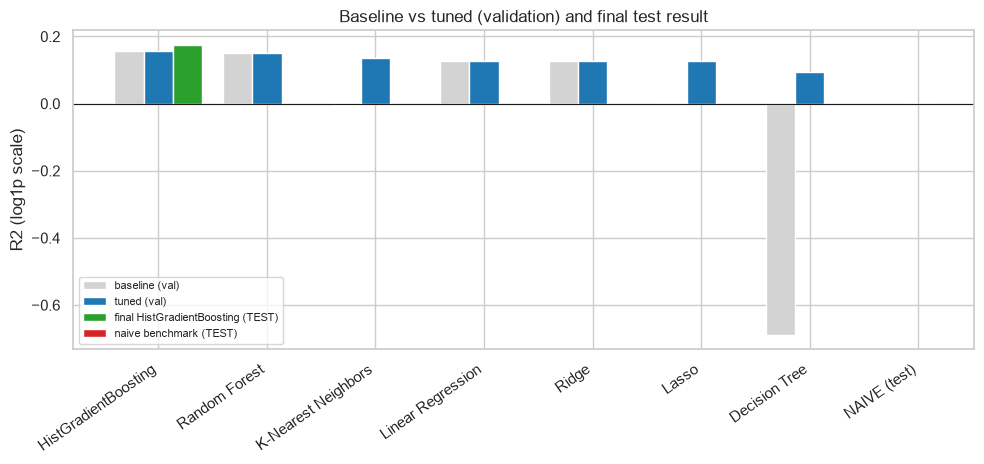

In [70]:
base_b, tuned_t = results.loc[final_name], tuned.loc[final_name]
naive_b = results.loc['Naive benchmark (train mean)']
summary = pd.DataFrame({
    'baseline (defaults), validation': {'R2': base_b.val_R2_log, 'RMSE': base_b.val_RMSE_log, 'MAE': base_b.val_MAE_log, 'MSE': base_b.val_MSE_log, 'R2 (raw shares)': base_b.val_R2_raw, 'RMSE (raw shares)': base_b.val_RMSE_raw},
    'tuned, validation': {'R2': tuned_t.tuned_val_R2, 'RMSE': tuned_t.tuned_val_RMSE, 'MAE': tuned_t.tuned_val_MAE, 'MSE': tuned_t.tuned_val_MSE, 'R2 (raw shares)': tuned_t.tuned_val_R2_raw, 'RMSE (raw shares)': tuned_t.tuned_val_RMSE_raw},
    'FINAL tuned, TEST (train+val refit)': {'R2': M['final']['test_R2_log'], 'RMSE': M['final']['test_RMSE_log'], 'MAE': M['final']['test_MAE_log'], 'MSE': M['final']['test_MSE_log'], 'R2 (raw shares)': M['final']['test_R2_raw'], 'RMSE (raw shares)': M['final']['test_RMSE_raw']},
    'naive benchmark, TEST': {'R2': M['naive']['test_R2_log'], 'RMSE': M['naive']['test_RMSE_log'], 'MAE': M['naive']['test_MAE_log'], 'MSE': M['naive']['test_MSE_log'], 'R2 (raw shares)': M['naive']['test_R2_raw'], 'RMSE (raw shares)': M['naive']['test_RMSE_raw']},
})
print(f'Selected model: {final_name}  |  params: {final_params}')
display(summary)

# every model: baseline validation -> tuned validation (final model additionally -> test)
allm = tuned[['baseline_val_R2', 'tuned_val_R2', 'delta_R2', 'baseline_val_RMSE', 'tuned_val_RMSE']].copy()
allm['test_R2 (final model only)'] = np.nan; allm.loc[final_name, 'test_R2 (final model only)'] = M['final']['test_R2_log']
display(allm)
summary.to_csv(os.path.join(OUT_DIR, 'comparison_summary.csv'))

fig, ax = plt.subplots(figsize=(10, 4.8))
labs = list(allm.index) + ['NAIVE (test)']; xs = np.arange(len(labs)); w = .27
ax.bar(xs[:-1] - w, allm.baseline_val_R2, w, label='baseline (val)', color='lightgrey'); ax.bar(xs[:-1], allm.tuned_val_R2, w, label='tuned (val)', color='tab:blue')
ax.bar([xs[list(allm.index).index(final_name)] + w], [M['final']['test_R2_log']], w, label=f'final {final_name} (TEST)', color='tab:green')
ax.bar([xs[-1]], [M['naive']['test_R2_log']], w, color='tab:red', label='naive benchmark (TEST)')
ax.set_xticks(xs); ax.set_xticklabels(labs, rotation=35, ha='right'); ax.axhline(0, color='k', lw=.8); ax.set_ylabel('R2 (log1p scale)'); ax.set_title('Baseline vs tuned (validation) and final test result'); ax.legend(fontsize=8)
plt.tight_layout(); save_fig(fig, 'closing_summary.png'); plt.show()

**Closing summary: baseline → tuned → final test (selected model: HistGradientBoosting).**

| | R² (log) | RMSE (log) | MAE (log) | MSE (log) |
|---|---|---|---|---|
| baseline (library defaults), validation | 0.1581 | 0.8407 | 0.6241 | 0.7068 |
| tuned, validation | 0.1570 | 0.8413 | 0.6231 | 0.7077 |
| **final tuned model, test** (train + validation refit) | **0.1747** | 0.8554 | 0.6331 | 0.7317 |
| naive benchmark, test | −0.0000 | 0.9416 | 0.7161 | 0.8867 |

1. **Tuning did not improve the best model.** Validation R² went from 0.1581 to 0.1570, and on the test split the tuned model beats its default-parameter twin by only 0.004 R² (95% CI includes 0). Tuning's real value was (a) repairing three models whose defaults were unsuitable (Lasso: 0 → 0.127; Decision Tree: −0.69 → 0.095; KNN: −0.005 → 0.135) and (b) reducing over-fitting (train-validation gap of the forest 0.73 → 0.23, boosting 0.18 → 0.09).
2. **Final performance:** about 17.5% of the variance of `log1p(shares)` (95% CI 0.156-0.192) and 9.2% lower RMSE than predicting the mean; on raw share counts R² is ≈ 0 (the viral tail is not predictable from these features).
3. **Validation and test numbers refer to different samples** (and the final model was refit on 21% more data), so the validation → test change in R² (0.157 → 0.175) is within the bootstrap noise and is not a tuning effect; the test-set comparison of the tuned and default models in the same cell is the fair one.
4. **Remaining caveats:** one random split and one seed for the validation comparisons; 3-fold CV and a 7,290-row subsample for the slow searches (a compute-driven shortcut that favours configurations that work well on small samples); `n_comments` is excluded as leakage-suspect; the model is calibrated only roughly in the middle of the range and is least reliable for the `unknown` and `social_media`/`lifestyle` channels.

The figure shows the same comparison for every model (validation baseline vs tuned) and the final test R² for the selected model and the naive benchmark.

In [71]:
# ---- everything a reviewer needs to replicate / audit the results, in ./outputs ----
tp = pd.DataFrame({'ID': final_obj['test_ids'], 'actual_shares': np.expm1(y_test.values), 'actual_log1p': y_test.values, 'pred_log1p': pred_test,
                   'pred_shares': np.expm1(np.clip(pred_test, 0, 20)), 'residual_log1p': y_test.values - pred_test})
tp.to_csv(os.path.join(OUT_DIR, 'test_predictions.csv'), index=False)
final_out = dict(model=final_name, params=final_params, selection_rule='highest validation R2 on log1p(shares) among tuned models', n_train_final=final_rec['n_train_final'], n_test=final_rec['n_test'],
                 test_metrics=M['final'], reference_test_metrics=dict(default_params_same_model=M['baseline_same_model'], naive_benchmark=M['naive']),
                 bootstrap_ci95=ci.reset_index().to_dict('records'))
json.dump(jsonable(final_out), open(os.path.join(OUT_DIR, 'final_test_results.json'), 'w'), indent=1)
pd.DataFrame({k: v for k, v in [('tuned_final', M['final']), ('defaults_same_model', M['baseline_same_model']), ('naive', M['naive'])]}).to_csv(os.path.join(OUT_DIR, 'final_test_results.csv'))
joblib.dump(final_obj['pipeline'], os.path.join(OUT_DIR, 'final_model.joblib'))
json.dump(dict(train_ids=[int(i) for i in raw.loc[X_train.index, 'ID']], val_ids=[int(i) for i in raw.loc[X_val.index, 'ID']], test_ids=[int(i) for i in final_obj['test_ids']], seed=SEED, ratios='70/15/15'),
          open(os.path.join(OUT_DIR, 'split_ids.json'), 'w'))
sha = hashlib.sha256(open(DATA_PATH, 'rb').read()).hexdigest()
manifest = dict(created=time.strftime('%Y-%m-%d %H:%M:%S'), data_file=DATA_PATH, data_sha256=sha, n_rows_used=len(raw), seed=SEED, stage=STAGE, pipeline_version=PIPELINE_VERSION,
                python=platform.python_version(), pandas=pd.__version__, numpy=np.__version__, sklearn=sklearn.__version__,
                compute=dict(n_jobs=N_JOBS, threads=1, cpus_assumed=1, subsample_n=SUBSAMPLE_N, min_resources=MIN_RESOURCES, halving_factor=HALVING_FACTOR, cv_linear=CV_LINEAR, cv_slow=CV_SLOW, scoring=SCORING),
                selected_model=final_name, tuning_minutes=float(sum(v['search_seconds'] + v['refit_seconds'] for k, v in LEDGER.data.items() if 'search_seconds' in v)),
                files=sorted(os.listdir(OUT_DIR)))
json.dump(jsonable(manifest), open(os.path.join(OUT_DIR, 'run_manifest.json'), 'w'), indent=1)
readme = f'''# Outputs of the news-popularity (shares) modelling notebook

Produced by EDA.ipynb (Sections 16-25). Target: log1p(shares). Selected model: {final_name}.

| file | content |
|---|---|
| baseline_results.csv | Phase 1B: default-hyper-parameter baselines, train/validation metrics (log and raw scale) |
| tuned_results.csv | Phase 1C: tuned models, validation metrics, CV score, best parameters, timings |
| best_params.json | best hyper-parameters per model |
| search_spaces.json | search spaces, CV folds, subsample size and halving settings |
| cv_results_<model>.csv | CV results of every candidate evaluated in each search |
| comparison_summary.csv | baseline vs tuned (validation) vs final (test) for the selected model |
| final_test_results.json / .csv | test metrics of the final model (+ naive and default-parameter references), bootstrap 95% CIs |
| test_predictions.csv | test-set IDs, actual and predicted values |
| final_model.joblib | the fitted final pipeline (train+validation) |
| sensitivity_checks.csv | time-ordered split and n_comments sensitivity (validation data only) |
| split_ids.json | IDs of the train / validation / test rows (seed {SEED}, 70/15/15) |
| run_manifest.json | library versions, seed, compute settings, SHA-256 of the data file, timings |
| checkpoints/ | resumable ledger (ledger.json) + pickled fitted states, keys namespaced '<stage>::<model>' |
| figures/ | PNG copies of the key tuning / final-evaluation plots |

Reproduce: place mini_project_1_data.csv in ./data, run EDA.ipynb top to bottom (delete outputs/checkpoints for a clean run;
leave it to resume an interrupted run). Test metrics are computed exactly once and stored in the ledger.
'''
open(os.path.join(OUT_DIR, 'README.md'), 'w').write(readme)
files = []
for root, _, fs in os.walk(OUT_DIR):
    for f in fs: files.append((os.path.relpath(os.path.join(root, f), OUT_DIR), os.path.getsize(os.path.join(root, f))))
display(pd.DataFrame(sorted(files), columns=['file', 'bytes']).set_index('file'))
# round-trip check: reload the saved model and reproduce the stored test predictions
reloaded = joblib.load(os.path.join(OUT_DIR, 'final_model.joblib'))
print('saved model reproduces stored test predictions:', bool(np.allclose(reloaded.predict(X_test), pred_test)))

,bytes
file,
README.md,1721
baseline_results.csv,3132
best_params.json,874
checkpoints\0914f57e_tune_regression_Lasso.pkl,53086
checkpoints\5f79e605_tune_regression_HistGradientBoosting.pkl,962859
checkpoints\7e88fe88_tune_regression_Linear_Regression.pkl,53481
checkpoints\88d7b821_tune_regression_Decision_Tree.pkl,72199
checkpoints\8b1c2d2b_tune_regression_K_Nearest_Neighbors.pkl,13242512
checkpoints\9b46658d_tune_regression_FINAL_TEST.pkl,1059213


saved model reproduces stored test predictions: True


**Observation:** `./outputs` now holds everything needed to audit or replicate the results: baseline, tuned and final test metrics (CSV/JSON), best parameters and the exact search spaces, the CV results of every candidate in each search, the test predictions with IDs, the split IDs (seed 42, 70/15/15), the fitted final pipeline (`final_model.joblib`), sensitivity results, the four key figures, a run manifest (library versions, compute settings, SHA-256 of the data file, tuning time) and a README describing each file. The checkpoint folder (`ledger.json` plus one pickle per model and one for the single test evaluation) lets an interrupted run resume. The final check passes: the saved model, reloaded from disk, reproduces the stored test predictions exactly.

## 26. Glossary of statistical terms

| Term | Meaning (as used in this notebook) |
|---|---|
| **Skewness** | Asymmetry of a distribution. 0 = symmetric; positive = long right tail; negative = long left tail. |
| **Kurtosis (excess)** | Tail heaviness relative to a normal distribution (excess kurtosis 0). Large positive = extreme values far more common than in a normal. |
| **Quantile / percentile / IQR** | The value below which a given share of data falls; IQR = Q3 − Q1 (the middle 50%). |
| **1.5×IQR / 3×IQR fence** | Rules of thumb flagging points beyond Q3 + 1.5·IQR ("outliers") or 3·IQR ("extreme"). |
| **Geometric mean** | exp(mean of log values); the "typical" value of a multiplicative quantity, less sensitive to outliers than the mean. |
| **Pearson correlation (r)** | Strength of the *linear* association between two variables (−1 to 1); sensitive to outliers. |
| **Spearman correlation (ρ)** | Pearson correlation of the ranks; measures any *monotonic* association; robust to outliers and unchanged by monotone transforms. |
| **Monotonic / non-monotonic** | Always going up (or down) as x increases vs changing direction (U-shape, threshold). |
| **R² / coefficient of determination** | Fraction of the variance of y explained by a model. |
| **Quadratic vs linear R² (ΔR²)** | Gain in R² from adding a squared term; a measure of curvature. |
| **Binned R² (step-function R²)** | R² of a model that predicts the mean of y within quantile bins of x; can capture thresholds and U-shapes. |
| **F-statistic / ANOVA** | Compares between-group variance to within-group variance to test if group means differ; also used to test an added model term. |
| **Eta-squared (η²)** | Share of total variance explained by group membership (SS_between / SS_total); an effect size. **Partial η²** is the share relative to the term plus residual. |
| **Kruskal–Wallis H** | Rank-based (non-parametric) alternative to one-way ANOVA. |
| **Mann–Whitney U** | Rank-based test of whether one group tends to have larger values than another. |
| **Rank-biserial correlation / Cliff's δ** | Effect size from Mann–Whitney U in [−1, 1]; (rb + 1)/2 is the probability a random member of group A exceeds one from group B. |
| **Cohen's d** | Difference in group means divided by the pooled standard deviation; ≈ 0.2 small, 0.5 medium, 0.8 large. |
| **Tukey HSD** | Post-hoc test comparing all pairs of group means while controlling the family-wise error rate. |
| **p-value** | Probability of data at least this extreme if there were no effect. With large n, tiny effects get tiny p-values, so effect sizes matter more. |
| **Confidence interval (CI) / bootstrap CI** | A plausible range for a statistic; the bootstrap builds it by resampling the data with replacement (1,000 resamples here). |
| **Interaction effect** | When the effect of one variable depends on the level of another (here weekday × channel). |
| **Additive model / residual from additivity** | A model with only main effects; the residual of a cell is how far it departs from "channel effect + weekday effect". |
| **z-score (cell deviation)** | Deviation divided by its standard error (≈ number of standard errors away from the additive expectation). |
| **Mutual information (MI)** | Non-parametric measure (in nats) of how much knowing one variable reduces uncertainty about another; catches non-linear and non-monotonic dependence. |
| **Collinearity / multicollinearity** | Predictors that are highly correlated with each other. |
| **MCAR / informative missingness** | Missing completely at random (missingness unrelated to anything) vs missingness that itself carries information about the target. |
| **Sentinel value** | A placeholder code (e.g. −1) used in place of a missing value. |
| **Data leakage** | A feature containing information about the target that would not be legitimately available at prediction time (or is derived from the target). |
| **log1p transform** | log(1 + x); compresses right-skewed non-negative data and handles zeros. |
| **Heavy tail** | Extreme values far more probable than under a normal distribution. |
| **Null (shuffled) comparison** | Re-computing a statistic after randomly permuting a column, to see what would be expected by chance. |
| **Train / validation / test split** | Disjoint parts of the data: the model is fitted on train, models are compared on validation, and the test set is used once at the end for an unbiased estimate. |
| **Stratified split** | A split that preserves class proportions; required for classification, not applicable to this regression problem. |
| **Pipeline** | A chain of preprocessing steps and a model that is fitted as one unit, so each step learns only from the data passed to `fit`. |
| **Transformer (scikit-learn)** | An object with `fit` and `transform` (and `get_feature_names_out`); custom ones here: `DataCleaner`, `FeatureEngineer`, `Winsorizer`. |
| **Imputation (median)** | Replacing missing values by the training median of that column. |
| **Missing-value indicator** | A 0/1 column recording that a value was missing (or a sentinel), so a model can use the missingness itself. |
| **Winsorizing / clipping** | Limiting values to chosen quantiles (here 1st and 99th) instead of deleting rows. |
| **Standardisation (z-score)** | Subtracting the training mean and dividing by the training standard deviation. |
| **One-hot encoding** | Representing a categorical column by one 0/1 column per level. |
| **Naive benchmark** | A model that ignores the features (here: predicts the training mean); any useful model must beat it. |
| **MAE / MSE / RMSE** | Mean absolute error, mean squared error, and its square root; RMSE is in the same units as the target and penalises large errors more than MAE. |
| **R² (validation)** | 1 − (model squared error / squared error of predicting the mean); 0 = no better than the mean, negative = worse than the mean. |
| **Overfitting / generalisation gap** | A model that fits training data far better than new data; the gap here = train R² − validation R². |
| **Regularisation (L1 / L2)** | A penalty on coefficient size (Lasso = L1, can set coefficients exactly to zero; Ridge = L2, shrinks them). |
| **Default hyper-parameters** | Settings fixed before training (tree depth, penalty strength, number of neighbours...), left at the library defaults for the baselines. |
| **Hyper-parameter tuning / cross-validation** | Searching those settings using repeated train/validation folds of the training data (planned for the next phase, not run). |
| **Decision tree / random forest / gradient boosting / KNN** | Tree = recursive splits; forest = average of many randomised trees; (histogram) gradient boosting = trees added one by one to correct earlier errors; KNN = predicts the average of the k most similar training rows. |
| **Permutation importance** | The drop in a score when one input column is randomly shuffled; a model-agnostic measure of how much the model relies on it. |
| **Kolmogorov-Smirnov test** | A test of whether two samples come from the same distribution (used to compare the splits). |
| **Random seed** | A fixed number that makes random operations (splits, forests) reproducible. |